# 09 · Drug classes: WHO's ATC codes per drug record

For anyone checking how Open Altio gives each drug a class. A class is a code of WHO's Anatomical Therapeutic Chemical (ATC) classification, which has five levels, from a body system down to one substance. Aspirin taken to thin the blood is B (blood), B01 (antithrombotic agents), B01A, B01AC (platelet aggregation inhibitors) and B01AC06; aspirin taken for pain is N02BA01, under N (nervous system). WHO classes a medicine by what it is used for, so one substance can have several codes. The class step reads our drug-to-class table (`mappings/faers/atc/classes.csv`, built from WHO's 2026 index) by the substance each drug record names. A record whose substance the table does not hold is read by FDA's own words on it, then, for a word that names only a group of drugs, by WHO's class for the group. The rules are `rules/atc-index.md`, `rules/atc-spelling-bridges.md`, `rules/atc-group-classes.md` and `rules/atc-class-choice.md`; the code is `src/open_altio/faers/atc/`. The notebook answers the questions asked of it section by section and ends with the **Decisions** they back.

**Substances.** The drug-name step is built (`rules/drug-names.md`, notebook 05), so this notebook reads each record's substance from the release's own `drug_substance_T` and makes no stand-in of its own. When the release carries the class tables (`atc_index_T`, `atc_drug_T`, `atc_drug_codes_T`) it reads them too; otherwise it runs the pipeline's own class step, `open_altio.faers.atc.layer.build`, on the release, so what is measured is what a release carries.

**Grain.** A **drug record** is one drug of one report in `drug_latest_T` (`era_T`, `primaryid`, `quarter_T`, `drug_seq`); since 2024Q4 FDA can write one record on several rows, one per dose. A **case** is a case of the default case set, the cases users see: `case_latest_T` where `dup_kept_T`, probable duplicates left out, as notebook 05 counts them. Every count is of those cases, or of the drug records of those cases, and a case counts once however many of its drugs fall in a group. The release's manifest counts the classes over every case, duplicates included, so its numbers (printed by the first cell) are a little larger. A drug is a **suspect** when FDA codes it PS (primary suspect) or SS (secondary suspect). "Quarter" is the quarter of the case's latest version.

**What it reads.** A release folder built by the command line (`open-altio demo` or `open-altio build`): `RELEASE` in the first code cell, or `OPEN_ALTIO_RELEASE`. For sections 5 and 6 only, DiAna's own ATC file, `ATC_binder_2025.csv` from the DiAna project on OSF ([zqu89](https://osf.io/zqu89/), CC BY 4.0), named by `OPEN_ALTIO_DIANA_ATC`; without it those two sections are skipped. For section 8's check of where its rows come from, the reviewed list of reported indications, `OPEN_ALTIO_INDICATION_LIST`. For section 9, the review's staged rows, `OPEN_ALTIO_STAGED_ROWS`, and WHO's index, `OPEN_ALTIO_WHO_DIR`, to build the table without the rows; without them section 9 is skipped. A release built without the drug names is read through the DiAna dictionary where `open-altio build` reads it (notebook 05). Each record's route is the one the route step reads (`drug_route_T`, `rules/drug-route.md`); a release built before the route step carries none, and the notebook builds it on its scratch database with the route step's own code (`open_altio.faers.route.build`), as notebook 11 does. Working tables go to a scratch DuckDB beside the executed notebook (`notebooks/out/`); nothing is written to the release.

Sections: 1 coverage, what the table misses and what 100% would mean; 2 combinations; 3 how one class is chosen, and whether it is right; 4 when the report does not say which use: the shared class, "can't tell", and our table's reading of WHO's product classes; 5 the cross-check against DiAna's ATC file; 6 substances only WHO's index codes; 7 what each bridge codes; the rules-page cards; Decisions, with what is left out and why; 8 the reason a drug was taken picks the class; 9 the new bridges and group classes; 10 the classes FDA's active ingredient gives skin care. Each section ends with one item per chart: what it **shows**, its **point**, and **so what** for a decision or the build, then a plain summary in two sentences. The numbers in the text are from a release built from every quarter FDA published, 2004Q1 to 2026Q2.

In [1]:
import os
import re
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from open_altio import rulebook
from open_altio.faers import route
from open_altio.faers.atc import layer
from open_altio.faers.atc.table import repo_path
from open_altio.faers.drugnames import dictionary, substances
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import (
    SERIES,
    label_bars,
    mark_quarters,
    out_dir,
    plot_card,
    quarter_ticks,
    setup,
    title,
    write_cards,
)
from open_altio.faers.insights.source import release_folder
from open_altio.faers.reader import quoted, read_manifest, register_release

setup(colwidth=70)


def backs(number, rule):
    return f"Backs decision {number}: rules/{rule}.md"


# The release this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
SOURCE = release_folder(RELEASE)
# DiAna's own ATC file, for sections 5 and 6 only; they are skipped without it
DIANA_ATC = os.environ.get("OPEN_ALTIO_DIANA_ATC")
DIANA_ATC = Path(DIANA_ATC).expanduser() if DIANA_ATC else None
WORK = out_dir() / "09_drug_classes"
WORK.mkdir(parents=True, exist_ok=True)
DB = WORK / f"{SOURCE.name}.duckdb"
if DB.exists():
    DB.unlink()  # rebuilt on every run, so the tables are always this release's
con = duckdb.connect(str(DB))
# other jobs share the machine
con.execute(
    "SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; "
    f"SET preserve_insertion_order = false; SET temp_directory = '{WORK / 'tmp'}'"
)


def q(sql):
    return con.execute(sql).fetchdf()


manifest = read_manifest(SOURCE)
tables = manifest["tables"]
# The class step reads each record's substance from a table of this database, so the release's
# drug_substance_T is copied in; every other table is a view over the release's Parquet.
register_release(
    con,
    SOURCE,
    tables={t: e for t, e in tables.items() if t not in (layer.SUBSTANCES, route.TABLE)},
    temporary=True,
)
if layer.SUBSTANCES in tables:
    substance_file = (SOURCE / tables[layer.SUBSTANCES]["path"]).as_posix()
    con.execute(
        f"CREATE TABLE {layer.SUBSTANCES} AS SELECT * FROM read_parquet({quoted(substance_file)})"
    )
    NAMES = manifest["drug_names"]
else:  # built without the drug names: the pipeline's step, run here on the release's drug rows
    NAMES = substances.build(con, dictionary.checked_file(dictionary.default_path()))
# Each record's route as the route step reads it: the release's own, else built here by its code.
if route.TABLE in tables:
    con.execute(
        f"CREATE TABLE {route.TABLE} AS SELECT * FROM read_parquet("
        f"{quoted((SOURCE / tables[route.TABLE]['path']).as_posix())})"
    )
else:
    route.build(con)
ROUTE_GROUPS = pd.DataFrame(
    sorted(route.RouteTables.read().atc_groups.items()), columns=["route_T", "group_T"]
)
con.register("routes_df", ROUTE_GROUPS)
# The classes: the release's own tables when it carries them, else the pipeline's step run here.
FROM_RELEASE = all(t in tables for t in layer.TABLES)
CLASSES = manifest["classes"] if FROM_RELEASE else layer.build(con)
assert CLASSES["present"], CLASSES

# One row per drug record of the default case set: its substance, FDA's role and its class.
con.execute("""
CREATE TABLE rec_T AS
WITH r AS (SELECT era_T, primaryid, quarter_T, drug_seq, any_value(role_cod) AS role_cod
           FROM drug_latest_T GROUP BY ALL)
SELECT r.*, r.role_cod IN ('PS', 'SS') AS suspect_T, s.substance_T, c.case_key_T,
       a.atc_code_T, a.atc_level_T, a.atc_chosen_by_T, a.atc_possible_codes_T, a.atc_matched_on_T
FROM r JOIN drug_substance_T s USING (era_T, primaryid, quarter_T, drug_seq)
JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
LEFT JOIN atc_drug_T a USING (era_T, primaryid, quarter_T, drug_seq)
WHERE c.dup_kept_T""")
CASES = con.execute("SELECT count(*) FROM case_latest_T WHERE dup_kept_T").fetchone()[0]
INDEX = rulebook.rule("atc-index").values
CHOICE = rulebook.rule("atc-class-choice").values
# our drug-to-class table: one row per substance (or ingredient set) and code, and the classes
TABLE = pd.read_csv(repo_path("atc-index", "table"), dtype=str, keep_default_na=False)
con.register("table_df", TABLE)
records, coded = con.execute("SELECT count(*), count(atc_chosen_by_T) FROM rec_T").fetchone()

print(
    "release:",
    SOURCE.name,
    "| WHO index",
    CLASSES["index_year"],
    "| table",
    CLASSES["table"]["path"],
    CLASSES["table"]["sha256"][:16],
    "| classes",
    "read from the release" if FROM_RELEASE else "built here by layer.build",
)
print(
    f"default case set: {CASES:,} cases, {records:,} drug records, {coded:,} of them with a WHO code"
)
pd.Series(CLASSES["cases"], name="the manifest's counts: every case, duplicates included")

release: 2026Q2-final-v3 | WHO index 2026 | table mappings/faers/atc/classes.csv 1230057d47291239 | classes read from the release
default case set: 20,296,780 cases, 73,228,779 drug records, 70,883,099 of them with a WHO code


with_a_coded_drug      20206153
with_a_class           19210266
with_a_shared_class      987056
with_cannot_tell        4425595
Name: the manifest's counts: every case, duplicates included, dtype: int64

## 1 · Coverage, what the table misses, and what 100% would mean

Three levels of coverage, from loosest to strictest. A drug record **has a WHO code** when its substance is in our table at all. It **has one class** when one class is known for it: its only code, the code its dose, route or indication chose, the class all its possible uses share (section 4), or the class of a group word (below). A record with a WHO code but two possible uses and nothing on the report to choose between them is "can't tell": it has a code, but no one class. A case counts when at least one of its drugs, or one of its suspect drugs, does; the suspect line is what a class filter counting suspects reaches (decision 8).

**Why a product cannot be matched.** The table is keyed by substance, as the DiAna dictionary writes it, and DiAna writes some substances as a group: Lantus, Humalog and even "insulin glargine" all become `insulin`, and ferrous sulfate becomes `iron`. WHO has no code for "insulin", only for insulin glargine (A10AE04), insulin lispro (A10AB04 and others), human insulin and the rest, so every record DiAna calls `insulin` has no class, though its brand names one exact insulin. FDA's own words on the record often say which: FDA's active-ingredient field (`prod_ai`) for Lantus reads "insulin glargine". So the class step reads FDA's words when the substance finds no code, and only then gives a group word WHO's class for the group (insulin A10A, iron B03A), marked as a group class (`rules/atc-group-classes.md`, section 9). The second chart counts what the group classes reach and what is still left without a code; its last table, how FDA's words coded DiAna's insulin and iron.

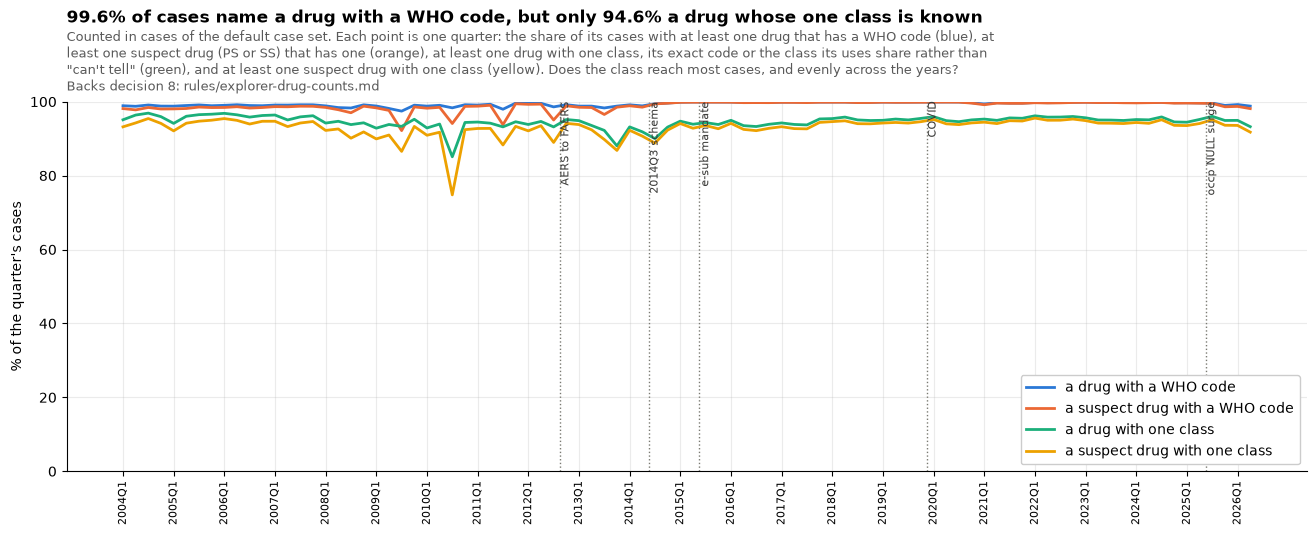

lowest quarter for a drug with a WHO code: 2009Q3 at 97.4%


,cases,% of all cases
a drug with a WHO code,20206153,99.55
a suspect drug with a WHO code,20152187,99.29
a drug with one class,19210266,94.65
a suspect drug with one class,18967450,93.45


,class,as_a_suspect,in_any_role,times
0,A02BC,256729,1221564,4.8
1,C10AA,236354,1122957,4.8
2,B01AC,300624,651681,2.2


In [2]:
cov = q("""
WITH r AS (SELECT era_T, primaryid, quarter_T,
                  bool_or(atc_chosen_by_T IS NOT NULL) AS coded_T,
                  bool_or(atc_chosen_by_T IS NOT NULL AND suspect_T) AS coded_suspect_T,
                  bool_or(atc_code_T IS NOT NULL) AS one_class_T,
                  bool_or(atc_code_T IS NOT NULL AND suspect_T) AS one_class_suspect_T
           FROM rec_T GROUP BY ALL)
SELECT c.quarter_T, count(*) AS cases,
       count(*) FILTER (WHERE r.coded_T) AS coded,
       count(*) FILTER (WHERE r.coded_suspect_T) AS coded_suspect,
       count(*) FILTER (WHERE r.one_class_T) AS one_class,
       count(*) FILTER (WHERE r.one_class_suspect_T) AS one_class_suspect
FROM case_latest_T c LEFT JOIN r USING (era_T, primaryid, quarter_T)
WHERE c.dup_kept_T GROUP BY 1 ORDER BY 1""")
MEASURES = ["coded", "coded_suspect", "one_class", "one_class_suspect"]
total = cov[["cases", *MEASURES]].sum()
share = {m: 100 * total[m] / total.cases for m in MEASURES}
p = cov.assign(**{m: 100 * cov[m] / cov.cases for m in MEASURES})
low = p.nsmallest(1, "coded").iloc[0]
fig, ax = plt.subplots(figsize=(16, 4.8))
x = np.arange(len(p))
ax.plot(x, p.coded, label="a drug with a WHO code", color=SERIES[0])
ax.plot(x, p.coded_suspect, label="a suspect drug with a WHO code", color=SERIES[1])
ax.plot(x, p.one_class, label="a drug with one class", color=SERIES[2])
ax.plot(x, p.one_class_suspect, label="a suspect drug with one class", color=SERIES[3])
ax.set_ylim(0, 100)
ax.set_ylabel("% of the quarter's cases")
quarter_ticks(ax, p.quarter_T)
mark_quarters(ax, p.quarter_T)
title(
    ax,
    f"{share['coded']:.1f}% of cases name a drug with a WHO code, but only {share['one_class']:.1f}% a drug whose "
    "one class is known",
    "Counted in cases of the default case set. Each point is one quarter: the share of its cases with at least one drug "
    "that has a WHO code (blue), at least one suspect drug (PS or SS) that has one (orange), at least one drug with one "
    'class, its exact code or the class its uses share rather than "can\'t tell" (green), and at least one suspect drug '
    "with one class (yellow).",
    "Does the class reach most cases, and evenly across the years?",
    backs(8, "explorer-drug-counts"),
    width=150,
)
ax.legend(loc="lower right", framealpha=1)
plt.show()
print(f"lowest quarter for a drug with a WHO code: {low.quarter_T.upper()} at {low.coded:.1f}%")
display(
    pd.DataFrame(
        {
            "cases": [int(total[m]) for m in MEASURES],
            "% of all cases": [round(share[m], 2) for m in MEASURES],
        },
        index=[
            "a drug with a WHO code",
            "a suspect drug with a WHO code",
            "a drug with one class",
            "a suspect drug with one class",
        ],
    )
)
# Why suspects by default: three classes many patients take alongside the drug the report is about,
# counted as a suspect drug and in any role
q("""SELECT left(atc_code_T, 5) AS class, count(DISTINCT case_key_T) FILTER (WHERE suspect_T) AS as_a_suspect,
            count(DISTINCT case_key_T) AS in_any_role
     FROM rec_T WHERE left(atc_code_T, 5) IN ('A02BC', 'C10AA', 'B01AC') GROUP BY 1 ORDER BY 3 DESC""").assign(
    times=lambda t: (t.in_any_role / t.as_a_suspect).round(1)
)

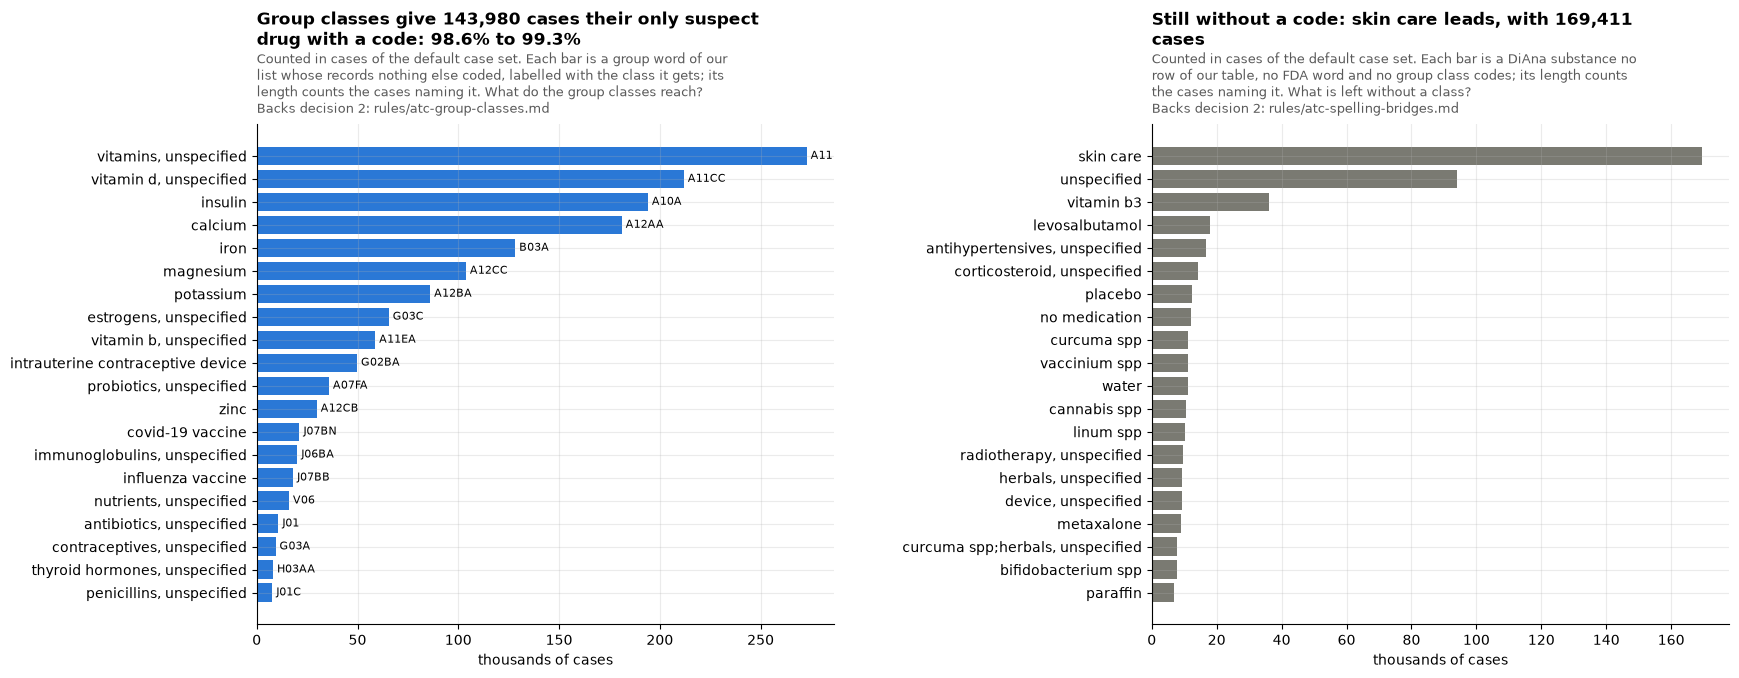

cases with a suspect drug with a WHO code: 20,008,207 without the group classes, 20,152,187 with them (+0.71 points); any drug: 99.01% -> 99.55%


,group_class,cases,suspect_cases,records
substance_T,,,,
"vitamins, unspecified",A11,272852,4213,280315
"vitamin d, unspecified",A11CC,211895,3835,215920
insulin,A10A,194075,62706,273906
calcium,A12AA,181076,6441,186445
iron,B03A,128226,24330,141275
magnesium,A12CC,103777,4096,107425
potassium,A12BA,86025,3167,89348
"estrogens, unspecified",G03C,65502,35083,75322
"vitamin b, unspecified",A11EA,58767,1061,60176


,records,prod_ai_names_a_who_substance,coded_by_fda_words,group_class,% named by prod_ai,% coded by FDA's words
substance_T,,,,,,
insulin,926803,645367,652897,273906,69.6,70.4
iron,218118,64349,76718,141275,29.5,35.2


most_common_prod_ai  records  prod_ai_names_a_who_substance  coded_by_fda_words  group_class
substance_T fda_drugname                                                                                                       
insulin     HUMALOG                     insulin lispro   149703                         130461              130461        19242
            LANTUS                    insulin glargine   136388                          92676               92676        43712
iron        IRON                                  iron    67235                              0                   0        67235
insulin     LANTUS SOLOSTAR           insulin glargine    61140                          55593               55593         5547
            INSULIN                        insulin nos    57060                              2                   2        57058
            NOVOLOG                     insulin aspart    54169                          43523               43523        10646
            LEVEMIR                    insulin detemir    39088                          31573               31573         7515
            BASAGLAR                  insulin glargine    37951                          37945               37945            6
            SOLOSTAR                            device    31014                              0                   0        31014
iron        FERROUS SULFATE            ferrous sulfate    29314                          20450               29314            0
            FERROUS SULFATE.           ferrous sulfate    20852                          20851               20852            0
            VENOFER                       iron sucrose     9584                              0                   0         9584
            FERROUS FUMARATE          ferrous fumarate     9490                           8334                9490            0
            FERROUS SULFATE TAB                    NaN     7857                              0                   0         7857
            FERROUS GLUCONATE        ferrous gluconate     6639                           5628                6639            0
            FERINJECT            ferric carboxymaltose     5839                              0                   0         5839

In [3]:
# The group words our list gives WHO's class for the group (rule atc-group-classes), and the
# substances still left without a code. A group class is given only where neither the substance
# nor FDA's own words on the record found a code.
from open_altio.faers.atc.table import read_groups

GROUP_CLASSES = read_groups()
groups = pd.DataFrame(
    [(s, c) for s, c in GROUP_CLASSES.items()], columns=["substance_T", "group_class"]
)
con.register("groups_df", groups)
given = q("""SELECT substance_T, atc_code_T AS group_class, count(DISTINCT case_key_T) AS cases,
                    count(DISTINCT case_key_T) FILTER (WHERE suspect_T) AS suspect_cases, count(*) AS records
             FROM rec_T WHERE atc_chosen_by_T = 'group_class' GROUP BY ALL ORDER BY 3 DESC""")
miss = q("""SELECT substance_T, count(DISTINCT case_key_T) AS cases,
                   count(DISTINCT case_key_T) FILTER (WHERE suspect_T) AS suspect_cases, count(*) AS records
            FROM rec_T WHERE atc_chosen_by_T IS NULL AND substance_T IS NOT NULL
            GROUP BY 1 ORDER BY 2 DESC LIMIT 20""")
lift = q("""WITH r AS (
  SELECT era_T, primaryid, quarter_T,
         bool_or(atc_chosen_by_T IS NOT NULL) AS any_T,
         bool_or(atc_chosen_by_T IS NOT NULL AND atc_chosen_by_T <> 'group_class') AS any_but_group_T,
         bool_or(suspect_T AND atc_chosen_by_T IS NOT NULL) AS suspect_any_T,
         bool_or(suspect_T AND atc_chosen_by_T IS NOT NULL AND atc_chosen_by_T <> 'group_class')
           AS suspect_but_group_T
  FROM rec_T GROUP BY ALL)
SELECT count(*) FILTER (WHERE any_but_group_T) AS any_drug_without, count(*) FILTER (WHERE any_T) AS any_drug_with,
       count(*) FILTER (WHERE suspect_but_group_T) AS suspect_without, count(*) FILTER (WHERE suspect_any_T) AS suspect_with
FROM r""").iloc[0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(19, 6.5), gridspec_kw={"wspace": 0.55})
top = given.head(20)
y = np.arange(len(top))
bars = a1.barh(y, top.cases / 1e3, color=SERIES[0])
a1.set_yticks(y)
a1.set_yticklabels(top.substance_T)
a1.invert_yaxis()
a1.set_xlabel("thousands of cases")
for b, code in zip(bars, top.group_class, strict=True):
    a1.text(b.get_width(), b.get_y() + b.get_height() / 2, f" {code}", va="center", fontsize=8)
gain = 100 * (lift.suspect_with - lift.suspect_without) / CASES
title(
    a1,
    f"Group classes give {lift.suspect_with - lift.suspect_without:,} cases their only suspect drug with a code: "
    f"{100 * lift.suspect_without / CASES:.1f}% to {100 * lift.suspect_with / CASES:.1f}%",
    "Counted in cases of the default case set. Each bar is a group word of our list whose records nothing else coded, "
    "labelled with the class it gets; its length counts the cases naming it.",
    "What do the group classes reach?",
    backs(2, "atc-group-classes"),
    width=75,
)
y = np.arange(len(miss))
a2.barh(y, miss.cases / 1e3, color=SERIES[6])
a2.set_yticks(y)
a2.set_yticklabels(miss.substance_T)
a2.invert_yaxis()
a2.set_xlabel("thousands of cases")
title(
    a2,
    f"Still without a code: {miss.substance_T.iloc[0]} leads, with {miss.cases.iloc[0]:,} cases",
    "Counted in cases of the default case set. Each bar is a DiAna substance no row of our table, no FDA word and no "
    "group class codes; its length counts the cases naming it.",
    "What is left without a class?",
    backs(2, "atc-spelling-bridges"),
    width=75,
)
plt.show()
print(
    f"cases with a suspect drug with a WHO code: {lift.suspect_without:,} without the group classes, "
    f"{lift.suspect_with:,} with them (+{gain:.2f} points); any drug: "
    f"{100 * lift.any_drug_without / CASES:.2f}% -> {100 * lift.any_drug_with / CASES:.2f}%"
)
display(given.head(20).set_index("substance_T"))
# Why FDA's own words come first: the names FDA publishes for DiAna's insulin and iron, what FDA's
# active-ingredient field (prod_ai) says, and how the class step matched those records
con.register("who_names_df", pd.DataFrame({"name_T": sorted(set(TABLE.ingredient) - {""})}))
prod = q("""WITH d AS (
  SELECT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, r.substance_T, any_value(r.atc_matched_on_T) AS matched_on_T,
         any_value(r.atc_chosen_by_T) AS chosen_by_T,
         any_value(upper(trim(d.drugname))) AS fda_drugname, any_value(lower(trim(d.prod_ai))) AS fda_prod_ai
  FROM rec_T r JOIN drug_latest_T d USING (era_T, primaryid, quarter_T, drug_seq)
  WHERE r.substance_T IN ('insulin', 'iron') GROUP BY ALL)
SELECT substance_T, fda_drugname, mode(fda_prod_ai) AS most_common_prod_ai, count(*) AS records,
       count(*) FILTER (WHERE fda_prod_ai IN (SELECT name_T FROM who_names_df)) AS prod_ai_names_a_who_substance,
       count(*) FILTER (WHERE matched_on_T IN ('drug_name', 'active_ingredient', 'active_ingredient_set')) AS coded_by_fda_words,
       count(*) FILTER (WHERE chosen_by_T = 'group_class') AS group_class
FROM d GROUP BY ALL""")
told = prod.groupby("substance_T")[
    ["records", "prod_ai_names_a_who_substance", "coded_by_fda_words", "group_class"]
].sum()
told["% named by prod_ai"] = (100 * told.prod_ai_names_a_who_substance / told.records).round(1)
told["% coded by FDA's words"] = (100 * told.coded_by_fda_words / told.records).round(1)
display(told)
prod.sort_values("records", ascending=False).groupby("substance_T").head(8).set_index(
    ["substance_T", "fda_drugname"]
)

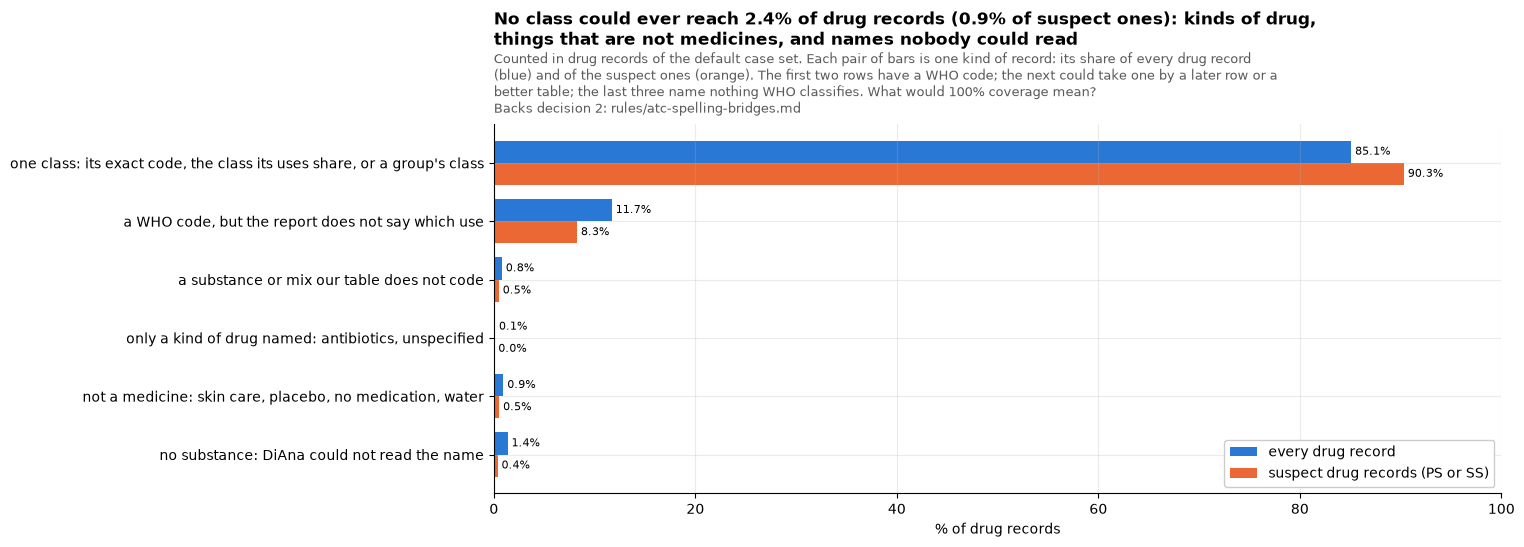

,records,suspect_records,% of records,% of suspect records
kind,,,,
"one class: its exact code, the class its uses share, or a group's class",62310358,37035203,85.09,90.32
"a WHO code, but the report does not say which use",8572741,3382980,11.71,8.25
a substance or mix our table does not code,579415,200022,0.79,0.49
"only a kind of drug named: antibiotics, unspecified",82599,19497,0.11,0.05
"not a medicine: skin care, placebo, no medication, water",686492,214529,0.94,0.52
no substance: DiAna could not read the name,997174,150459,1.36,0.37


In [4]:
# What 100% would mean: every drug record by what stands between it and one class. A short list of
# DiAna's words that name no medicine WHO classifies; DiAna's other words saying only a kind of
# drug ("antibiotics, unspecified") name no substance either.
NOT_MEDICINE = (
    "skin care",
    "placebo",
    "no medication",
    "no drug",
    "water",
    "unspecified",
    "radiotherapy, unspecified",
)
not_medicine = ", ".join(quoted(s) for s in NOT_MEDICINE)
KINDS = [
    "one class: its exact code, the class its uses share, or a group's class",
    "a WHO code, but the report does not say which use",
    "a substance or mix our table does not code",
    "only a kind of drug named: antibiotics, unspecified",
    "not a medicine: skin care, placebo, no medication, water",
    "no substance: DiAna could not read the name",
]
ceiling = (
    q(f"""SELECT CASE
    WHEN atc_code_T IS NOT NULL THEN {quoted(KINDS[0])}
    WHEN atc_chosen_by_T IS NOT NULL THEN {quoted(KINDS[1])}
    WHEN substance_T IS NULL THEN {quoted(KINDS[5])}
    WHEN substance_T IN ({not_medicine}) THEN {quoted(KINDS[4])}
    WHEN contains(substance_T, 'unspecified') AND NOT contains(substance_T, ';') THEN {quoted(KINDS[3])}
    ELSE {quoted(KINDS[2])} END AS kind,
  count(*) AS records, count(*) FILTER (WHERE suspect_T) AS suspect_records
FROM rec_T GROUP BY 1""")
    .set_index("kind")
    .loc[KINDS]
)
ceiling["% of records"] = 100 * ceiling.records / ceiling.records.sum()
ceiling["% of suspect records"] = 100 * ceiling.suspect_records / ceiling.suspect_records.sum()
out_of_reach = ceiling.loc[KINDS[3:]]
fig, ax = plt.subplots(figsize=(13, 4.8))
y = np.arange(len(KINDS))
h = 0.38
b1 = ax.barh(y - h / 2, ceiling["% of records"], h, color=SERIES[0], label="every drug record")
b2 = ax.barh(
    y + h / 2,
    ceiling["% of suspect records"],
    h,
    color=SERIES[1],
    label="suspect drug records (PS or SS)",
)
label_bars(ax, b1, "{:.1f}%", horizontal=True)
label_bars(ax, b2, "{:.1f}%", horizontal=True)
ax.set_yticks(y)
ax.set_yticklabels(KINDS)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of drug records")
ax.legend(loc="lower right", framealpha=1)
title(
    ax,
    f"No class could ever reach {out_of_reach['% of records'].sum():.1f}% of drug records "
    f"({out_of_reach['% of suspect records'].sum():.1f}% of suspect ones): kinds of drug, things that are not medicines, "
    "and names nobody could read",
    "Counted in drug records of the default case set. Each pair of bars is one kind of record: its share of every drug record "
    "(blue) and of the suspect ones (orange). The first two rows have a WHO code; the next could take one by a later row "
    "or a better table; the last three name nothing WHO classifies.",
    "What would 100% coverage mean?",
    backs(2, "atc-spelling-bridges"),
    width=120,
)
plt.show()
ceiling.round(2)

**What section 1 shows**, one item per chart:

- **Coverage by quarter.** *Shows:* in cases of the default case set: 99.55% name a drug with a WHO code and 99.29% a suspect drug with one; 94.65% name a drug with one class and 93.45% a suspect drug with one class. The lowest quarter for a WHO code is 2009Q3, at 97.4%. *Point:* a WHO code now reaches nearly every case; one class reaches fewer, because many drugs have two uses and the report often does not say which (sections 3, 4 and 8). *So what:* counts by class compare across the years. Why suspects, not any drug, by default (decision 8): a suspect is the drug the report is about, while a concomitant drug is one the patient also took. Counted in any role, proton pump inhibitors (A02BC) are in 1,221,550 cases against 256,722 as a suspect, and statins (C10AA) in 1,122,933 against 236,339 (the table after the chart), so a class filter over every role would mostly count background medicines.
- **What the group classes reach, and what is left.** *Shows:* in cases: the group classes give 143,966 cases their only suspect drug with a WHO code, from 98.6% of cases to 99.3%, and lift the cases with any coded drug from 99.01% to 99.55%. The largest group words are DiAna's vitamins (272,851 cases, A11), vitamin D (211,895, A11CC), insulin (194,069, A10A), calcium (181,075, A12AA) and iron (128,223, B03A). Still without a code, skin care leads (169,411 cases), then plain "unspecified" and vitamin B3, a word the review turned down (section 9). In the last table, FDA's own words code 70.4% of the records DiAna calls insulin (Humalog as insulin lispro, Lantus as insulin glargine), and the group class the rest; for iron, FDA's words code 35.2% (ferrous sulfate, fumarate and gluconate), and Venofer and Ferinject, whose active ingredients FDA writes in words WHO does not, take the group class. *Point:* why a product could not be matched: the gap was DiAna lumping products into a group WHO never codes, not drugs missing from WHO's index, and FDA's own words often name the exact product. *So what:* decision 2 as built: FDA's words first, then the group's class, marked as coarser.
- **What 100% would mean.** *Shows:* in drug records: 85.1% have one class (90.3% of suspect records) and 11.7% a WHO code with two possible uses the report does not tell apart; 0.8% are substances or mixes our table does not code, the rows the review turned down among them; 2.4% name nothing WHO classifies (0.9% of suspect records): only a kind of drug (0.1%), skin care, placebo, "no medication" or water (0.9%), or a name DiAna could not read (1.4%). *Point:* 100% coverage is not a meaningful target. The ceiling is about 97.6% of drug records and 99.1% of suspect ones; the rest are cosmetics, placebo, words that name only a kind of drug, and names nobody can read. *So what:* the methods page should state coverage against the records that name a medicine WHO classifies, with the out-of-reach share beside it.

Nearly every case now names a drug with a WHO code, since FDA's own words and the group classes reach DiAna's group names such as insulin and iron. What is left without a code is mostly what no class could ever reach: skin care, placebo, words that name only a kind of drug and names nobody can read.

## 2 · Combinations

A **combination** is one product with two or more ingredients, which DiAna writes as its ingredients sorted and joined with `;`. **Percocet** is oxycodone with paracetamol, `oxycodone;paracetamol`, and WHO codes that product as a whole: N02AJ17, *oxycodone and paracetamol*. Our table finds such a code through the whole set of ingredients, so every Percocet record gets N02AJ17.

A combination WHO has no code for, as our table reads it, is **split**: each ingredient's own codes are kept, and the record's class is "can't tell", because WHO classes a combination as a whole and neither ingredient's class need be the product's. **Mirena** shows why some products split that should not. DiAna writes it `intrauterine contraceptive device;levonorgestrel`. WHO does code it, as G02BA03, *plastic IUD with progestogen*, but in words that name no ingredient, so our matching cannot find it; split, its levonorgestrel part brings the codes of the contraceptive pill (G03AC03) and the morning-after pill (G03AD01), neither of which Mirena is. Decision 3 gave the largest such products their WHO code from a hand-checked list of rows (part B of section 9), so Mirena is now G02BA03; decision 4 keeps the rest "can't tell", with every ingredient's classes kept for the filter's "could be".

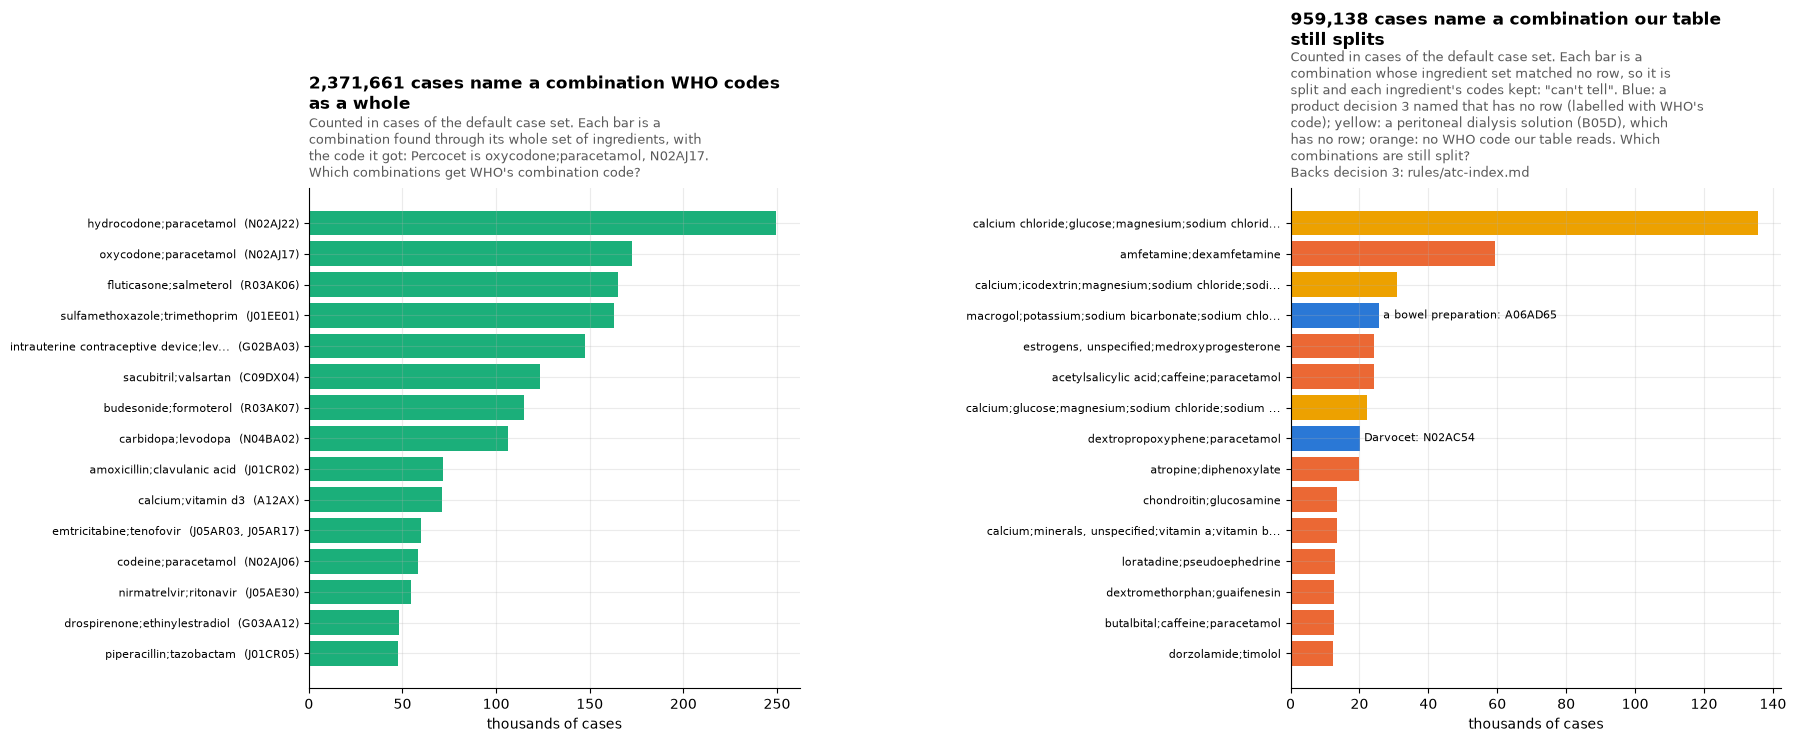

,,class_now,matched_on,cases
product,substance_T,,,
Darvocet,dextropropoxyphene;paracetamol,cannot_tell,each_ingredient,20206
Mirena,intrauterine contraceptive device;levonorgestrel,G02BA03,ingredient_set,147489
NuvaRing,ethinylestradiol;etonogestrel,G02BB01,ingredient_set,22470
Suboxone,buprenorphine;naloxone,N07BC51,ingredient_set,33104
a bowel preparation,macrogol;potassium;sodium bicarbonate;sodium chloride,cannot_tell,each_ingredient,25744
calcium with vitamin D,calcium;vitamin d3,A12AX,ingredient_set,71299


,records,cases
combination,,
coded as a whole,3347161,2371661
"split, no WHO code for the mix",967532,755525
"split, a peritoneal dialysis solution",314211,169082
no ingredient coded,73313,64821
"split, named by decision 3 but given no row",52032,45872


In [5]:
# Combinations WHO codes in words our matching did not read: the largest of the hand-checked rows of
# decision 3 (part B of section 9), with WHO's code and the product most reports name. Peritoneal
# dialysis solutions would take B05D; Darvocet, the bowel preparation and they have no row.
NAMED_MIXES = {
    "intrauterine contraceptive device;levonorgestrel": ("G02BA03", "Mirena"),
    "calcium;vitamin d3": ("A12AX", "calcium with vitamin D"),
    "buprenorphine;naloxone": ("N07BC51", "Suboxone"),
    "macrogol;potassium;sodium bicarbonate;sodium chloride": ("A06AD65", "a bowel preparation"),
    "ethinylestradiol;etonogestrel": ("G02BB01", "NuvaRing"),
    "dextropropoxyphene;paracetamol": ("N02AC54", "Darvocet"),
}
DIALYSIS = ("B05D", "sodium lactate")  # the class, and a word every dialysis solution's set holds
named = pd.DataFrame(
    [(s, c, p) for s, (c, p) in NAMED_MIXES.items()], columns=["substance_T", "who_code", "product"]
)
con.register("named_df", named)
kinds = q(f"""SELECT CASE WHEN atc_matched_on_T = 'ingredient_set' THEN 'coded as a whole'
                         WHEN atc_matched_on_T <> 'each_ingredient' OR atc_matched_on_T IS NULL THEN 'no ingredient coded'
                         WHEN substance_T IN (SELECT substance_T FROM named_df) THEN 'split, named by decision 3 but given no row'
                         WHEN contains(substance_T, {quoted(DIALYSIS[1])}) THEN 'split, a peritoneal dialysis solution'
                         ELSE 'split, no WHO code for the mix'
                    END AS combination,
                    count(*) AS records, count(DISTINCT case_key_T) AS cases
             FROM rec_T WHERE contains(substance_T, ';') GROUP BY 1 ORDER BY 2 DESC""").set_index(
    "combination"
)
whole = q("""SELECT r.substance_T, string_agg(DISTINCT k.atc_code_T, ', ' ORDER BY k.atc_code_T) AS code,
                    count(DISTINCT r.case_key_T) AS cases
             FROM rec_T r JOIN atc_drug_codes_T k USING (era_T, primaryid, quarter_T, drug_seq)
             WHERE r.atc_matched_on_T = 'ingredient_set' GROUP BY 1 ORDER BY 3 DESC LIMIT 15""")
split = q("""SELECT substance_T, count(DISTINCT case_key_T) AS cases FROM rec_T
             WHERE atc_matched_on_T = 'each_ingredient' GROUP BY 1 ORDER BY 2 DESC LIMIT 15""").merge(
    named, how="left"
)


def short(text, n=52):
    return text if len(text) <= n else text[: n - 3] + "..."


fig, (a1, a2) = plt.subplots(1, 2, figsize=(19, 6.5), gridspec_kw={"wspace": 1.0})
y = np.arange(len(whole))
a1.barh(y, whole.cases / 1e3, color=SERIES[2])
a1.set_yticks(y)
a1.set_yticklabels(
    [f"{short(s, 40)}  ({c})" for s, c in zip(whole.substance_T, whole.code, strict=True)],
    fontsize=8,
)
a1.invert_yaxis()
a1.set_xlabel("thousands of cases")
title(
    a1,
    f"{kinds.loc['coded as a whole', 'cases']:,} cases name a combination WHO codes as a whole",
    "Counted in cases of the default case set. Each bar is a combination found through its whole set of ingredients, "
    "with the code it got: Percocet is oxycodone;paracetamol, N02AJ17.",
    "Which combinations get WHO's combination code?",
    width=62,
)
color = np.where(
    split.who_code.notna(),
    SERIES[0],
    np.where(split.substance_T.str.contains(DIALYSIS[1]), SERIES[3], SERIES[1]),
)
y = np.arange(len(split))
bars = a2.barh(y, split.cases / 1e3, color=color)
a2.set_yticks(y)
a2.set_yticklabels([short(s) for s in split.substance_T], fontsize=8)
a2.invert_yaxis()
a2.set_xlabel("thousands of cases")
for b, code, product in zip(bars, split.who_code, split["product"], strict=True):
    if isinstance(code, str):
        a2.text(
            b.get_width(),
            b.get_y() + b.get_height() / 2,
            f" {product}: {code}",
            va="center",
            fontsize=8,
        )
split_cases = con.execute(
    "SELECT count(DISTINCT case_key_T) FROM rec_T WHERE atc_matched_on_T = 'each_ingredient'"
).fetchone()[0]
title(
    a2,
    f"{split_cases:,} cases name a combination our table still splits",
    "Counted in cases of the default case set. Each bar is a combination whose ingredient set matched no row, so it is "
    "split and each ingredient's codes kept: \"can't tell\". Blue: a product decision 3 named that has no row (labelled "
    f"with WHO's code); yellow: a peritoneal dialysis solution ({DIALYSIS[0]}), which has no row; orange: no WHO code our table reads.",
    "Which combinations are still split?",
    backs(3, "atc-index"),
    width=62,
)
plt.show()
# the hand-checked products, now coded whole through their rows
display(
    q("""SELECT n.product, r.substance_T, coalesce(r.atc_code_T, r.atc_chosen_by_T) AS class_now, r.atc_matched_on_T AS matched_on,
                count(DISTINCT r.case_key_T) AS cases
         FROM rec_T r JOIN named_df n USING (substance_T) GROUP BY ALL ORDER BY 1, 5 DESC""").set_index(
        ["product", "substance_T"]
    )
)
kinds

**What section 2 shows**, one item per chart:

- **Combinations coded whole, and combinations split.** *Shows:* in cases: 2,371,802 cases name a combination WHO codes as a whole, led by hydrocodone with paracetamol, Percocet's oxycodone with paracetamol (N02AJ17) and Advair's fluticasone with salmeterol; through the hand-checked rows, Mirena is now G02BA03 (147,489 cases), calcium with vitamin D A12AX (71,297), Suboxone N07BC51 (33,104) and NuvaRing G02BB01 (22,470). 959,032 cases name a combination our table still splits: 755,419 with no WHO code our table reads (Adderall's amfetamine with dexamfetamine, Excedrin's aspirin with caffeine and paracetamol), 169,082 a peritoneal dialysis solution, and 45,871 Darvocet or a bowel preparation, which decision 3 named but which have no row. A further 64,820 cases name a combination none of whose ingredients is coded. *Point:* what a combination is and why some are split: a product of several ingredients is classed as a whole or not at all. Mirena, which split into the pill codes of its hormone, now has WHO's code for the device. *So what:* decision 3 as built for the rows approved; Darvocet, the bowel preparation and the dialysis solutions need rows of their own; decision 4, the rest stay "can't tell", each ingredient's classes kept for the filter's "could be".

A product of two ingredients gets WHO's code when WHO codes the pair, as Percocet does; when it does not, the record says it cannot tell rather than borrow one ingredient's class. The hand-checked rows now give Mirena, calcium with vitamin D, Suboxone and NuvaRing their WHO codes.

## 3 · How one class is chosen, and whether it is right

Many substances have more than one WHO code, one per use or per kind of product: timolol is a heart drug as a tablet (C07AA06) and a glaucoma drug as eye drops (S01ED01); aspirin is a blood thinner at a low dose (B01AC06) and a painkiller at a full dose (N02BA01). The first chart counts how many substances in our table have two or more codes, and how much of FAERS they are.

Each record with a code then gets one class, in this order (`rules/atc-class-choice.md`): its **only code**; else its **dose**, when every dose it states meets a dose rule; else its **route**, as the route step reads it, when it is in a group and exactly one of its codes fits that group; else its **indication**, among the codes dose and route leave open (section 8); else **the class its uses share** (section 4); else **can't tell**. A record whose substance is a group word has its group's class as its one code.

**Counts of choices are not accuracy.** The second chart counts how often each way decided, not whether it decided right. To check that, the indication FDA's report gives for the drug (`indi_latest_T`) is read against the class chosen: an indication of rheumatoid arthritis means methotrexate's immunosuppressant code (L04AX03), not its cancer code (L01BA01). A short table, written for this check and not reviewed by a person, says which indications clearly mean one use of each substance with two or more; unclear ones (pain for a drug sold both as a gel and a tablet, "off label use") say nothing. It is a measuring aid, apart from the reviewed indication rows the class step reads (section 8).

**Why blood thinner or painkiller matters for aspirin.** WHO classes by use, so the class of an aspirin record says why the patient took it. Someone filtering FAERS on antithrombotics expects the low-dose aspirin that millions take for their heart; filed under painkillers, as one fixed code per substance would file it, those reports would be missing from that filter and swell the painkillers' count.

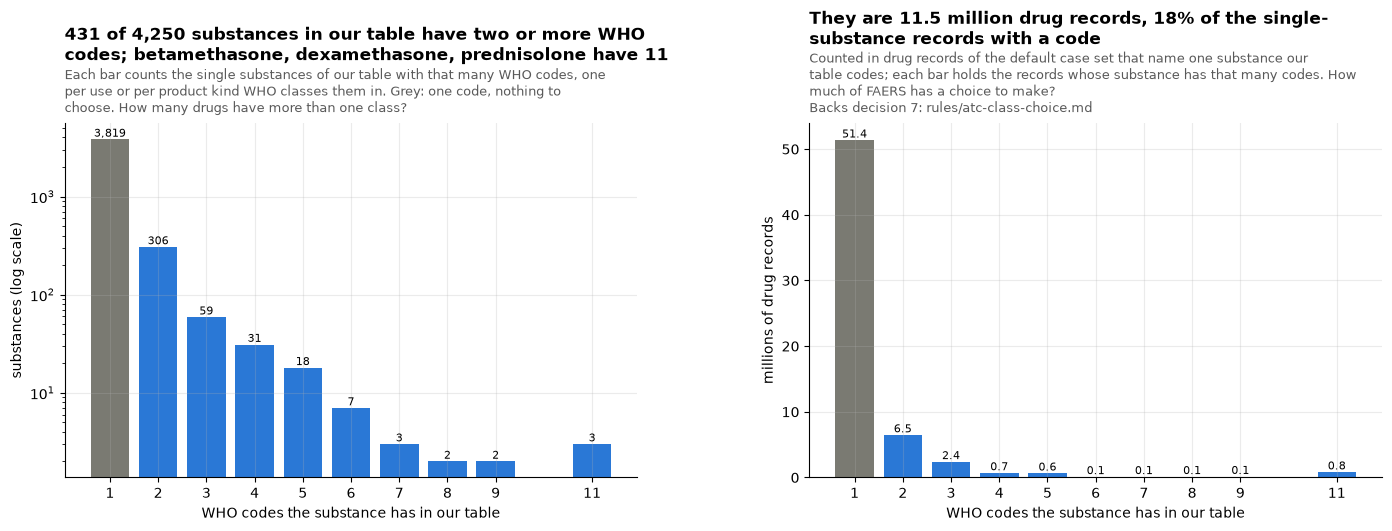

,substances,records,cases
codes,,,
1,3819,51359866,17214232
2,306,6470292,3671018
3,59,2393344,1808389
4,31,696701,548707
5,18,647153,550495
6,7,107080,95942
7,3,112079,96933
8,2,116182,92141
9,2,134131,98131


,codes,codes_it_can_take
ingredient,,
betamethasone,11,9.0
dexamethasone,11,8.0
prednisolone,11,9.0
hydrocortisone,9,7.0
neomycin,9,9.0
chlorhexidine,8,8.0
triamcinolone,8,7.0
chloramphenicol,7,7.0
lidocaine,7,7.0


In [6]:
# How many WHO codes each single substance has in our table, and the drug records that name it
single = TABLE[(TABLE.ingredient != "") & ~TABLE.ingredient.str.contains(";")]
n_codes = single.groupby("ingredient").atc_code.nunique().rename("codes").reset_index()
# a code under a class WHO keeps for mixes is never one a single ingredient takes (section 4)
for_mixes = single.atc_code.apply(lambda c: any(c.startswith(m) for m in CHOICE["mix_classes"]))
n_codes = n_codes.merge(
    single[~for_mixes]
    .groupby("ingredient")
    .atc_code.nunique()
    .rename("codes_it_can_take")
    .reset_index(),
    how="left",
).fillna({"codes_it_can_take": 0})
con.register("ncodes_df", n_codes)
by_n = q("""SELECT n.codes, count(DISTINCT n.ingredient) AS substances, count(r.substance_T) AS records,
                   count(DISTINCT r.case_key_T) AS cases
            FROM ncodes_df n LEFT JOIN rec_T r ON r.substance_T = n.ingredient AND r.atc_matched_on_T = 'substance'
            GROUP BY 1 ORDER BY 1""").set_index("codes")
multi = by_n.loc[by_n.index > 1]
coded_single = by_n.records.sum()
most = n_codes.sort_values(["codes", "ingredient"], ascending=[False, True]).head(12)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"wspace": 0.3})
b = a1.bar(
    by_n.index, by_n.substances, color=[SERIES[6] if n == 1 else SERIES[0] for n in by_n.index]
)
label_bars(a1, b)
a1.set_yscale("log")
a1.set_xticks(by_n.index)
a1.set_xlabel("WHO codes the substance has in our table")
a1.set_ylabel("substances (log scale)")
title(
    a1,
    f"{multi.substances.sum():,} of {by_n.substances.sum():,} substances in our table have two or more WHO codes; "
    f"{', '.join(most.ingredient[most.codes == most.codes.max()])} have {most.codes.max()}",
    "Each bar counts the single substances of our table with that many WHO codes, one per use or per product kind "
    "WHO classes them in. Grey: one code, nothing to choose.",
    "How many drugs have more than one class?",
    width=80,
)
b = a2.bar(
    by_n.index, by_n.records / 1e6, color=[SERIES[6] if n == 1 else SERIES[0] for n in by_n.index]
)
label_bars(a2, b, "{:.1f}")
a2.set_xticks(by_n.index)
a2.set_xlabel("WHO codes the substance has in our table")
a2.set_ylabel("millions of drug records")
title(
    a2,
    f"They are {multi.records.sum() / 1e6:.1f} million drug records, {100 * multi.records.sum() / coded_single:.0f}% "
    "of the single-substance records with a code",
    "Counted in drug records of the default case set that name one substance our table codes; each bar holds the "
    "records whose substance has that many codes.",
    "How much of FAERS has a choice to make?",
    backs(7, "atc-class-choice"),
    width=80,
)
plt.show()
display(by_n)
most.set_index("ingredient")

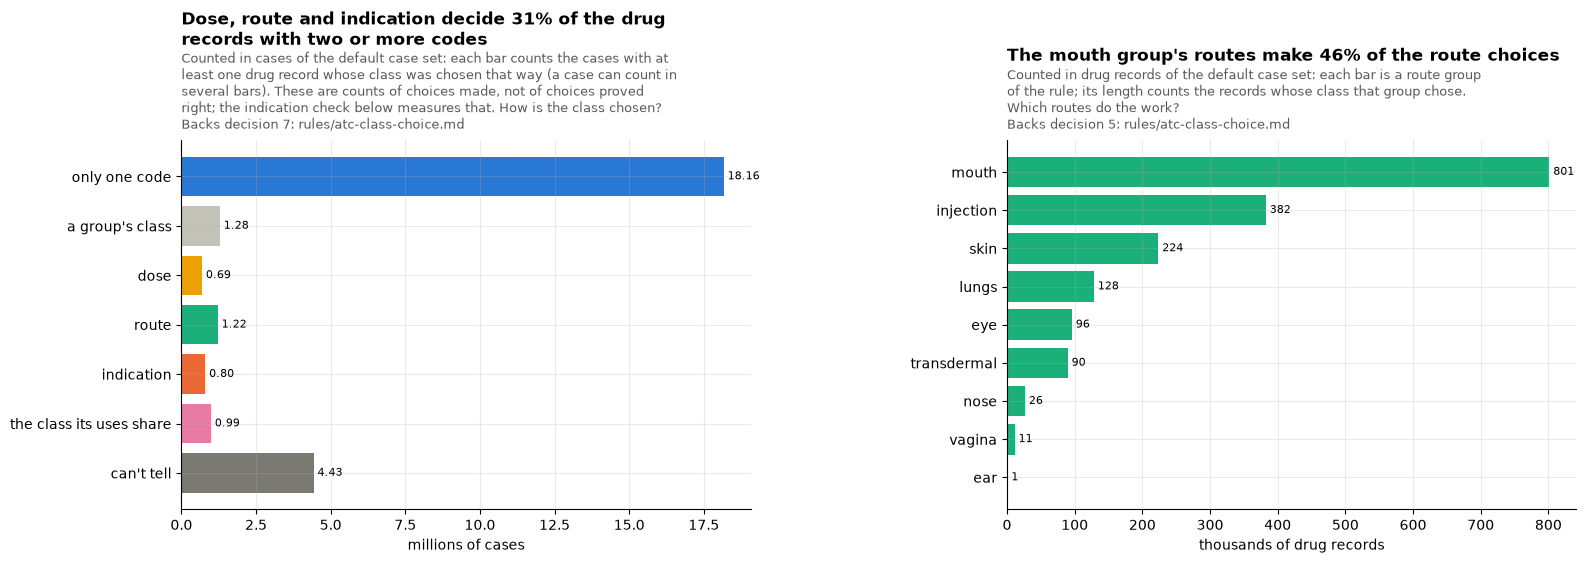

,records,cases,% of coded records
chosen_by,,,
only_code,55192327,18164502,77.86
group_class,1824696,1284671,2.57
dose,1009191,687517,1.42
route,1759173,1215951,2.48
indication,1151137,795301,1.62
shared_class,1373834,987056,1.94
cannot_tell,8572741,4425595,12.09


cases
substance_T        chosen_by    code           
bevacizumab        dose         L01FG01   43065
                   indication   L01FG01   33080
                   route        L01FG01   28319
                   cannot_tell  -         21905
                   indication   S01LA08    5132
                   route        S01LA08    2310
                   dose         S01LA08    1560
methylprednisolone cannot_tell  -         84597
                   route        H02AB04   73079
                   indication   H02AB04   37137
                   route        D07AA01     538
salbutamol         shared_class R03      346052
                   route        R03AC02   68752
                                R03CC02    6419
                   indication   R03AC02     314
tacrolimus         indication   L04AD02   69071
                   cannot_tell  -         46208
                   dose         L04AD02   43240
                   route        L04AD02   17252
                                D11AH01    3848
                   indication   D11AH01     643
timolol            cannot_tell  -         16002
                   route        S01ED01    5134
                   indication   S01ED01    2017
                   route        C07AA06     193

In [7]:
WAYS = ["only_code", "group_class", "dose", "route", "indication", "shared_class", "cannot_tell"]
WAY_COLOR = dict(
    zip(
        WAYS,
        [SERIES[0], SERIES[7], SERIES[3], SERIES[2], SERIES[1], SERIES[4], SERIES[6]],
        strict=True,
    )
)
chosen = (
    q("""SELECT atc_chosen_by_T AS chosen_by, count(*) AS records, count(DISTINCT case_key_T) AS cases
              FROM rec_T WHERE atc_chosen_by_T IS NOT NULL GROUP BY 1""")
    .set_index("chosen_by")
    .loc[WAYS]
)
# each record's route group: the group of the route the route step reads for it
bygroup = q("""SELECT x.group_T, count(*) AS records, count(DISTINCT r.case_key_T) AS cases
  FROM rec_T r JOIN drug_route_T d USING (era_T, primaryid, quarter_T, drug_seq)
  JOIN routes_df x ON x.route_T = d.route_T
  WHERE r.atc_chosen_by_T = 'route' GROUP BY 1 ORDER BY 2 DESC""")
open_records = con.execute(
    "SELECT count(*) FROM rec_T WHERE atc_possible_codes_T > 1 AND atc_matched_on_T <> 'each_ingredient'"
).fetchone()[0]
decided = chosen.loc[["dose", "route", "indication"], "records"].sum()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 4.8), gridspec_kw={"wspace": 0.45})
y = np.arange(len(WAYS))
b = a1.barh(y, chosen.cases / 1e6, color=[WAY_COLOR[w] for w in WAYS])
label_bars(a1, b, "{:.2f}", horizontal=True)
a1.set_yticks(y)
a1.set_yticklabels(
    [
        "only one code",
        "a group's class",
        "dose",
        "route",
        "indication",
        "the class its uses share",
        "can't tell",
    ]
)
a1.invert_yaxis()
a1.set_xlabel("millions of cases")
title(
    a1,
    f"Dose, route and indication decide {100 * decided / open_records:.0f}% of the drug records with two or more codes",
    "Counted in cases of the default case set: each bar counts the cases with at least one drug record whose class was "
    "chosen that way (a case can count in several bars). These are counts of choices made, not of choices proved right; "
    "the indication check below measures that.",
    "How is the class chosen?",
    backs(7, "atc-class-choice"),
    width=75,
)
y = np.arange(len(bygroup))
b = a2.barh(y, bygroup.records / 1e3, color=SERIES[2])
label_bars(a2, b, "{:,.0f}", horizontal=True)
a2.set_yticks(y)
a2.set_yticklabels(bygroup.group_T)
a2.invert_yaxis()
a2.set_xlabel("thousands of drug records")
title(
    a2,
    f"The {bygroup.group_T.iloc[0]} group's routes make {100 * bygroup.records.iloc[0] / bygroup.records.sum():.0f}% "
    "of the route choices",
    "Counted in drug records of the default case set: each bar is a route group of the rule; its length counts the "
    "records whose class that group chose.",
    "Which routes do the work?",
    backs(5, "atc-class-choice"),
    width=75,
)
plt.show()
display(
    chosen.assign(**{"% of coded records": (100 * chosen.records / chosen.records.sum()).round(2)})
)
# a few substances with two uses, and the class each way of choosing gave them
q("""SELECT substance_T, atc_chosen_by_T AS chosen_by, coalesce(atc_code_T, '-') AS code, count(DISTINCT case_key_T) AS cases
     FROM rec_T WHERE substance_T IN ('timolol', 'bevacizumab', 'methylprednisolone', 'tacrolimus', 'salbutamol')
     GROUP BY ALL ORDER BY 1, 4 DESC""").set_index(["substance_T", "chosen_by", "code"])

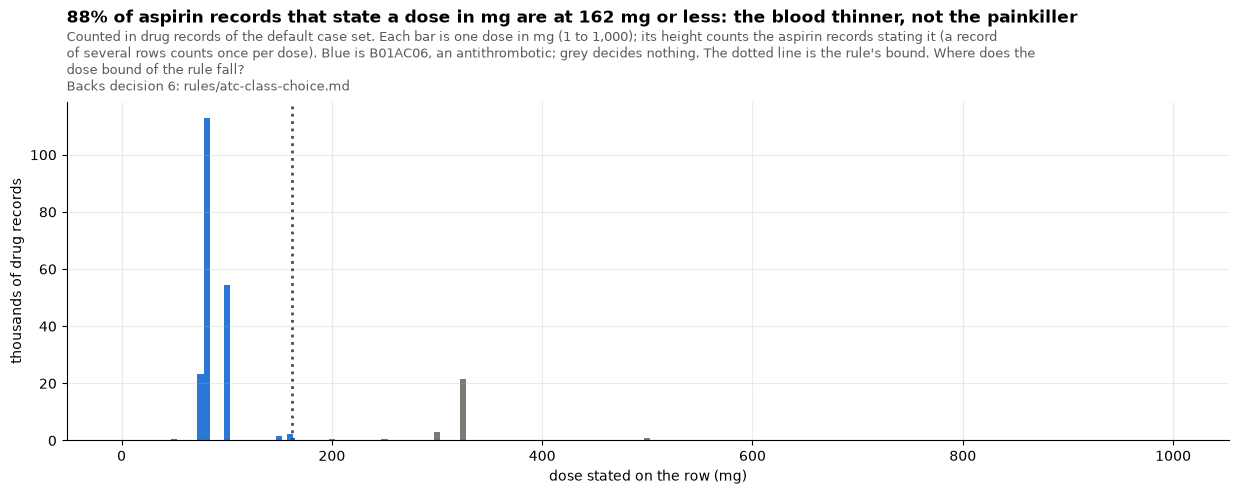

,substance_T,chosen_by,code,records,cases
0,acetylsalicylic acid,cannot_tell,-,575826,558811
1,acetylsalicylic acid,dose,B01AC06,205082,196995
2,acetylsalicylic acid,indication,B01AC06,54224,51048
3,acetylsalicylic acid,indication,N02BA01,7737,7184
4,finasteride,cannot_tell,-,38311,37556
5,finasteride,dose,G04CB01,12044,11496
6,finasteride,indication,G04CB01,4537,4399
7,finasteride,dose,D11AX10,4505,3925
8,finasteride,indication,D11AX10,4244,4071
9,finasteride,route,D11AX10,98,97


In [8]:
dose_rules = pd.DataFrame(CHOICE["dose_rules"])
low = dose_rules[
    (dose_rules.substance == "acetylsalicylic acid") & dose_rules.at_most.notna()
].iloc[0]
# each aspirin record's doses in mg, as the layer reads a dose: a number, in the rule's unit
asp = q(f"""WITH d AS (
  SELECT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, CAST(d.dose_amt AS DOUBLE) AS mg
  FROM rec_T r JOIN drug_latest_T d USING (era_T, primaryid, quarter_T, drug_seq)
  WHERE r.substance_T = 'acetylsalicylic acid' AND upper(trim(d.dose_unit)) = {quoted(low.unit)}
    AND regexp_full_match(d.dose_amt, '[0-9]*\\.?[0-9]+'))
SELECT mg, count(DISTINCT (era_T, primaryid, quarter_T, drug_seq)) AS records FROM d
WHERE mg BETWEEN 1 AND 1000 GROUP BY 1 ORDER BY 1""")
dosed = asp.records.sum()
under = asp[asp.mg <= low.at_most].records.sum()
fig, ax = plt.subplots(figsize=(15, 4.4))
ax.bar(
    asp.mg,
    asp.records / 1e3,
    width=6,
    color=[SERIES[0] if m <= low.at_most else SERIES[6] for m in asp.mg],
)
ax.axvline(low.at_most, color="0.3", ls=":")
ax.set_xlabel("dose stated on the row (mg)")
ax.set_ylabel("thousands of drug records")
title(
    ax,
    f"{100 * under / dosed:.0f}% of aspirin records that state a dose in mg are at {low.at_most:g} mg or less: "
    "the blood thinner, not the painkiller",
    f"Counted in drug records of the default case set. Each bar is one dose in mg (1 to 1,000); its height counts the "
    f"aspirin records stating it (a record of several rows counts once per dose). Blue is {low.code}, an antithrombotic; "
    "grey decides nothing. The dotted line is the rule's bound.",
    "Where does the dose bound of the rule fall?",
    backs(6, "atc-class-choice"),
    width=150,
)
plt.show()
q("""SELECT substance_T, atc_chosen_by_T AS chosen_by, coalesce(atc_code_T, '-') AS code, count(*) AS records,
            count(DISTINCT case_key_T) AS cases
     FROM rec_T WHERE substance_T IN ('acetylsalicylic acid', 'finasteride') GROUP BY ALL ORDER BY 1, 4 DESC""")

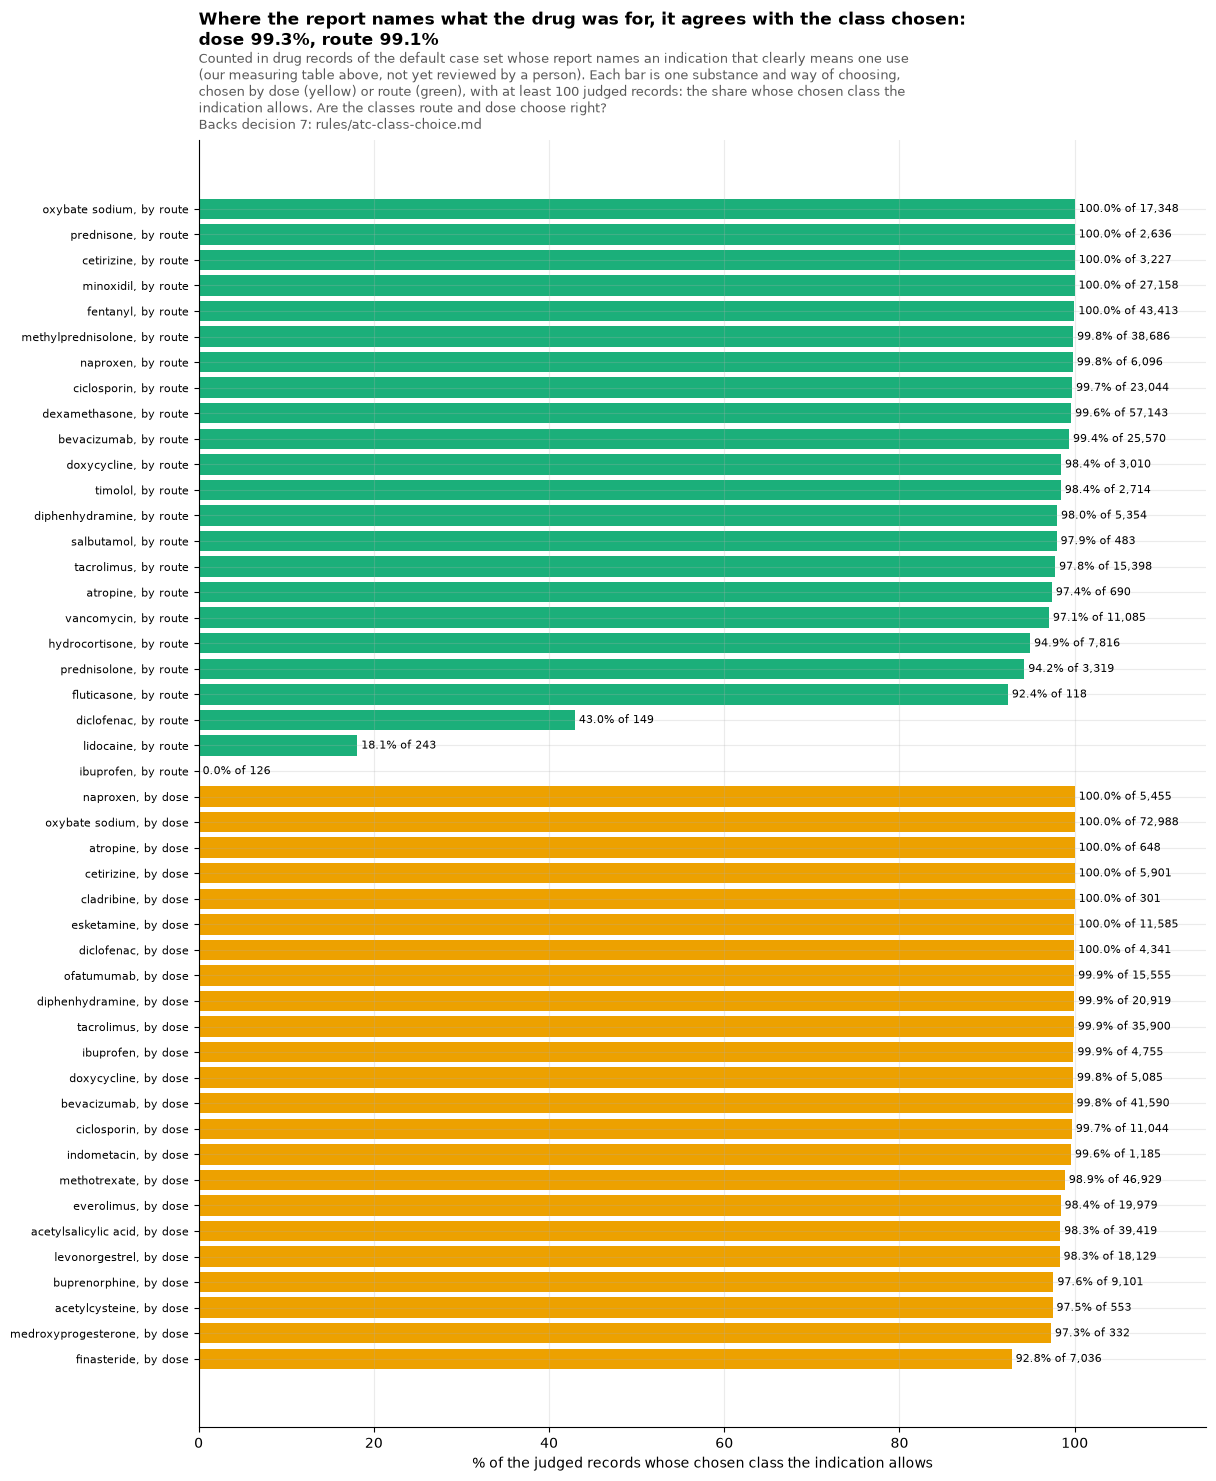

"can't tell" or a shared class, single substance: 7,600,243 records; the indication names one use for 237,360 of them (3.1%)


,judged,agree,%
chosen_by,,,
dose,378730,375942,99.3
route,294979,292414,99.1


,,judged,agree,%
substance_T,chosen_by,,,
oxybate sodium,dose,72988,72988,100.0
dexamethasone,route,57143,56914,99.6
methotrexate,dose,46929,46400,98.9
fentanyl,route,43413,43396,100.0
bevacizumab,dose,41590,41491,99.8
acetylsalicylic acid,dose,39419,38767,98.3
methylprednisolone,route,38686,38617,99.8
tacrolimus,dose,35900,35862,99.9
minoxidil,route,27158,27153,100.0


In [9]:
# A measuring aid, never read by the build and not yet reviewed by a person: for each substance with
# two or more uses, the reported indications (MedDRA terms, lower case) that clearly mean one use.
# Each entry is (the codes the indication allows, a pattern it must match, a pattern it must not).
# Unclear terms stay unmapped: unknown indication, off label, prophylaxis, pain for an NSAID that is
# both topical and oral, asthma for salbutamol.
CANCER = (
    r"hodgkin|plasmacytoma|cancer|carcinoma|neoplasm malignant|malignant neoplasm|tumou?r\b|sarcoma|glioblastoma|glioma"
    r"|metasta|mesothelioma|lymphoma|leuka?emia|myeloma|blastoma|adenocarcinoma|chemotherapy|melanoma"
    r"|macroglobulinaemia|myelodysplastic"
)
SYSTEMIC_STEROID = (
    r"rheumatoid|lupus|multiple sclerosis|transplant|graft versus host|immunosuppress|asthma|covid|interstitial lung"
    r"|dermatomyositis|polymyositis|nephrotic|chronic obstructive|emphysema|vasculitis|arteritis|encephalitis|still's"
    r"|myasthenia|sarcoid|polymyalgia|pemphig|nephritis|glomerulo|thrombocytop|haemophagocytic|histiocytosis|amyloidosis"
    r"|psoriatic arthropathy|ankylosing|spondylitis|spondyloarthr|juvenile idiopathic|cytokine release|polyangiitis"
    r"|pneumonia|gout|optic neuritis|anaphyla|autoimmune hepatitis|adrenal insufficiency|behcet|hepatitis autoimmune"
    r"|premedication|brain oedema|cerebral oedema|central nervous system|spinal cord compression|nausea|vomiting"
    r"|antiemetic|pneumonitis|alveolitis|bronchiolitis obliterans|" + CANCER
)
NOT_SYSTEMIC = r"in skin|skin|eye|ocular|uveitis|macular|retinal|proctitis|pouchitis|ear\b|otitis|rash|dermatitis|eczema"
EYE_STEROID = (
    r"uveitis|iritis|iridocyclitis|eye inflammation|ocular inflammation|postoperative eye|cataract|keratitis|scleritis"
    r"|episcleritis|conjunctivitis|endophthalmitis"
)
EAR = r"\botitis|ear infection|ear inflammation|ear pain|otorrhoea"
PAIN = (
    r"pain|analgesi|arthralgia|fibromyalgia|neuralgia|arthritis|complex regional|neuropathy|intervertebral|sciatica"
    r"|spinal column stenosis|back disorder|myalgia|migraine|headache"
)
INDICATIONS = {
    "acetylsalicylic acid": [
        (
            ["B01AC06"],
            r"thrombo|embolism|coronary|cardiovascular event prophylaxis|antiplatelet|platelet aggregation inhibition"
            r"|myocardial infarction|myocardial ischaemia|ischaemic heart|cerebrovascular accident|stroke|transient ischaemic"
            r"|angina|cerebral infarction|stent|peripheral arterial|arteriosclerosis|atherosclerosis|peripheral vascular"
            r"|antiphospholipid|anticoagulant therapy|atrial fibrillation|pre-eclampsia|preeclampsia|polycythaemia vera"
            r"|thrombocythaemia|carotid artery|vascular graft|bypass",
            r"thrombocytopeni|kawasaki",
        ),
        (
            ["N02BA01"],
            r"^pain$|headache|pyrexia|migraine|analgesic therapy|toothache|back pain|arthralgia|influenza like illness"
            r"|dysmenorrhoea|pain in extremity|musculoskeletal pain|neck pain|myalgia|analgesia$",
            r"chest",
        ),
    ],
    "methotrexate": [
        (
            ["L04AX03"],
            r"rheumatoid|psoria|crohn|juvenile|ankylosing|spondylitis|spondyloarthr|sjogren|transplant|arthritis|lupus"
            r"|dermatomyositis|polymyositis|colitis ulcerative|polyarthritis|rheumatic disorder|still's|uveitis|sarcoid"
            r"|granulomatosis|polymyalgia|dermatitis atopic|eczema|arthropathy|scleroderma|systemic sclerosis|myasthenia"
            r"|multiple sclerosis|vasculitis|arteritis|pemphig|morphoea|inflammatory bowel|behcet|graft versus host"
            r"|immunosuppress|takayasu|scleritis|pyoderma",
            CANCER,
        ),
        (["L01BA01"], CANCER, r"prophylaxis against graft"),
    ],
    "prednisone": [
        (
            ["H02AB07"],
            SYSTEMIC_STEROID + r"|^arthritis$",
            NOT_SYSTEMIC + r"|crohn|colitis|inflammatory bowel",
        )
    ],
    "prednisolone": [
        (
            ["H02AB06"],
            SYSTEMIC_STEROID + r"|^arthritis$",
            NOT_SYSTEMIC + r"|crohn|colitis|inflammatory bowel",
        ),
        (["S01BA04", "S03BA02"], EYE_STEROID, None),
        (["S02BA03", "S03BA02"], EAR, None),
    ],
    "methylprednisolone": [
        (
            ["H02AB04"],
            SYSTEMIC_STEROID + r"|spinal cord injury|^arthritis$|crohn|colitis|inflammatory bowel",
            NOT_SYSTEMIC,
        )
    ],
    "dexamethasone": [
        (
            ["H02AB02"],
            SYSTEMIC_STEROID + r"|croup|congenital adrenal|crohn|colitis|inflammatory bowel",
            NOT_SYSTEMIC,
        ),
        (
            ["S01BA01"],
            r"macular oedema|macular edema|diabetic retinal oedema|retinal vein occlusion|retinal oedema",
            None,
        ),
        (["S01BA01", "S03BA01"], EYE_STEROID, None),
        (["S02BA06", "S03BA01"], EAR, None),
        (["A01AC02"], r"stomatitis|mouth ulceration|aphthous", None),
    ],
    "hydrocortisone": [
        (
            ["H02AB09"],
            r"adrenal|adrenocortical|adrenogenital|corticotrophin|thyrotoxic|rheumatoid|leuka?emia|lymphoma|addison"
            r"|hypopituitarism|hypothalamo|pituitary|cortisol|hypocortisolism|septic shock|shock|premedication|anaphyla"
            r"|steroid replacement|glucocorticoid deficiency|corticosteroid replacement|hormone replacement|asthma"
            r"|infusion related|transfusion|hypotension|hypoglycaemia",
            r"rectal|anal|haemorrhoid|skin|eye|ear",
        ),
        (["A07EA02"], r"proctitis|colitis|crohn|inflammatory bowel|pouchitis|proctocolitis", None),
        (["D07AA02"], r"^rash|eczema|dermatitis|psoriasis$|^pruritus$", None),
        (["C05AA01"], r"haemorrhoid|anal fissure|pruritus ani", None),
    ],
    "salbutamol": [
        (["R03AC02"], r"inhalation therapy|nebuli", None),
        (
            ["R03CC02"],
            r"premature labour|tocolysis|threatened labour|preterm labour|uterine contractions",
            None,
        ),
    ],
    "ibuprofen": [
        (["C01EB16"], r"^patent ductus arteriosus", None),
        (
            ["M01AE01"],
            r"pyrexia|headache|migraine|dysmenorrhoea|toothache|influenza|teething|pericarditis|rheumatoid"
            r"|juvenile idiopathic|ankylosing|gout|cystic fibrosis",
            None,
        ),
    ],
    "indometacin": [
        (
            ["C01EB03"],
            r"patent ductus arteriosus|ductus arteriosus|intraventricular haemorrhage",
            None,
        ),
        (
            ["M01AB01"],
            r"gout|ankylosing|rheumatoid|osteoarthritis|arthritis|pericarditis|bursitis|tendonitis|migraine|headache"
            r"|hemicrania|dysmenorrhoea|pain|pyrexia|preterm labour|premature labour|tocolysis|polyhydramnios|pancreatitis"
            r"|spondyl|arthralgia|psoriatic arthropathy|still's|analgesic|antiinflammatory|sunct|trigeminal",
            None,
        ),
    ],
    "vitamin b9": [
        (
            ["B03BB01"],
            r"supplementation|neural tube|anaemia|anemia|folate|pregnancy$|sickle cell|hypovitaminosis|vitamin b"
            r"|drug toxicity prophylaxis|megaloblastic|homocyst|medical diet|chemotherapy side effect|haemoly|rheumatoid"
            r"|psoria|crohn|methotrexate|nutritional|vitamin deficiency|haemodialysis|dialysis|malnutrition",
            r"exposure",
        )
    ],
    "fentanyl": [
        (["N01AH01"], r"anaesth|anesth|intubation", None),
        (["N02AB03"], PAIN, r"procedural pain|anaesth|post procedural"),
    ],
    "cetirizine": [
        (
            ["R06AE07"],
            r"urticaria|angioedema|rhinitis|rhinorrhoea|sneezing|nasal congestion|food allergy|insomnia|^pruritus$|^rash"
            r"|mast cell|premedication|anaphyla|dermatitis atopic|eczema|sinus congestion",
            None,
        )
    ],
    "diclofenac": [
        (["D11AX18"], r"actinic keratosis", None),
        (
            ["S01BC03"],
            r"cataract|eye inflammation|postoperative eye|ocular|eye pain|cystoid macular|photophobia|corneal|keratectomy",
            None,
        ),
        (
            ["M01AB05"],
            r"migraine|pyrexia|gout|ankylosing|rheumatoid|psoriatic arthropathy|dysmenorrhoea|renal colic|nephrolithiasis"
            r"|headache|spondylitis|spondyloarthr|juvenile",
            None,
        ),
    ],
    "tacrolimus": [
        (
            ["L04AD02"],
            r"transplant|graft versus host|immunosuppress|rheumatoid|lupus|dermatomyositis|polymyositis|nephrotic"
            r"|interstitial lung|myasthenia|colitis ulcerative|glomerulo|nephropathy|autoimmune hepatitis|crohn|still's"
            r"|nephritis|aplastic|organ|leuka?emia|lymphoma|myelodysplastic|conditioning",
            r"in skin",
        ),
        (
            ["D11AH01"],
            r"dermatitis atopic|atopic dermatitis|eczema|vitiligo|seborrhoeic dermatitis|rosacea|lichen",
            None,
        ),
    ],
    "naproxen": [
        (
            ["M01AE02"],
            r"headache|migraine|dysmenorrhoea|pyrexia|gout|rheumatoid|juvenile idiopathic|ankylosing|psoriatic arthropathy"
            r"|toothache|tumour associated fever|fever",
            None,
        )
    ],
    "oxybate sodium": [
        (
            ["N07XX04"],
            r"narcolepsy|cataplexy|somnolence|hypersomnia|excessive daytime|sleep attack|alcohol|insomnia|sleep disorder"
            r"|fibromyalgia|dyssomnia|sleep paralysis",
            None,
        )
    ],
    "fluticasone": [
        (
            ["R03BA05", "R03BA09"],
            r"asthma|chronic obstructive|emphysema|bronchitis|wheezing|bronchospasm|bronchial",
            None,
        ),
        (
            ["R01AD08", "R01AD12"],
            r"rhinitis|nasal|sinusitis|sinus disorder|rhinorrhoea|sneezing|sinus congestion|nasopharyngitis",
            None,
        ),
        (["D07AC17"], r"psoriasis|eczema|dermatitis", None),
    ],
    "diphenhydramine": [
        (
            ["R06AA02"],
            r"premedication|insomnia|sleep|anaphyla|nausea|vomiting|infusion related|agitation|motion sickness|transfusion"
            r"|extrapyramidal|dystonia|^urticaria|chronic spontaneous urticaria|rhinorrhoea|nasal congestion",
            None,
        ),
        (["D04AA32"], r"sunburn|insect bite|arthropod bite|poison ivy|dermatitis contact", None),
    ],
    "bevacizumab": [
        (
            ["S01LA08"],
            r"macular|maculopathy|retinopathy|retinal|choroid|glaucoma|myopic|vitreous haemorrhage|eye|ocular",
            None,
        ),
        (
            ["L01FG01"],
            CANCER
            + r"|neoplasm$|astrocytoma|meningioma|papilloma|neurofibromatosis|malignan|ependymoma|radiation necrosis",
            r"eye|ocular|retin|choroid",
        ),
    ],
    "ciclosporin": [
        (
            ["S01XA18"],
            r"dry eye|keratoconjunctivitis|blepharitis|meibomian|keratitis|ocular|eye",
            r"intraocular pressure",
        ),
        (
            ["L04AD01"],
            r"transplant|graft versus host|immunosuppress|aplastic|psoriasis|psoriatic|nephrotic|rheumatoid|lupus"
            r"|haemophagocytic|histiocytosis|interstitial lung|dermatitis atopic|urticaria|dermatomyositis|pyoderma|still's"
            r"|colitis ulcerative|myasthenia|red cell|myelodysplastic|glomerulo|juvenile idiopathic|nephritis|leuka?emia"
            r"|lymphoma",
            None,
        ),
    ],
    "celecoxib": [
        (["L01XX33"], r"adenomatous polyposis|familial polyposis|polyposis", None),
        (
            ["M01AH01"],
            r"arthritis|pain|arthralgia|osteoarthritis|inflammation|ankylosing|fibromyalgia|analgesi|spondyl|arthropathy"
            r"|tendonitis|myalgia|sciatica|headache|migraine|gout|dysmenorrhoea|intervertebral|bursitis",
            None,
        ),
    ],
    "finasteride": [
        (
            ["G04CB01"],
            r"prostat|urinary retention|lower urinary tract|urine flow|micturition|nocturia|pollakiuria|dysuria"
            r"|urinary hesitation",
            None,
        ),
        (
            ["D11AX10"],
            r"alopecia|baldness|hair loss|hair growth|hair disorder|hair transplant",
            None,
        ),
    ],
    "timolol": [
        (
            ["S01ED01"],
            r"glaucoma|intraocular pressure increased|ocular hypertension|intraocular pressure test abnormal",
            None,
        ),
        (["C07AA06"], r"^hypertension$|essential hypertension|migraine|angina", None),
    ],
    "minoxidil": [
        (
            ["D11AX01"],
            r"alopecia|baldness|hair growth|hypotrichosis|madarosis|hair disorder|hair loss|hair transplant",
            None,
        ),
        (["C02DC01"], r"hypertension|blood pressure", None),
    ],
    "clonidine": [
        (
            ["C02AC01"],
            r"^hypertension$|essential hypertension|blood pressure increased|hypertensive|^blood pressure",
            r"intraocular|ocular|portal|pulmonary",
        ),
        (["N02CX02"], r"migraine", None),
        (["S01EA04"], r"glaucoma|intraocular pressure increased|ocular hypertension", None),
    ],
    "lidocaine": [
        (
            ["C01BB01"],
            r"ventricular tachycardia|ventricular fibrillation|ventricular arrhythmia|arrhythmia|ventricular extrasystoles"
            r"|cardiac arrest|tachycardia",
            r"supraventricular",
        ),
        (
            ["N01BB02", "D04AB01"],
            r"^pain$|back pain|arthralgia|pain in extremity|musculoskeletal pain|neck pain|osteoarthritis|complex regional"
            r"|pain management|sciatica|herpes zoster|fibromyalgia|cancer pain|intervertebral disc|analgesic therapy"
            r"|anaesthesia|anesthesia|nerve block|local anaesth|regional anaesth|spinal anaesth|epidural anaesth"
            r"|procedural pain|dental|neuralgia|postherpetic|neuropathy peripheral|neuropathic pain|nerve injury|intubation"
            r"|catheter placement|injection site pain|infusion site pain|vascular access|venipuncture|biopsy"
            r"|tooth extraction|post procedural pain",
            r"ophthalm|eye",
        ),
        (["S01HA07"], r"cataract|eye anaesth|ophthalmic|intravitreal", None),
        (["C05AD01"], r"haemorrhoid|anal fissure", None),
        (
            ["R02AD02"],
            r"pharyngitis|oropharyngeal pain|sore throat|stomatitis|mouth ulceration|aphthous",
            None,
        ),
    ],
    "everolimus": [
        (["L04AH02"], r"transplant|immunosuppress|graft|rejection", None),
        (
            ["L01EG02"],
            CANCER
            + r"|neoplasm|tuberous sclerosis|angiomyolipoma|subependymal|astrocytoma|lymphangioleiomyomatosis"
            r"|neuroendocrine|insulinoma|seizure|epilepsy|rhabdomyoma|meningioma|hamartoma|neurofibromatosis"
            r"|phaeochromocytoma|thymoma|chordoma|carcinoid|lennox",
            r"transplant|graft",
        ),
    ],
    "ofatumumab": [
        (
            ["L04AG12"],
            r"multiple sclerosis|demyelination|neuromyelitis|clinically isolated syndrome",
            None,
        ),
        (["L01FA02"], CANCER + r"|chronic lymphocytic|richter", None),
    ],
    "medroxyprogesterone": [
        (["G03AC06"], r"contracept|birth control|pregnancy prevention", r"emergency"),
        (
            ["G03DA02"],
            r"menopaus|hormone replacement|amenorrhoea|endometrial hyperplasia|abnormal uterine bleeding|oligomenorrhoea"
            r"|hot flush|polycystic ovar|oestrogen replacement|postmenopause|transgender|gender dysphoria",
            None,
        ),
        (
            ["L02AB02"],
            r"endometrial cancer|uterine cancer|renal cancer|breast cancer|carcinoma|neoplasm malignant",
            None,
        ),
    ],
    "buprenorphine": [
        (
            ["N07BC01"],
            r"drug dependence|opiate|opioid|substance use|substance abuse|drug abuse|drug withdrawal|withdrawal syndrome"
            r"|drug detox|dependence$|maintenance therapy|addiction|drug use disorder|drug rehabilitation|^detoxification$",
            r"opioid induced|analges",
        ),
        (["N02AE01"], PAIN + r"|osteoarthritis|toothache", r"withdrawal"),
    ],
    "levonorgestrel": [
        (
            ["G03AD01"],
            r"emergency contracep|postcoital|post coital|unprotected sex|coitus|contraception failure|condom",
            None,
        ),
        (
            ["G03AC03"],
            r"contracep|menstrual cycle management|menstruation irregular|adenomyosis|menorrhagia|heavy menstrual"
            r"|dysmenorrhoea|endometriosis|hormone replacement|endometrial hyperplasia",
            r"emergency|postcoital|post coital",
        ),
    ],
    "esketamine": [
        (["N06AX27"], r"depress|suicid|major depression|bipolar", None),
        (["N01AX14"], r"anaesth|anesth|sedation|intubation|procedural", None),
    ],
    "acetylcysteine": [
        (
            ["V03AB23"],
            r"overdose|poisoning|toxicity|paracetamol|acetaminophen|intentional|hepatotoxicity|liver injury|antidote"
            r"|hepatic failure|liver failure",
            r"product|ototox|pulmonary toxicity",
        ),
        (
            ["R05CB01"],
            r"sputum|mucolytic|cough|bronchitis|secretion|bronchiectasis|chronic obstructive|pulmonary fibrosis"
            r"|idiopathic pulmonary|cystic fibrosis|productive|viscous|mucus|atelectasis|respiratory tract",
            None,
        ),
    ],
    "vancomycin": [
        (["A07AA09"], r"clostridi|pseudomembranous|colitis|enterocolitis|diarrhoea", r"ulcerative"),
        (
            ["J01XA01"],
            r"sepsis|bacteraemia|endocarditis|osteomyelitis|pneumonia|meningitis|cellulitis|staphylococcal infection|mrsa"
            r"|methicillin|wound infection|device related infection|infection prophylaxis|prophylaxis|abscess|septic"
            r"|febrile neutropenia|skin infection|joint infection|bone infection|enterococcal|urinary tract infection"
            r"|pseudomonas|arthritis bacterial|arthritis infective|peritonitis|vascular device infection|streptococcal"
            r"|klebsiella|escherichia|osteitis|discitis|necrotising fasciitis|febrile bone marrow aplasia",
            r"clostridi|colitis",
        ),
    ],
    "cladribine": [
        (["L04AA40"], r"multiple sclerosis", None),
        (["L01BB04"], CANCER + r"|hairy cell|mastocytosis|histiocytosis|langerhans", None),
    ],
    "doxycycline": [
        (["A01AB22"], r"periodont|gingivitis", None),
        (
            ["J01AA02"],
            r"infection|acne|rosacea|lyme|borrelia|malaria|chlamydi|syphilis|pneumonia|bronchitis|sinusitis|cellulitis"
            r"|rickettsi|q fever|leptospir|anthrax|urethritis|prostatitis|pelvic inflammatory|bacterial|hidradenitis"
            r"|blepharitis|meibomian|folliculitis|cholera|brucell|tularaemia|anaplasm|ehrlichi|mycoplasma"
            r"|lymphogranuloma|filariasis|perioral dermatitis|pleurodesis|tick|abscess",
            r"periodont|gingivitis",
        ),
    ],
    "atropine": [
        (
            ["S01FA01"],
            r"myopia|mydriasis|cycloplegi|amblyopia|uveitis|iritis|iridocyclitis|eye|ocular|pupil|refraction|accommodat"
            r"|strabismus",
            None,
        ),
        (
            ["A03BA01"],
            r"bradycardia|premedication|organophosphate|poisoning|cholinergic|secretion|salivary hypersecretion|sialorrhoea"
            r"|drooling|hypersalivation|intubation|anaesth|heart rate decreased|atrioventricular block|cardiac arrest|asystole"
            r"|reversal of neuromuscular|neuromuscular blockade reversal|irritable bowel|diarrhoea|gastrointestinal"
            r"|abdominal pain|spasm",
            r"eye|ocular",
        ),
    ],
}
# the indications of every two-use record of these substances (one substance, its codes listed)
con.execute(f"""CREATE TABLE indi_rec_T AS
SELECT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, r.substance_T, r.atc_chosen_by_T, r.atc_code_T,
       lower(trim(i.indi_pt)) AS pt_T
FROM rec_T r JOIN indi_latest_T i ON i.era_T = r.era_T AND i.primaryid = r.primaryid AND i.quarter_T = r.quarter_T
                                 AND i.indi_drug_seq = r.drug_seq
WHERE r.substance_T IN ({", ".join(quoted(s) for s in INDICATIONS)})
  AND r.atc_possible_codes_T > 1 AND r.atc_matched_on_T = 'substance'""")
codes_of = (
    TABLE[TABLE.ingredient.isin(INDICATIONS)].groupby("ingredient").atc_code.agg(set).to_dict()
)
pairs = q("SELECT substance_T, pt_T, count(*) AS records FROM indi_rec_T GROUP BY ALL")
implied = []
for s, pt in zip(pairs.substance_T, pairs.pt_T, strict=True):
    hits = [
        tuple(c for c in ok if c in codes_of.get(s, ()))
        for ok, must, must_not in INDICATIONS[s]
        if re.search(must, pt) and not (must_not and re.search(must_not, pt))
    ]
    hits = {h for h in hits if h}
    if len(hits) == 1:  # a term two entries claim is left unmapped
        implied += [(s, pt, c) for c in hits.pop()]
con.register("implied_df", pd.DataFrame(implied, columns=["substance_T", "pt_T", "code_T"]))
# the codes every mapped indication of the record allows; none left means they conflict
con.execute("""CREATE TABLE judged_T AS
WITH m AS (SELECT i.*, x.code_T FROM indi_rec_T i JOIN implied_df x USING (substance_T, pt_T)),
n AS (SELECT era_T, primaryid, quarter_T, drug_seq, count(DISTINCT pt_T) AS pts FROM m GROUP BY ALL),
c AS (SELECT era_T, primaryid, quarter_T, drug_seq, code_T, count(DISTINCT pt_T) AS pts FROM m GROUP BY ALL)
SELECT n.era_T, n.primaryid, n.quarter_T, n.drug_seq, any_value(m.substance_T) AS substance_T,
       any_value(m.atc_chosen_by_T) AS chosen_by_T, any_value(m.atc_code_T) AS atc_code_T,
       list(DISTINCT c.code_T) FILTER (WHERE c.pts = n.pts) AS allowed_T
FROM n JOIN m USING (era_T, primaryid, quarter_T, drug_seq)
LEFT JOIN c ON c.era_T = n.era_T AND c.primaryid = n.primaryid AND c.quarter_T = n.quarter_T AND c.drug_seq = n.drug_seq
GROUP BY ALL""")
agree = q("""SELECT substance_T, chosen_by_T AS chosen_by, count(*) AS judged,
                    count(*) FILTER (WHERE list_contains(allowed_T, atc_code_T)) AS agree
             FROM judged_T WHERE chosen_by_T IN ('dose', 'route') AND len(allowed_T) > 0 GROUP BY ALL""")
agree["%"] = 100 * agree.agree / agree.judged
settle = q("""SELECT count(*) FILTER (WHERE len(allowed_T) = 1) AS settled, count(*) AS with_indication,
                     (SELECT count(*) FROM rec_T WHERE atc_chosen_by_T IN ('cannot_tell', 'shared_class')
                        AND atc_matched_on_T = 'substance') AS not_said
              FROM judged_T WHERE chosen_by_T IN ('cannot_tell', 'shared_class')""").iloc[0]
total = agree.groupby("chosen_by")[["judged", "agree"]].sum()
total["%"] = 100 * total.agree / total.judged
shown = agree[agree.judged >= 100].sort_values(["chosen_by", "%"])
fig, ax = plt.subplots(figsize=(13, 0.32 * len(shown) + 2))
y = np.arange(len(shown))
bars = ax.barh(
    y, shown["%"], color=[SERIES[3] if w == "dose" else SERIES[2] for w in shown.chosen_by]
)
for b, n in zip(bars, shown.judged, strict=True):
    ax.text(
        b.get_width(),
        b.get_y() + b.get_height() / 2,
        f" {b.get_width():.1f}% of {n:,}",
        va="center",
        fontsize=8,
    )
ax.set_yticks(y)
ax.set_yticklabels(
    [f"{s}, by {w}" for s, w in zip(shown.substance_T, shown.chosen_by, strict=True)], fontsize=8
)
ax.set_xlim(0, 115)
ax.set_xlabel("% of the judged records whose chosen class the indication allows")
title(
    ax,
    f"Where the report names what the drug was for, it agrees with the class chosen: dose {total.loc['dose', '%']:.1f}%, "
    f"route {total.loc['route', '%']:.1f}%",
    "Counted in drug records of the default case set whose report names an indication that clearly means one use (our "
    "measuring table above, not yet reviewed by a person). Each bar is one substance and way of choosing, chosen by dose "
    "(yellow) or route (green), with at least 100 judged records: the share whose chosen class the indication allows.",
    "Are the classes route and dose choose right?",
    backs(7, "atc-class-choice"),
    width=110,
)
plt.show()
print(
    f'"can\'t tell" or a shared class, single substance: {settle.not_said:,} records; the indication names one use '
    f"for {settle.settled:,} of them ({100 * settle.settled / settle.not_said:.1f}%)"
)
display(total.round(1))
agree.sort_values("judged", ascending=False).round(1).set_index(["substance_T", "chosen_by"])

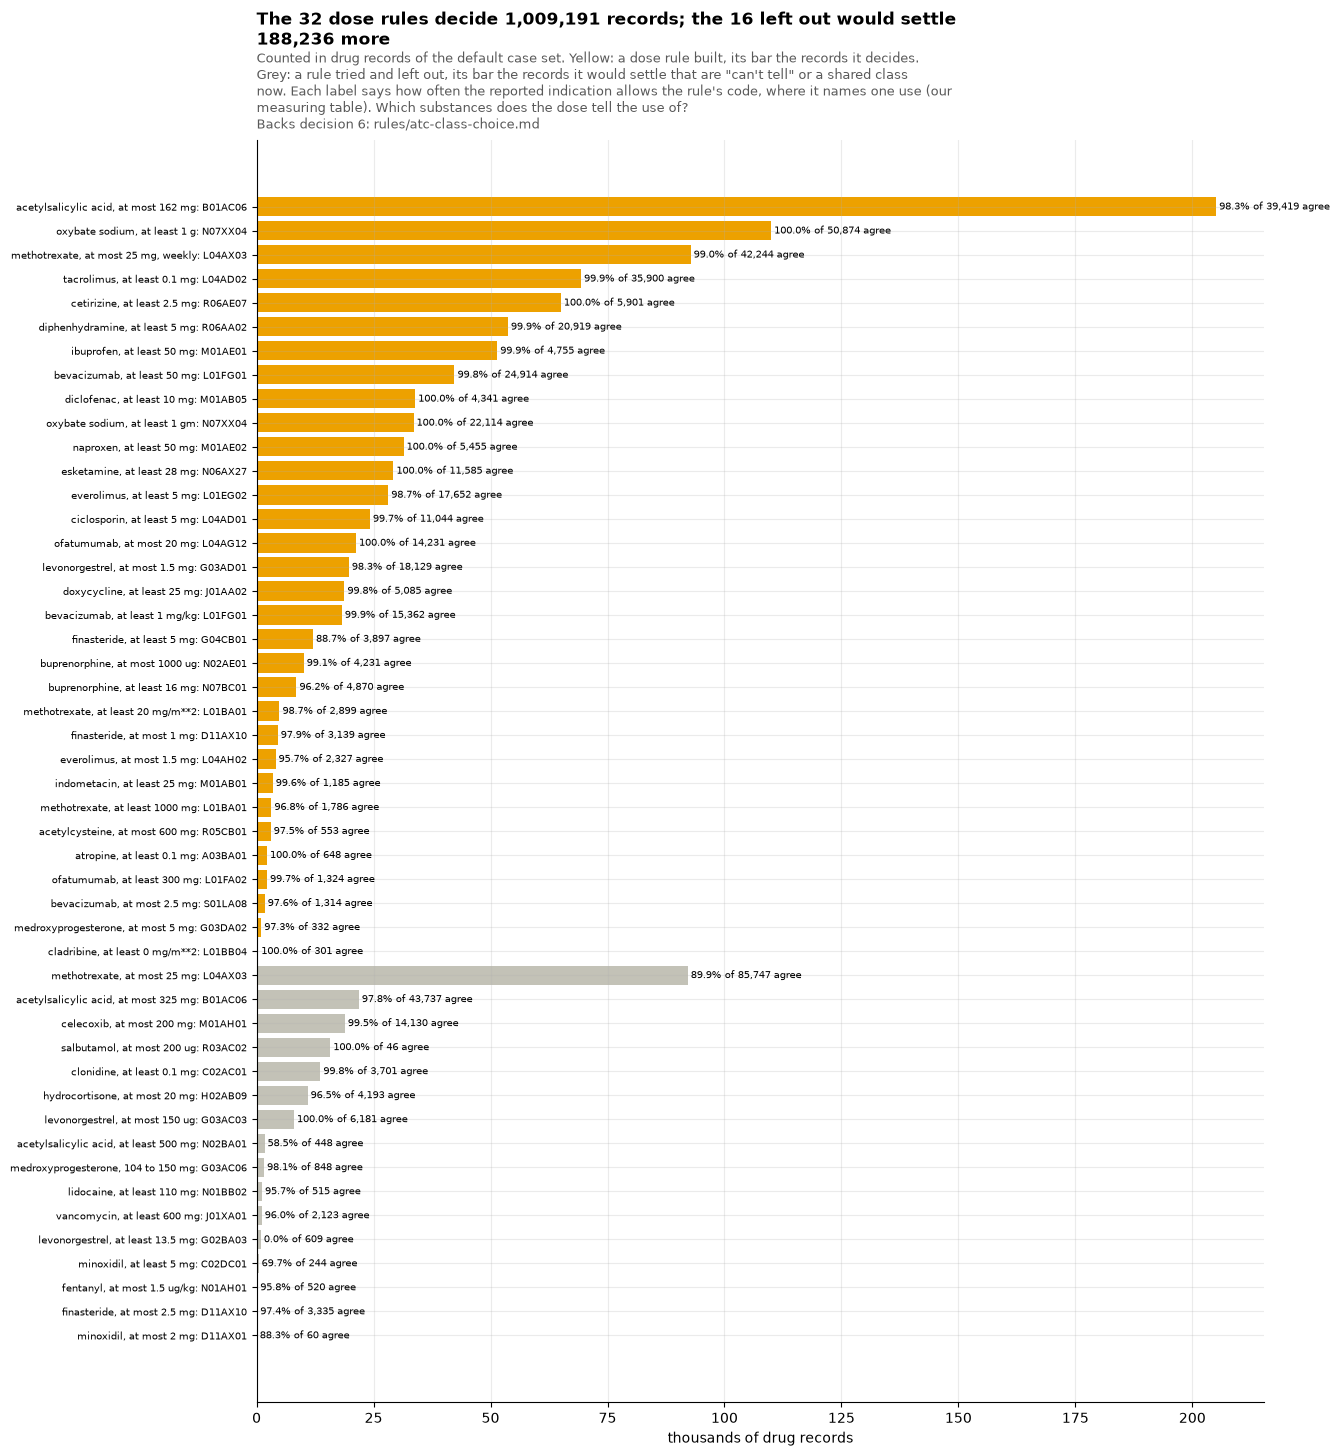

code  records  decides  would_settle  overrides_route  judged  agree  agree %
status   substance            dose                                                                                                   
built    acetylsalicylic acid at most 162 mg         B01AC06   205082   205082             0                0   39419  38767     98.3
         finasteride          at most 1 mg           D11AX10     4505     4505             0                0    3139   3072     97.9
                              at least 5 mg          G04CB01    12044    12044             0                0    3897   3458     88.7
         methotrexate         at most 25 mg, weekly  L04AX03    92766    92766             0                0   42244  41812     99.0
                              at least 20 mg/m**2    L01BA01     4889     4889             0                0    2899   2860     98.7
                              at least 1000 mg       L01BA01     3155     3155             0                0    1786   1728     96.8
         ibuprofen            at least 50 mg         M01AE01    51427    51427             0                0    4755   4748     99.9
         diclofenac           at least 10 mg         M01AB05    33906    33906             0                0    4341   4339    100.0
         everolimus           at least 5 mg          L01EG02    28133    28133             0                0   17652  17429     98.7
                              at most 1.5 mg         L04AH02     4042     4042             0                0    2327   2228     95.7
         esketamine           at least 28 mg         N06AX27    29247    29247             0                0   11585  11582    100.0
         ofatumumab           at most 20 mg          L04AG12    21247    21247             0                0   14231  14226    100.0
                              at least 300 mg        L01FA02     2222     2222             0                0    1324   1320     99.7
         levonorgestrel       at most 1.5 mg         G03AD01    19709    19709             0                0   18129  17816     98.3
         buprenorphine        at most 1000 ug        N02AE01    10060    10060             0                0    4231   4195     99.1
                              at least 16 mg         N07BC01     8503     8503             0                0    4870   4685     96.2
         indometacin          at least 25 mg         M01AB01     3443     3443             0                0    1185   1180     99.6
         acetylcysteine       at most 600 mg         R05CB01     3004     3004             0                0     553    539     97.5
         medroxyprogesterone  at most 5 mg           G03DA02      987      987             0                0     332    323     97.3
         cladribine           at least 0 mg/m**2     L01BB04      361      361             0                0     301    301    100.0
         cetirizine           at least 2.5 mg        R06AE07    65034    65034             0                0    5901   5901    100.0
         tacrolimus           at least 0.1 mg        L04AD02    69340    69340             0                0   35900  35862     99.9
         naproxen             at least 50 mg         M01AE02    31421    31421             0                0    5455   5455    100.0
         diphenhydramine      at least 5 mg          R06AA02    53706    53706             0                0   20919  20906     99.9
         ciclosporin          at least 5 mg          L04AD01    24216    24216             0                0   11044  11008     99.7
         doxycycline          at least 25 mg         J01AA02    18760    18760             0                0    5085   5075     99.8
         bevacizumab          at least 50 mg         L01FG01    42294    42294             0                0   24914  24858     99.8
                              at least 1 mg/kg       L01FG01    18207    18207             0                0   15362  15351     99.9
                              at mos

,bound,named,records
0,13.5 mg or more,an implant,497
1,13.5 mg or more,a pill or a name that does not say,378
2,13.5 mg or more,a hormonal IUD,29
3,150 ug or less,a hormonal IUD,7705
4,150 ug or less,a pill or a name that does not say,285
5,150 ug or less,an implant,5


In [10]:
# The dose rules built, and those a search of the release's stated doses tried and left out: aspirin at
# 500 mg or more (a loading dose for the heart as often as a painkiller), levonorgestrel's contraceptive
# forms (no bound tells the implant, the IUD and the pill apart), and rules that would only be a default.
# Each is (substance, unit, at most, at least, frequencies, code); a rule naming frequencies needs the
# record to state one, and every frequency it states to be one of them.
TODAY = [
    (d["substance"], d["unit"], d.get("at_most"), d.get("at_least"), d.get("freq"), d["code"])
    for d in CHOICE["dose_rules"]
]
CANDIDATES = [
    ("acetylsalicylic acid", "MG", None, 500, None, "N02BA01"),
    ("levonorgestrel", "MG", None, 13.5, None, "G02BA03"),
    ("levonorgestrel", "UG", 150, None, None, "G03AC03"),
    ("acetylsalicylic acid", "MG", 325, None, None, "B01AC06"),
    ("finasteride", "MG", 2.5, None, None, "D11AX10"),
    ("methotrexate", "MG", 25, None, None, "L04AX03"),
    ("medroxyprogesterone", "MG", 150, 104, None, "G03AC06"),
    ("vancomycin", "MG", None, 600, None, "J01XA01"),
    ("hydrocortisone", "MG", 20, None, None, "H02AB09"),
    ("minoxidil", "MG", 2, None, None, "D11AX01"),
    ("minoxidil", "MG", None, 5, None, "C02DC01"),
    ("fentanyl", "UG/KG", 1.5, None, None, "N01AH01"),
    ("lidocaine", "MG", None, 110, None, "N01BB02"),
    ("celecoxib", "MG", 200, None, None, "M01AH01"),
    ("clonidine", "MG", None, 0.1, None, "C02AC01"),
    ("salbutamol", "UG", 200, None, None, "R03AC02"),
]
dosed_substances = sorted({r[0] for r in TODAY + CANDIDATES})
# each two-use record's stated doses, read as the layer reads them
con.execute(f"""CREATE TABLE dose_facts_T AS
WITH d AS (
  SELECT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, r.substance_T, r.atc_chosen_by_T, r.atc_code_T,
         upper(trim(d.dose_unit)) AS unit_T, upper(trim(d.dose_freq)) AS freq_T,
         CASE WHEN regexp_full_match(d.dose_amt, '[0-9]*\\.?[0-9]+') THEN CAST(d.dose_amt AS DOUBLE) END AS amount_T
  FROM rec_T r JOIN drug_latest_T d USING (era_T, primaryid, quarter_T, drug_seq)
  WHERE r.substance_T IN ({", ".join(quoted(s) for s in dosed_substances)})
    AND r.atc_possible_codes_T > 1 AND r.atc_matched_on_T = 'substance')
SELECT era_T, primaryid, quarter_T, drug_seq, any_value(substance_T) AS substance_T,
       any_value(atc_chosen_by_T) AS chosen_by_T, any_value(atc_code_T) AS atc_code_T,
       count(amount_T) AS doses_T, count(DISTINCT coalesce(unit_T, '')) FILTER (WHERE amount_T IS NOT NULL) AS units_T,
       min(unit_T) FILTER (WHERE amount_T IS NOT NULL) AS unit_T, min(amount_T) AS least_T, max(amount_T) AS most_T,
       list(DISTINCT freq_T) FILTER (WHERE freq_T IS NOT NULL) AS freqs_T
FROM d GROUP BY era_T, primaryid, quarter_T, drug_seq""")
con.execute(
    "CREATE TABLE caught_T (rule_T INTEGER, era_T VARCHAR, primaryid VARCHAR, quarter_T VARCHAR, drug_seq VARCHAR)"
)
rows = []
for n, (s, unit, most, least, freqs, code) in enumerate(TODAY + CANDIDATES):
    where = [
        f"f.substance_T = {quoted(s)}",
        "f.doses_T > 0",
        "f.units_T = 1",
        f"f.unit_T = {quoted(unit)}",
    ]
    where += [f"f.most_T <= {most}"] if most is not None else []
    where += [f"f.least_T >= {least}"] if least is not None else []
    where += (
        [f"len(f.freqs_T) > 0 AND list_has_all([{', '.join(quoted(x) for x in freqs)}], f.freqs_T)"]
        if freqs
        else []
    )
    con.execute(f"""INSERT INTO caught_T SELECT {n}, era_T, primaryid, quarter_T, drug_seq FROM dose_facts_T f
                    WHERE {" AND ".join(where)}""")
    got = q(f"""SELECT count(*) AS records,
           count(*) FILTER (WHERE f.chosen_by_T = 'dose' AND f.atc_code_T = {quoted(code)}) AS decides,
           count(*) FILTER (WHERE f.chosen_by_T IN ('cannot_tell', 'shared_class')) AS would_settle,
           count(*) FILTER (WHERE f.chosen_by_T = 'route' AND f.atc_code_T <> {quoted(code)}) AS overrides_route,
           count(j.allowed_T) FILTER (WHERE len(j.allowed_T) > 0) AS judged,
           count(*) FILTER (WHERE list_contains(j.allowed_T, {quoted(code)})) AS agree
        FROM dose_facts_T f LEFT JOIN judged_T j USING (era_T, primaryid, quarter_T, drug_seq)
        WHERE {" AND ".join(where)}""").iloc[0]
    bound = (
        f"{least:g} to {most:g}"
        if most is not None and least is not None
        else f"at most {most:g}"
        if most is not None
        else f"at least {least:g}"
    )
    rows.append(
        {
            "rule": n,
            "status": "built" if n < len(TODAY) else "left out",
            "substance": s,
            "dose": f"{bound} {unit.lower()}" + (", weekly" if freqs else ""),
            "code": code,
            **got.to_dict(),
        }
    )
doses = pd.DataFrame(rows)
doses["agree %"] = (100 * doses.agree / doses.judged).round(1)
cand = doses[doses.status == "left out"]
union = con.execute(f"""SELECT count(DISTINCT (c.era_T, c.primaryid, c.quarter_T, c.drug_seq))
  FROM caught_T c JOIN dose_facts_T f USING (era_T, primaryid, quarter_T, drug_seq)
  WHERE c.rule_T >= {len(TODAY)} AND f.chosen_by_T IN ('cannot_tell', 'shared_class')""").fetchone()[
    0
]
shown = doses.assign(
    n=np.where(doses.status == "built", doses.decides, doses.would_settle)
).sort_values(["status", "n"], ascending=[True, False])
fig, ax = plt.subplots(figsize=(13, 0.3 * len(shown) + 2))
y = np.arange(len(shown))
bars = ax.barh(
    y, shown.n / 1e3, color=[SERIES[3] if s == "built" else SERIES[7] for s in shown.status]
)
for b, a, j in zip(bars, shown["agree %"], shown.judged, strict=True):
    ax.text(
        b.get_width(),
        b.get_y() + b.get_height() / 2,
        f" {a:.1f}% of {j:,} agree" if j else " no indication to judge by",
        va="center",
        fontsize=7,
    )
ax.set_yticks(y)
ax.set_yticklabels(
    [f"{s}, {d}: {c}" for s, d, c in zip(shown.substance, shown.dose, shown.code, strict=True)],
    fontsize=7,
)
ax.invert_yaxis()
ax.set_xlabel("thousands of drug records")
title(
    ax,
    f"The {len(TODAY)} dose rules decide {doses[doses.status == 'built'].decides.sum():,} records; "
    f"the {len(cand)} left out would settle {union:,} more",
    "Counted in drug records of the default case set. Yellow: a dose rule built, its bar the records it decides. "
    'Grey: a rule tried and left out, its bar the records it would settle that are "can\'t tell" or a shared class now. '
    "Each label says how often the reported indication allows the rule's code, where it names one use (our measuring table).",
    "Which substances does the dose tell the use of?",
    backs(6, "atc-class-choice"),
    width=110,
)
plt.show()
display(doses.drop(columns="rule").set_index(["status", "substance", "dose"]))
# why no dose tells levonorgestrel's contraceptive forms apart: what the records at each bound are,
# read from their drug names
q("""WITH f AS (SELECT f.*, any_value(upper(trim(d.drugname))) AS n FROM dose_facts_T f
                JOIN drug_latest_T d USING (era_T, primaryid, quarter_T, drug_seq)
                WHERE f.substance_T = 'levonorgestrel' AND f.doses_T > 0 AND f.units_T = 1 GROUP BY ALL)
SELECT CASE WHEN unit_T = 'MG' AND least_T >= 13.5 THEN '13.5 mg or more'
            WHEN unit_T = 'UG' AND most_T <= 150 THEN '150 ug or less' END AS bound,
       CASE WHEN regexp_matches(n, 'MIRENA|KYLEENA|SKYLA|LILETTA|JAYDESS|IUD|INTRAUTERINE') THEN 'a hormonal IUD'
            WHEN regexp_matches(n, 'JADELLE|NORPLANT|IMPLANT') THEN 'an implant'
            ELSE 'a pill or a name that does not say' END AS named,
       count(*) AS records
FROM f WHERE bound IS NOT NULL GROUP BY ALL ORDER BY 1, 3 DESC""")

**What section 3 shows**, one item per chart:

- **Substances with more than one code.** *Shows:* 431 of the 4,250 single substances in our table have two or more WHO codes, and they are 11.5 million drug records, 18% of the single-substance records with a code, about one in six. Betamethasone, dexamethasone and prednisolone have 11 each, counting the codes of classes for mixes; a one-ingredient record can take 9, 8 and 9 of them. *Point:* how many drugs have more than one class: a small share of substances, but a large share of FAERS, the steroids, aspirin and methotrexate among them. *So what:* choosing one class decides the count for about one drug record in six (decision 7).
- **How the class is chosen, and which routes choose.** *Shows:* in cases: only one code 18.16 million, a group's class 1.28 million, dose 0.69 million, route 1.22 million, indication 0.80 million, the class its uses share 0.99 million, "can't tell" 4.43 million; dose, route and indication decide 31% of the records with two or more codes. By mouth makes 46% of the route choices, then injection, skin, lungs and eye. In the table, timolol eye drops take S01ED01 by route (5,134 cases) or by indication (2,017) and its tablets C07AA06 (193); bevacizumab for an eye disease takes S01LA08 by indication (5,132 cases); salbutamol whose route is not said takes R03 (346,049 cases), the class its two uses share. *Point:* these are counts of choices made, not of choices proved right; the indication check and section 8 measure that. *So what:* decisions 5, 6 and 7 as built.
- **Aspirin's stated doses.** *Shows:* in drug records: 88% of aspirin records that state a dose in mg are at 162 mg or less (81 mg and 100 mg lead), and 325 mg, which is either use, decides nothing. 205,081 records take B01AC06 by dose; by indication, 54,225 take B01AC06 and 7,738 N02BA01; 575,973 stay "can't tell". *Point:* why blood thinner or painkiller matters: WHO classes aspirin by its use, and someone filtering antithrombotics expects the low-dose aspirin most aspirin reports are. *So what:* the low bound stands, and the indication settles part of the rest (decisions 6 and 7).
- **The indication check.** *Shows:* in drug records whose report names an indication our measuring table reads as one use: dose choices agree with it in 99.3% of 378,729 and route choices in 99.1% of 294,853. The weak spots are routes FAERS reports wrongly: lidocaine (18.1% of 243), diclofenac reported as an eye drop (43.0% of 149), ibuprofen as a gel with fever (none of 126). Among the records whose use is still not said, the table names one use for only 236,981 of 7,601,229 (3.1%): the reviewed indication rows (section 8) took most of what it could tell. *Point:* how we know a chosen class is right: where the report says what the drug was for, it agrees with the class dose or route chose nearly always, and the misses are a few hundred records with a wrong route. *So what:* the route and dose rules stand (decisions 5 and 6).
- **The dose rules built, and those left out.** *Shows:* in drug records: the 32 dose rules decide 1,009,174 records, and the indication agrees with each in at least 95% of the records it judges, except finasteride at 5 mg or more (88.7%: men splitting 5 mg tablets for hair loss). Left out: aspirin at 500 mg or more (58.5% of 448, as often a loading dose for a heart attack as a painkiller); levonorgestrel's contraceptive forms: of the 904 records at 13.5 mg or more, 497 are named as an implant and 29 as a hormonal IUD, and of the 7,995 at 150 µg or less, 7,705 are named as a hormonal IUD (Kyleena is reported at 17.5 µg a day), though the measuring table, reading "contraception" as the pill, agrees with them; methotrexate at 25 mg or less with no weekly frequency (89.9%); and rules that would only be a default (celecoxib, clonidine, hydrocortisone, salbutamol, minoxidil, fentanyl, lidocaine, vancomycin). Together the 16 left out would settle 188,212 records. *Point:* the dose tells the use of many more drugs than aspirin and finasteride, but not levonorgestrel's contraceptive forms apart. *So what:* decision 6 as built: of levonorgestrel's forms, only the emergency pill (1.5 mg or less) is chosen by dose.

One class is chosen from the report's dose, route or indication for nearly a third of the records of drugs with two uses, and where the report says what the drug was for, dose and route agree with it 99 times in a hundred. The dose tells the use of many drugs, but not of levonorgestrel's pill, implant and IUD, which wait for the product name.

## 4 · When the report does not say which use: the shared class, "can't tell", and our table's reading of WHO's product classes

A record with two or more possible codes whose dose, route and indication decide nothing is not yet lost. If all its codes sit in one class of WHO's tree, that class is certain whichever use the report meant: two inhaled fluticasone esters (R03BA05, R03BA09) are both inhaled corticosteroids, R03BA, at level 4. The record takes the deepest such class at level 4, 3 or 2 (`shared_class`, decision 7); when its route is in a group and two or more of its codes fit that group, the codes compared are those that fit, so nasal fluticasone is a nasal corticosteroid (R01AD). Level 1 names only a body system and is never given. Only a record whose codes share no class at those levels, or a split combination, stays **can't tell**.

The third chart is about our table, not FAERS. WHO classes products, and names some codes in classes made for one kind of product after a single substance: S03 is for products made for both eye and ear, and classes such as "corticosteroids, other combinations" (D07X) or "sympathomimetics, combinations" (R01AB) are for mixes, though each code in them carries one substance's name. Our table, keyed by substance, read those codes as the substance's own, so an eye drop of dexamethasone had both an eye code and an eye-and-ear code and its route could not choose. That was our table's misreading of WHO's product classes, not an error of WHO's; decision 5 reads them as WHO means them.

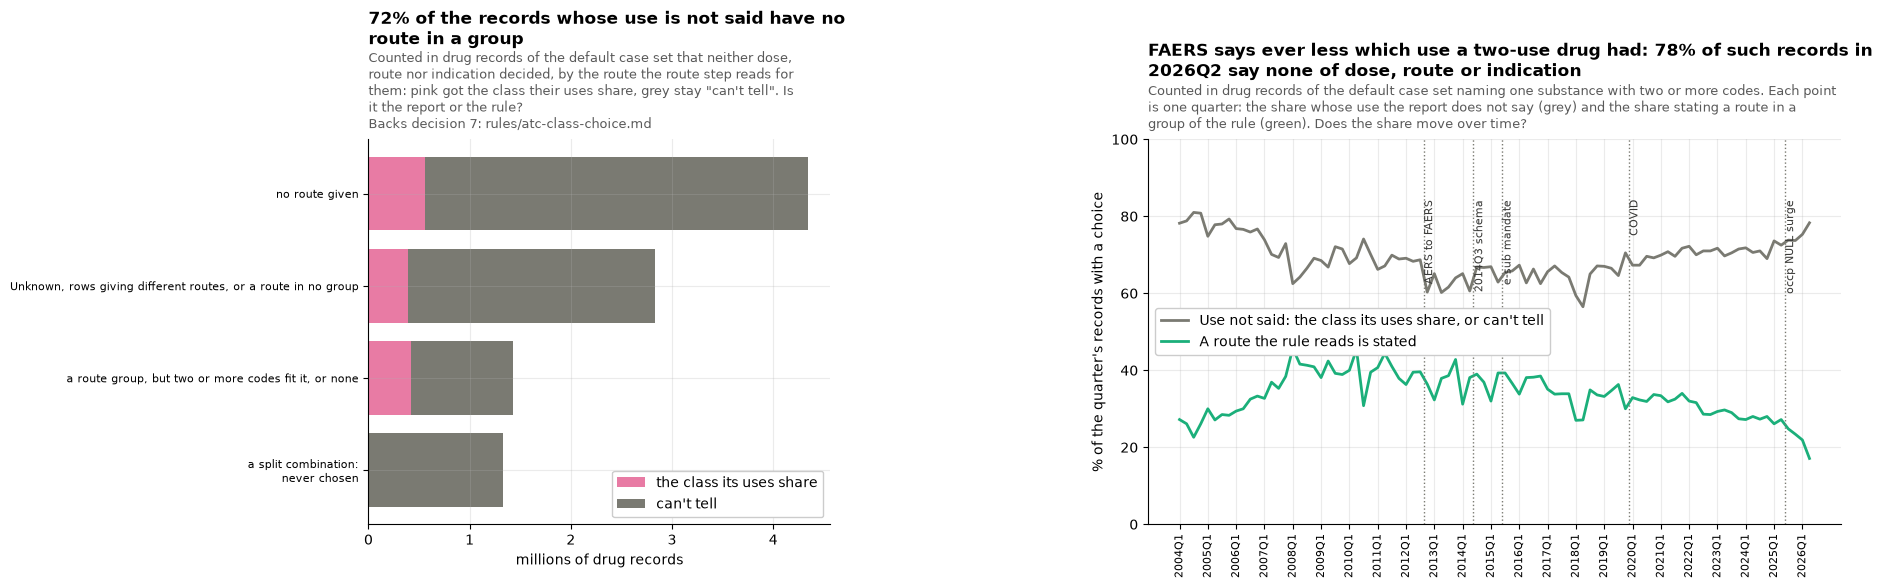

,shared_class,cannot_tell,records,cases
why_T,,,,
no route given,562723,3785212,4347935,2372569
"Unknown, rows giving different routes, or a route in no group",386408,2449039,2835447,1509067
"a route group, but two or more codes fit it, or none",424703,1004715,1429418,925550
a split combination: never chosen,0,1333775,1333775,959138


In [11]:
# Every record with a choice to make that neither dose, route nor indication decided, by what its report says
# about the route, as the route step reads it; a split combination apart, which is never chosen
con.execute("""CREATE TABLE unsaid_T AS
SELECT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, r.case_key_T, r.atc_chosen_by_T AS chosen_by_T,
       r.atc_matched_on_T AS matched_on_T, d.route_T,
       CASE WHEN r.atc_matched_on_T = 'each_ingredient' THEN 'a split combination: never chosen'
            WHEN d.route_T IS NULL THEN 'no route given'
            WHEN x.group_T IS NULL THEN 'Unknown, rows giving different routes, or a route in no group'
            ELSE 'a route group, but two or more codes fit it, or none' END AS why_T
FROM rec_T r LEFT JOIN drug_route_T d USING (era_T, primaryid, quarter_T, drug_seq)
LEFT JOIN routes_df x ON x.route_T = d.route_T
WHERE r.atc_chosen_by_T IN ('cannot_tell', 'shared_class')""")
WHY = [
    "no route given",
    "Unknown, rows giving different routes, or a route in no group",
    "a route group, but two or more codes fit it, or none",
    "a split combination: never chosen",
]
why = (
    q("""SELECT why_T, count(*) FILTER (WHERE chosen_by_T = 'shared_class') AS shared_class,
                  count(*) FILTER (WHERE chosen_by_T = 'cannot_tell') AS cannot_tell, count(*) AS records,
                  count(DISTINCT case_key_T) AS cases
           FROM unsaid_T GROUP BY 1""")
    .set_index("why_T")
    .reindex(WHY)
    .fillna(0)
    .astype(int)
)
# by quarter, as the rules-page card computes it: of the single-substance records with two or
# more codes, the share whose use the report does not say, and the share stating a route
use_card = compute_cards(con, ["two_use_drug_use_not_said"])[0]
byq = pd.DataFrame(
    {s["name"]: s["values"] for s in use_card["chart"]["series"]},
    index=use_card["chart"]["x"]["values"],
)
fig, (a1, a2) = plt.subplots(
    1, 2, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 1.5], "wspace": 0.55}
)
y = np.arange(len(WHY))
a1.barh(y, why.shared_class / 1e6, color=SERIES[4], label="the class its uses share")
a1.barh(y, why.cannot_tell / 1e6, left=why.shared_class / 1e6, color=SERIES[6], label="can't tell")
a1.set_yticks(y)
a1.set_yticklabels([w.replace(": ", ":\n", 1) for w in WHY], fontsize=8)
a1.invert_yaxis()
a1.set_xlabel("millions of drug records")
a1.legend(loc="lower right", framealpha=1)
title(
    a1,
    f"{100 * why.records.iloc[:2].sum() / why.records.sum():.0f}% of the records whose use is not said have no route "
    "in a group",
    "Counted in drug records of the default case set that neither dose, route nor indication decided, by the route the "
    'route step reads for them: pink got the class their uses share, grey stay "can\'t tell".',
    "Is it the report or the rule?",
    backs(7, "atc-class-choice"),
    width=70,
)
x = np.arange(len(byq))
for (name, values), c in zip(byq.items(), [SERIES[6], SERIES[2]], strict=True):
    a2.plot(x, values, color=c, label=name)
quarters = [v.lower() for v in byq.index]
quarter_ticks(a2, quarters)
mark_quarters(a2, quarters)
a2.set_ylim(0, 100)
a2.set_ylabel("% of the quarter's records with a choice")
a2.legend(loc="center left", framealpha=1)
title(
    a2,
    f"FAERS says ever less which use a two-use drug had: {byq.iloc[-1, 0]:.0f}% of such records in {byq.index[-1]} "
    "say none of dose, route or indication",
    "Counted in drug records of the default case set naming one substance with two or more codes. Each point is one "
    "quarter: the share whose use the report does not say (grey) and the share stating a route in a group of the rule "
    "(green).",
    "Does the share move over time?",
    width=105,
)
plt.show()
why

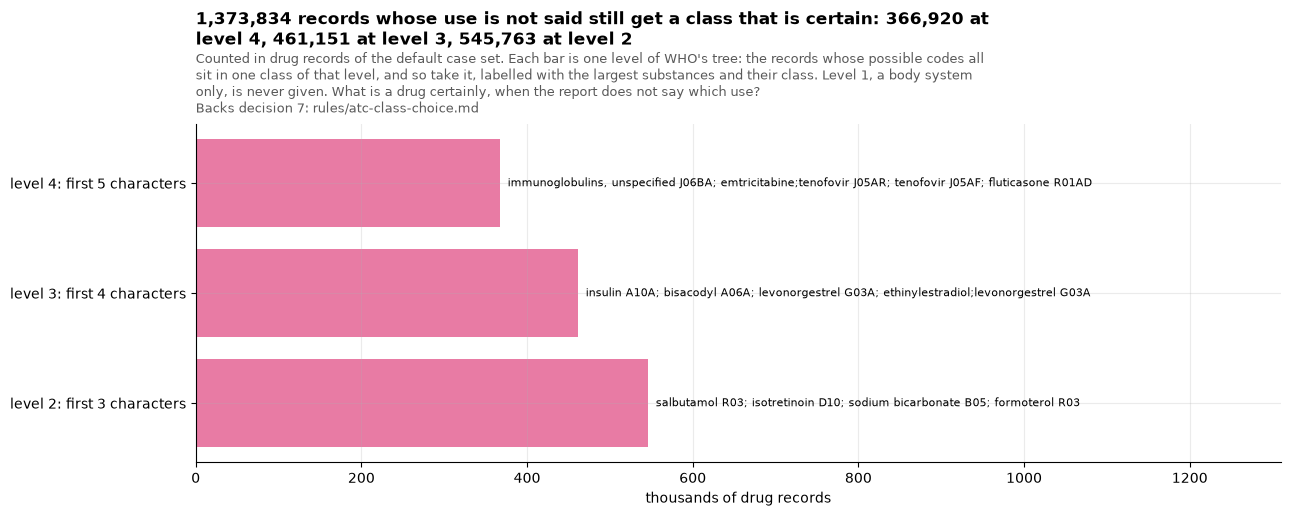

,records,cases
level,,
4,366920,235849
3,461151,338236
2,545763,455864


who_name                                      substance_T  records   cases
level code                                                                                                                               
2     R03                         DRUGS FOR OBSTRUCTIVE AIRWAY DISEASES                                       salbutamol   407250  346052
3     A10A                                       INSULINS AND ANALOGUES                                          insulin   335349  228150
4     J06BA                               Immunoglobulins, normal human                     immunoglobulins, unspecified   147464   89075
      J05AR    Antivirals for treatment of HIV infections, combinations                          emtricitabine;tenofovir    83554   59701
      J05AF  Nucleoside and nucleotide reverse transcriptase inhibitors                                        tenofovir    53920   46234
2     D10                                        ANTI-ACNE PREPARATIONS                                     isotretinoin    53170   41764
      B05                     BLOOD SUBSTITUTES AND PERFUSION SOLUTIONS                               sodium bicarbonate    30745   27655
3     A06A                                       DRUGS FOR CONSTIPATION                                        bisacodyl    28786   24986
4     R01AD                                             Corticosteroids                                      fluticasone    23597   22503
      J05AR    Antivirals for treatment of HIV infections, combinations  cobicistat;elvitegravir;emtricitabine;tenofovir    22743   17039
3     G03A                     HORMONAL CONTRACEPTIVES FOR SYSTEMIC USE                                   levonorgestrel    20712   19789
      G03A                     HORMONAL CONTRACEPTIVES FOR SYSTEMIC USE                  ethinylestradiol;levonorgestrel    16953   15756
      G03A                     HORMONAL CONTRACEPTIVES FOR SYSTEMIC USE                    ethinylestradiol;norgestimate    16140   14561
4     R03BA                                             Glucocorticoids                                      fluticasone    16075   15298
3     V03A                               ALL OTHER THERAPEUTIC PRODUCTS                                          ethanol    15285   15049

In [12]:
# The class a record's uses share, by its level: what the record certainly is when the report does
# not say which use
shared = q("""SELECT r.atc_level_T AS level, r.atc_code_T AS code, any_value(i.atc_name_T) AS who_name,
                     r.substance_T, count(*) AS records, count(DISTINCT r.case_key_T) AS cases
              FROM rec_T r JOIN atc_index_T i USING (atc_code_T)
              WHERE r.atc_chosen_by_T = 'shared_class' GROUP BY ALL""")
LEVELS = sorted(CHOICE["shared_class_levels"], reverse=True)
by_level = shared.groupby("level")[["records"]].sum().reindex(LEVELS).fillna(0).astype(int)
cases_by_level = (
    q("""SELECT atc_level_T AS level, count(DISTINCT case_key_T) AS cases FROM rec_T
                      WHERE atc_chosen_by_T = 'shared_class' GROUP BY 1""")
    .set_index("level")
    .reindex(LEVELS)
)
by_level["cases"] = cases_by_level.cases.fillna(0).astype(int)
tops = shared.sort_values("records", ascending=False).groupby("level").head(4)
fig, ax = plt.subplots(figsize=(14, 4.4))
y = np.arange(len(LEVELS))
bars = ax.barh(y, by_level.records / 1e3, color=SERIES[4])
for b, level in zip(bars, LEVELS, strict=True):
    eg = tops[tops.level == level]
    text = "; ".join(f"{s} {c}" for s, c in zip(eg.substance_T, eg.code, strict=True))
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {text}", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(
    [f"level {lv}: first {n} characters" for lv, n in zip(LEVELS, [5, 4, 3], strict=True)]
)
ax.invert_yaxis()
ax.set_xlim(0, by_level.records.max() / 1e3 * 2.4)
ax.set_xlabel("thousands of drug records")
title(
    ax,
    f"{by_level.records.sum():,} records whose use is not said still get a class that is certain: "
    + ", ".join(f"{n:,} at level {lv}" for lv, n in by_level.records.items()),
    "Counted in drug records of the default case set. Each bar is one level of WHO's tree: the records whose possible "
    "codes all sit in one class of that level, and so take it, labelled with the largest substances and their class. "
    "Level 1, a body system only, is never given.",
    "What is a drug certainly, when the report does not say which use?",
    backs(7, "atc-class-choice"),
    width=125,
)
plt.show()
display(by_level)
shared.sort_values("records", ascending=False).head(15).set_index(["level", "code"])

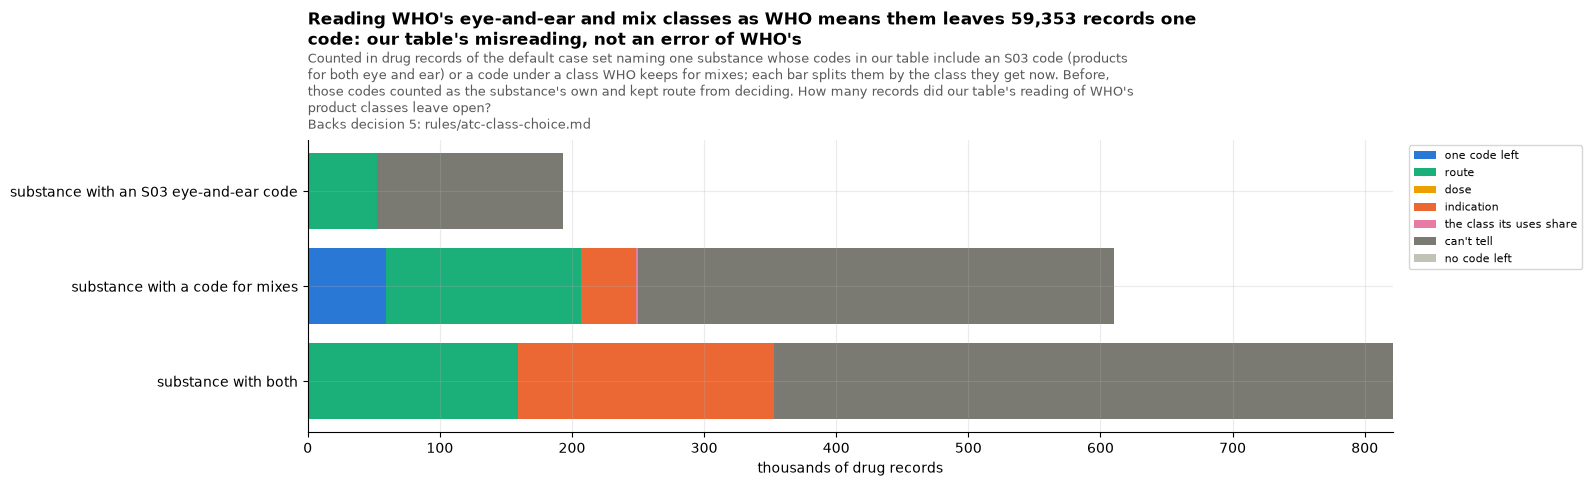

one code left once the mix codes are set aside: 59,353 records; eye or ear routes taking the S01 or S02 code before S03: 11,020 records


outcome,only_code,route,dose,indication,shared_class,cannot_tell,no code left
kind,,,,,,,
an S03 eye-and-ear code,0,52592,0,0,0,140810,0
a code for mixes,59353,147814,0,41616,1035,360556,0
both,0,158997,0,193891,0,468300,0


,substance_T,kind,now,code,records
0,desoximetasone,a code for mixes,only_code,D07AC03,44149
1,flumetasone,a code for mixes,only_code,D07AB03,7654
2,dexamethasone,both,route,S01BA01,4468
3,prednisolone,both,route,S01BA04,4440
4,estriol,a code for mixes,only_code,G03CA04,2498
5,lopinavir,a code for mixes,only_code,J05AR10,2266
6,diflucortolone,a code for mixes,only_code,D07AC06,886
7,sacubitril,a code for mixes,only_code,C09DX04,772
8,ciprofloxacin,an S03 eye-and-ear code,route,S01AE03,570
9,gentamicin,an S03 eye-and-ear code,route,S01AA11,433


,records
kind,
a code for mixes,610374
an S03 eye-and-ear code,193402
both,821188


In [13]:
# WHO's eye-and-ear class (S03) and its classes for mixes, which our table, keyed by substance, reads
# as a substance's own codes. For each one-ingredient record whose substance has such a code in the
# table, what the choice gives now that it reads them as WHO means them.
def under(code, prefixes):
    return any(code.startswith(p) for p in prefixes)


kinds_of = (
    TABLE[(TABLE.ingredient != "") & ~TABLE.ingredient.str.contains(";")]
    .assign(
        s03=lambda t: t.atc_code.map(lambda c: under(c, CHOICE["eye_and_ear_codes"])),
        mix=lambda t: t.atc_code.map(lambda c: under(c, CHOICE["mix_classes"])),
    )
    .groupby("ingredient")[["s03", "mix"]]
    .any()
    .reset_index()
)
kinds_of = kinds_of[kinds_of.s03 | kinds_of.mix]
kinds_of["kind"] = np.where(
    kinds_of.s03 & kinds_of.mix,
    "both",
    np.where(kinds_of.s03, "an S03 eye-and-ear code", "a code for mixes"),
)
con.register("misread_df", kinds_of[["ingredient", "kind"]])
OUTCOMES = [
    "only_code",
    "route",
    "dose",
    "indication",
    "shared_class",
    "cannot_tell",
    "no code left",
]
misread = q("""SELECT m.kind, coalesce(r.atc_chosen_by_T, 'no code left') AS outcome, count(*) AS records,
                      count(DISTINCT r.case_key_T) AS cases
               FROM rec_T r JOIN misread_df m ON m.ingredient = r.substance_T
               WHERE NOT contains(r.substance_T, ';') GROUP BY ALL""")
grid = (
    misread.pivot_table(index="kind", columns="outcome", values="records", aggfunc="sum")
    .reindex(columns=OUTCOMES)
    .fillna(0)
)
grid = grid.loc[["an S03 eye-and-ear code", "a code for mixes", "both"]]
# what reading them so settled: a record left one code once the mix codes are set aside, and an eye
# or ear record whose route now takes its S01 or S02 code before S03
settled = q("""SELECT count(*) FILTER (WHERE r.atc_chosen_by_T = 'only_code' AND m.kind <> 'an S03 eye-and-ear code') AS one_code_left,
                      count(*) FILTER (WHERE r.atc_chosen_by_T = 'route' AND m.kind <> 'a code for mixes'
                                        AND (r.atc_code_T LIKE 'S01%' OR r.atc_code_T LIKE 'S02%')) AS eye_or_ear_by_route
               FROM rec_T r JOIN misread_df m ON m.ingredient = r.substance_T WHERE NOT contains(r.substance_T, ';')""").iloc[
    0
]
fig, ax = plt.subplots(figsize=(14, 3.8))
left = np.zeros(len(grid))
colors = dict(
    zip(
        OUTCOMES,
        [SERIES[0], SERIES[2], SERIES[3], SERIES[1], SERIES[4], SERIES[6], SERIES[7]],
        strict=True,
    )
)
labels = {
    "only_code": "one code left",
    "shared_class": "the class its uses share",
    "cannot_tell": "can't tell",
}
for o in OUTCOMES:
    ax.barh(
        np.arange(len(grid)),
        grid[o] / 1e3,
        left=left,
        color=colors[o],
        label=labels.get(o, o.replace("_", " ")),
    )
    left += grid[o].to_numpy() / 1e3
ax.set_yticks(np.arange(len(grid)))
ax.set_yticklabels([f"substance with {k}" for k in grid.index])
ax.invert_yaxis()
ax.set_xlabel("thousands of drug records")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
title(
    ax,
    f"Reading WHO's eye-and-ear and mix classes as WHO means them leaves {settled.one_code_left:,} records one code: "
    "our table's misreading, not an error of WHO's",
    "Counted in drug records of the default case set naming one substance whose codes in our table include an S03 code "
    "(products for both eye and ear) or a code under a class WHO keeps for mixes; each bar splits them by the class "
    "they get now. Before, those codes counted as the substance's own and kept route from deciding.",
    "How many records did our table's reading of WHO's product classes leave open?",
    backs(5, "atc-class-choice"),
    width=125,
)
plt.show()
print(
    f"one code left once the mix codes are set aside: {settled.one_code_left:,} records; eye or ear routes taking "
    f"the S01 or S02 code before S03: {settled.eye_or_ear_by_route:,} records"
)
display(grid.astype(int))
# the substances whose records the reading settled
display(
    q("""SELECT r.substance_T, m.kind, r.atc_chosen_by_T AS now, r.atc_code_T AS code, count(*) AS records
         FROM rec_T r JOIN misread_df m ON m.ingredient = r.substance_T
         WHERE NOT contains(r.substance_T, ';')
           AND ((r.atc_chosen_by_T = 'only_code' AND m.kind <> 'an S03 eye-and-ear code')
                OR (r.atc_chosen_by_T = 'route' AND m.kind <> 'a code for mixes'
                    AND (r.atc_code_T LIKE 'S01%' OR r.atc_code_T LIKE 'S02%')))
         GROUP BY ALL ORDER BY records DESC LIMIT 12""")
)
misread.groupby("kind")[["records"]].sum()

**What section 4 shows**, one item per chart:

- **Why the use is not said, and how that changes.** *Shows:* in drug records: of the records neither dose, route nor indication decided, 72% have no route in a group: 4.35 million give no route, and 2.84 million give `Unknown`, rows of different routes, which the route step reads as `Unknown`, or a route in no group; 1.43 million have a route group in which two or more codes fit or none, and 1.33 million are split combinations. By quarter, of the records of substances with two or more codes, the share whose use the report does not say rose from 62% in 2018 to 78% in 2026Q2, while the share whose route is in a group fell to 17%. *Point:* it is the report, not the rule: FAERS states a route ever less often, so it says ever less which use a two-use drug had. *So what:* the shared class and "can't tell" (decision 7) and the "could be" tick (decision 8) matter more each year; the shared route step, which reads routes from the dose form too, could narrow it (decision 5). This is the rules-page card `two_use_drug_use_not_said`.
- **The class a record's uses share, by level.** *Shows:* in drug records: 1,373,825 records whose use is not said get a class that is certain: 366,917 at level 4 (human immunoglobulin J06BA, read through FDA's words; emtricitabine with tenofovir, as in Truvada, J05AR; tenofovir J05AF; nasal fluticasone R01AD and inhaled fluticasone R03BA, each over the codes its route fits), 461,151 at level 3 (human insulin A10A, 335,349 records; levonorgestrel by mouth and the combined pills, G03A; bisacodyl, A06A) and 545,757 at level 2 (salbutamol R03, 407,247 records; isotretinoin D10; sodium bicarbonate B05). *Point:* certain, not a guess: whichever use the report meant, the drug is in that class. *So what:* decision 7 as built; the class carries its level (`atc_level_T`), so a filter on a deeper class does not count it unless "could be" is ticked.
- **Our table's reading of WHO's product classes.** *Shows:* in drug records naming one substance whose codes in our table include an S03 code (193,391 records), a code for mixes (608,803) or both (821,183). Reading them as WHO means them leaves 59,353 records one code (desoximetasone 44,149, flumetasone, estriol, lopinavir) and lets an eye or ear route take its S01 or S02 code for 11,020 records (eye drops of dexamethasone, prednisolone, ciprofloxacin, gentamicin); 235,506 of these records now take their class by indication, and most of the rest stay "can't tell" for want of a route. *Point:* this was our table's misreading of WHO's product classes, not an error of WHO's: WHO classes products, and some product classes carry one substance's name. *So what:* decision 5 as built, and the rule file says it is our table's reading.

When the report does not say which use, a drug still gets the class all its uses share if there is one, and only otherwise "can't tell"; FAERS states a route ever less often, so this matters more each year. Part of what looked like "can't tell" was our own table reading WHO's eye-and-ear and mix classes as a substance's own codes, which it now reads as WHO means them.

## 5 · Cross-check against DiAna's ATC file

DiAna publishes its own ATC file on OSF (`ATC_binder_2025.csv`), with a fixed primary code for each substance. It is not our source (`rules/atc-index.md`); here it only checks our step. **The cases are ours.** DiAna's file is a table of substances and codes, so it is looked up for each of our drug records, on our default case set: the comparison is of two ways of classing the same records, not of DiAna's own case counts with ours, and DiAna counting fewer cases elsewhere does not enter it.

The check is split in two, because the two halves ask different questions. For a **drug with one class**, both files copy WHO's index, so they should agree, and any difference is a copying slip or a different index year. For a **drug with two uses**, DiAna's file always gives its one primary code, while ours follows the report's route and dose; a difference there is the point of choosing, not an error. Some names in DiAna's file start with a tab, which is taken off, and a substance DiAna's file gives two primary codes counts as agreeing with either.

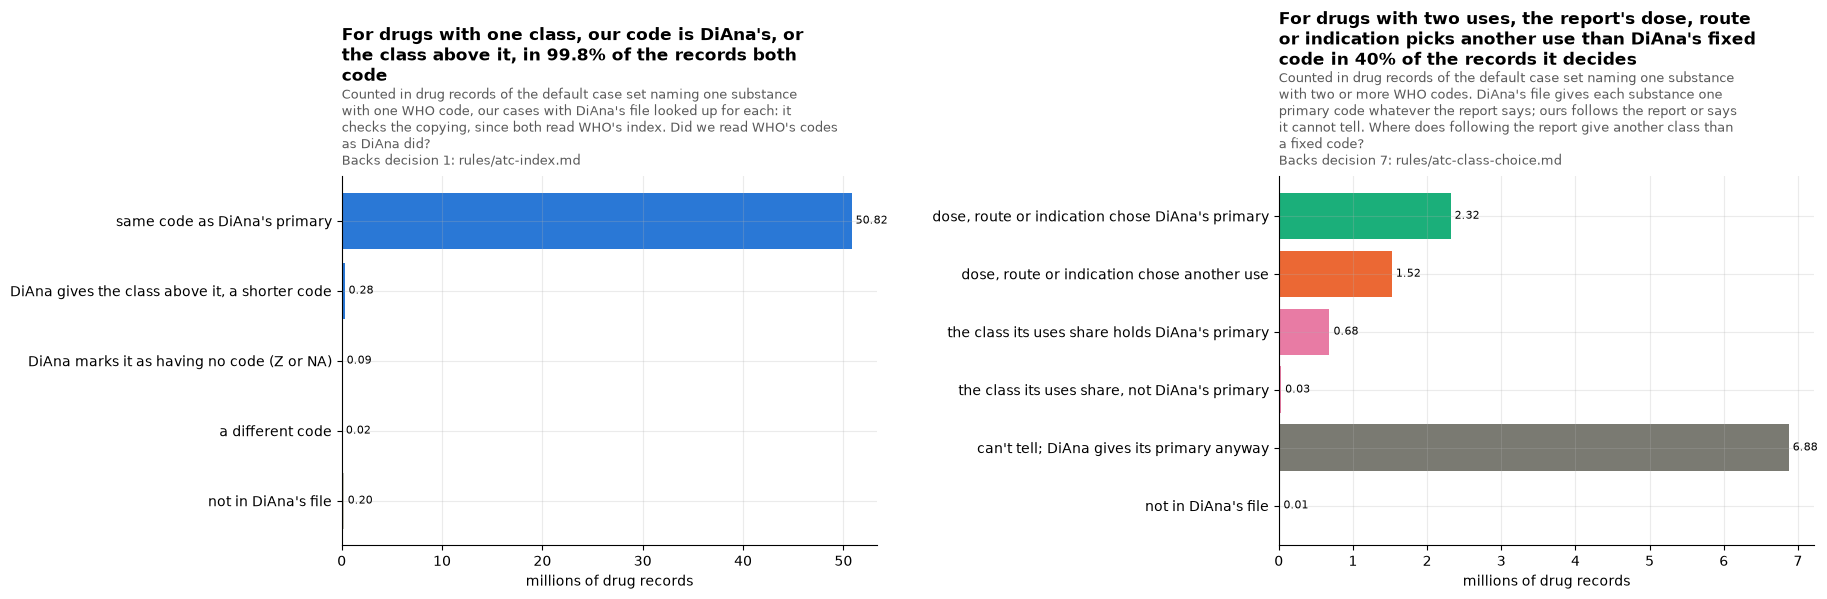

single-substance records whose substance DiAna's file lacks: 206,228 records, 149,867 cases


cases   records
drug             comparison                                                         
one class        DiAna gives the class above it, a shorter code     256530    283443
                 DiAna marks it as having no code (Z or NA)          84211     94437
                 a different code                                    13201     15987
                 not in DiAna's file                                141714    196953
                 same code as DiAna's primary                     17104781  50824687
two or more uses can't tell; DiAna gives its primary anyway        3732082   6875491
                 dose, route or indication chose DiAna's primary   1487600   2316824
                 dose, route or indication chose another use       1061717   1524752
                 not in DiAna's file                                  8167      9275
                 the class its uses share holds DiAna's primary     568813    683986
                 the class its uses share, not DiAna's primary       31121     32181

In [14]:
if DIANA_ATC is None:
    print("OPEN_ALTIO_DIANA_ATC is not set: the cross-check is skipped")
else:
    # DiAna's file, one row per substance and code with its fixed primary code; a few names start
    # with a tab, which trim() keeps, so every edge space is taken off
    con.execute(f"""CREATE TABLE binder_T AS
        SELECT lower(regexp_replace(Substance, '^\\s+|\\s+$', '', 'g')) AS substance_T,
               regexp_replace(code, '^\\s+|\\s+$', '', 'g') AS code_T,
               regexp_replace(primary_code, '^\\s+|\\s+$', '', 'g') AS primary_T
        FROM read_csv({quoted(DIANA_ATC.as_posix())}, delim=';', header=true, all_varchar=true) WHERE Substance IS NOT NULL""")
    # a substance is in DiAna's file under its own name or under the WHO name a bridge gives it;
    # DiAna gives some substances two primary codes, so every primary counts
    bridges = pd.read_csv(repo_path("atc-spelling-bridges", "mapping"))
    con.register("bridges_df", bridges)
    con.execute("""CREATE TABLE diana_T AS
        WITH names AS (SELECT DISTINCT substance_T FROM rec_T WHERE atc_matched_on_T = 'substance'
                                                                 AND atc_chosen_by_T <> 'group_class'),
        spelt AS (SELECT n.substance_T, coalesce(b.who_name, n.substance_T) AS diana_name_T FROM names n
                  LEFT JOIN bridges_df b ON b.substance = n.substance_T
                  UNION SELECT substance_T, substance_T FROM names)
        SELECT s.substance_T, list(DISTINCT p.primary_T) AS primaries_T
        FROM spelt s JOIN binder_T p ON p.substance_T = s.diana_name_T GROUP BY 1""")
    ONE = [
        "same code as DiAna's primary",
        "DiAna gives the class above it, a shorter code",
        "DiAna marks it as having no code (Z or NA)",
        "a different code",
        "not in DiAna's file",
    ]
    TWO = [
        "dose, route or indication chose DiAna's primary",
        "dose, route or indication chose another use",
        "the class its uses share holds DiAna's primary",
        "the class its uses share, not DiAna's primary",
        "can't tell; DiAna gives its primary anyway",
        "not in DiAna's file",
    ]
    cmp = q(f"""WITH r AS (
      SELECT r.*, d.primaries_T FROM rec_T r LEFT JOIN diana_T d USING (substance_T)
      WHERE r.atc_matched_on_T = 'substance' AND r.atc_chosen_by_T <> 'group_class')
    SELECT CASE WHEN atc_possible_codes_T = 1 THEN 'one class' ELSE 'two or more uses' END AS drug,
           CASE WHEN primaries_T IS NULL THEN 'not in DiAna''s file'
                WHEN atc_possible_codes_T = 1 THEN CASE
                     WHEN list_contains(primaries_T, atc_code_T) THEN {quoted(ONE[0])}
                     WHEN len(list_filter(primaries_T, lambda p: starts_with(atc_code_T, p))) > 0 THEN {quoted(ONE[1])}
                     WHEN len(list_filter(primaries_T, lambda p: p IN ('Z', 'NA'))) > 0 THEN {quoted(ONE[2])}
                     ELSE {quoted(ONE[3])} END
                WHEN atc_chosen_by_T IN ('route', 'dose', 'indication') THEN CASE
                     WHEN list_contains(primaries_T, atc_code_T) THEN {quoted(TWO[0])} ELSE {quoted(TWO[1])} END
                WHEN atc_chosen_by_T = 'shared_class' THEN CASE
                     WHEN len(list_filter(primaries_T, lambda p: starts_with(p, atc_code_T))) > 0 THEN {quoted(TWO[2])}
                     ELSE {quoted(TWO[3])} END
                ELSE {quoted(TWO[4])} END AS comparison,
           count(*) AS records, count(DISTINCT case_key_T) AS cases
    FROM r GROUP BY ALL""")
    one = cmp[cmp.drug == "one class"].set_index("comparison").reindex(ONE).fillna(0)
    two = cmp[cmp.drug == "two or more uses"].set_index("comparison").reindex(TWO).fillna(0)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(19, 4.8), gridspec_kw={"wspace": 0.75})
    y = np.arange(len(ONE))
    b = a1.barh(y, one.records / 1e6, color=[SERIES[0], SERIES[0], SERIES[6], SERIES[1], SERIES[7]])
    label_bars(a1, b, "{:.2f}", horizontal=True)
    a1.set_yticks(y)
    a1.set_yticklabels(ONE)
    a1.invert_yaxis()
    a1.set_xlabel("millions of drug records")
    named = one.drop(index="not in DiAna's file")
    title(
        a1,
        f"For drugs with one class, our code is DiAna's, or the class above it, in "
        f"{100 * named.records.iloc[:2].sum() / named.records.sum():.1f}% of the records both code",
        "Counted in drug records of the default case set naming one substance with one WHO code, our cases with DiAna's "
        "file looked up for each: it checks the copying, since both read WHO's index.",
        "Did we read WHO's codes as DiAna did?",
        backs(1, "atc-index"),
        width=72,
    )
    y = np.arange(len(TWO))
    b = a2.barh(
        y,
        two.records / 1e6,
        color=[SERIES[2], SERIES[1], SERIES[4], SERIES[4], SERIES[6], SERIES[7]],
    )
    label_bars(a2, b, "{:.2f}", horizontal=True)
    a2.set_yticks(y)
    a2.set_yticklabels(TWO)
    a2.invert_yaxis()
    a2.set_xlabel("millions of drug records")
    chose = two.loc[TWO[:2], "records"]
    title(
        a2,
        f"For drugs with two uses, the report's dose, route or indication picks another use than DiAna's fixed code in "
        f"{100 * chose.iloc[1] / chose.sum():.0f}% of the records it decides",
        "Counted in drug records of the default case set naming one substance with two or more WHO codes. DiAna's file "
        "gives each substance one primary code whatever the report says; ours follows the report or says it cannot tell.",
        "Where does following the report give another class than a fixed code?",
        backs(7, "atc-class-choice"),
        width=72,
    )
    plt.show()
    # one count of the substances DiAna's file lacks, the same in section 6
    NOT_IN_DIANA = con.execute("""SELECT count(DISTINCT case_key_T), count(*) FROM rec_T
        WHERE atc_matched_on_T = 'substance' AND atc_chosen_by_T <> 'group_class'
          AND substance_T NOT IN (SELECT substance_T FROM diana_T)""").fetchone()
    print(
        f"single-substance records whose substance DiAna's file lacks: {NOT_IN_DIANA[1]:,} records, {NOT_IN_DIANA[0]:,} cases"
    )
    display(
        cmp.pivot_table(index=["drug", "comparison"], values=["records", "cases"], aggfunc="sum")
    )
    q("""SELECT r.substance_T, r.atc_code_T AS ours, array_to_string(d.primaries_T, ', ') AS diana, count(*) AS records
         FROM rec_T r JOIN diana_T d USING (substance_T)
         WHERE r.atc_possible_codes_T = 1 AND r.atc_matched_on_T = 'substance' AND NOT list_contains(d.primaries_T, r.atc_code_T)
           AND len(list_filter(d.primaries_T, lambda p: starts_with(r.atc_code_T, p) OR p IN ('Z', 'NA'))) = 0
         GROUP BY ALL ORDER BY 4 DESC LIMIT 12""")

**What section 5 shows**, one item per chart:

- **One-class drugs against DiAna's file, and two-use drugs against its fixed code.** *Shows:* in drug records, group classes left out: for drugs with one class, our code is DiAna's primary on 50.82 million records and the class above it on 283,443 (DiAna writes the class, B03BA for vitamin B12, where WHO codes the substance): 99.8% of the records both code. DiAna marks 94,434 as having no code (Z or NA, for senna and lactobacillus), and 15,987 records (13,201 cases) carry a genuinely different code. For drugs with two uses, dose, route or indication chose DiAna's primary on 2.32 million records and another use on 1.52 million, 40% of the records they decide; 0.68 million took a shared class that holds DiAna's code; 6.88 million are "can't tell", where DiAna gives its primary regardless. 206,359 single-substance records (149,986 cases) name a substance DiAna's file lacks, the same count as section 6. *Point:* does DiAna's smaller case count make this misleading? No: DiAna's file is looked up for our own records, so both classings count the same cases. The large agreement is the one-class drugs, where both copy WHO's index; for two-use drugs, a fixed code is the other use in four of every ten records whose report says which. *So what:* our copy of WHO's index stands (decision 1), and following the report rather than a fixed code is right (decision 7).

Where a drug has one class, our table and DiAna's agree on nearly every record, so the copying is sound. Where it has two uses, DiAna's single fixed code is the other use in four of every ten records whose dose, route or indication says which, which is why Open Altio follows the report.

## 6 · Substances only WHO's index codes

Substances that WHO coded after DiAna's file was made, or that DiAna's dictionary names differently from its own ATC file, have no class there. They are exactly section 5's "not in DiAna's file", counted the same way, in cases.

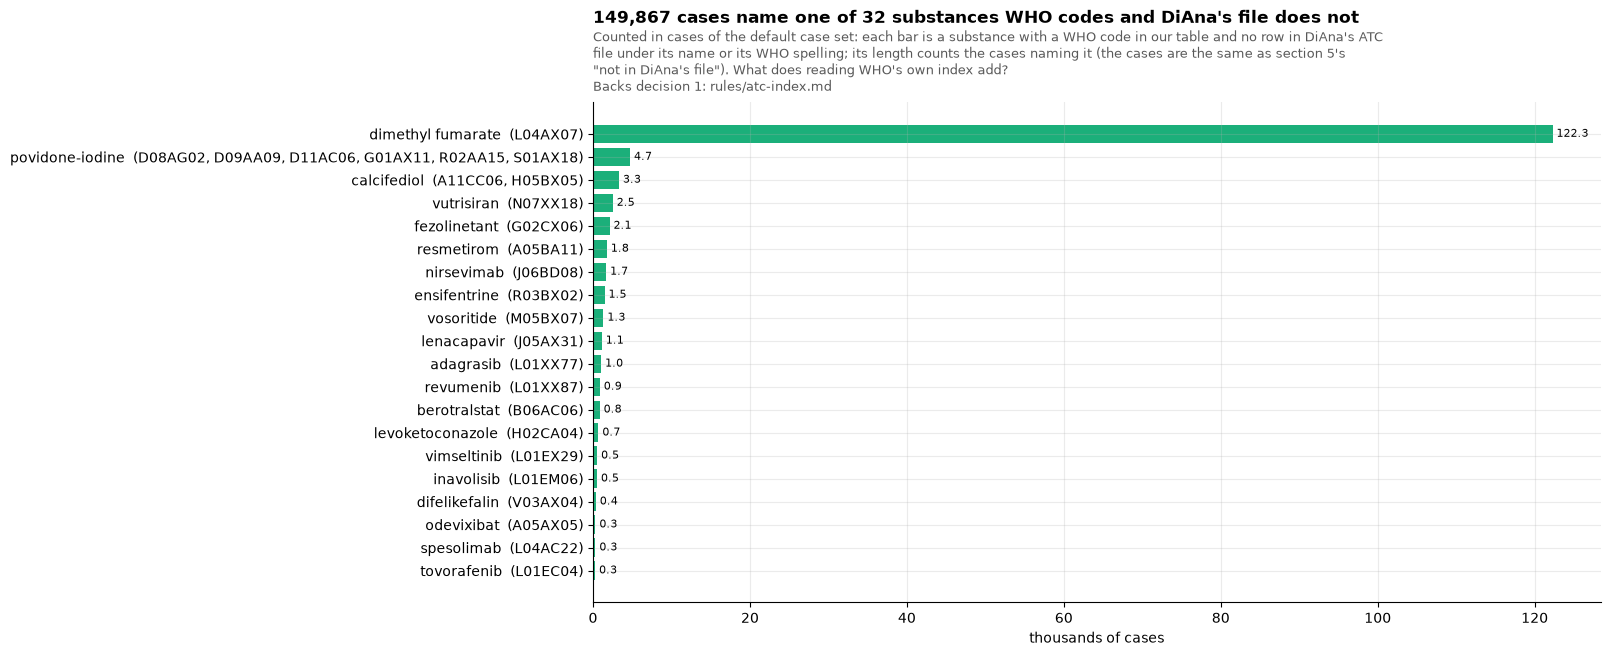

,substance_T,code,cases,records
3,vutrisiran,N07XX18,2517,2690
6,nirsevimab,J06BD08,1675,1735


cases naming vutrisiran or nirsevimab: 4,192


In [15]:
if DIANA_ATC is None:
    print("OPEN_ALTIO_DIANA_ATC is not set: this section is skipped")
else:
    # the same substances as section 5's "not in DiAna's file", with the codes our table gives them
    new = q("""SELECT r.substance_T, string_agg(DISTINCT k.atc_code_T, ', ' ORDER BY k.atc_code_T) AS code,
                      count(DISTINCT r.case_key_T) AS cases, count(DISTINCT (r.era_T, r.primaryid, r.quarter_T, r.drug_seq)) AS records
               FROM rec_T r JOIN atc_drug_codes_T k USING (era_T, primaryid, quarter_T, drug_seq)
               WHERE r.atc_matched_on_T = 'substance' AND r.atc_chosen_by_T <> 'group_class'
                 AND r.substance_T NOT IN (SELECT substance_T FROM diana_T)
               GROUP BY 1 ORDER BY 3 DESC""")
    assert new.records.sum() == NOT_IN_DIANA[1], "section 5 and section 6 count the same records"
    head = new.head(20)
    fig, ax = plt.subplots(figsize=(13, 6.5))
    y = np.arange(len(head))
    b = ax.barh(y, head.cases / 1e3, color=SERIES[2])
    label_bars(ax, b, "{:,.1f}", horizontal=True)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{s}  ({c})" for s, c in zip(head.substance_T, head.code, strict=True)])
    ax.invert_yaxis()
    ax.set_xlabel("thousands of cases")
    title(
        ax,
        f"{NOT_IN_DIANA[0]:,} cases name one of {len(new):,} substances WHO codes and DiAna's file does not",
        "Counted in cases of the default case set: each bar is a substance with a WHO code in our table and no row in "
        "DiAna's ATC file under its name or its WHO spelling; its length counts the cases naming it (the cases are the "
        "same as section 5's \"not in DiAna's file\").",
        "What does reading WHO's own index add?",
        backs(1, "atc-index"),
        width=120,
    )
    plt.show()
    display(new[new.substance_T.isin(["vutrisiran", "nirsevimab"])])
    both = con.execute(
        "SELECT count(DISTINCT case_key_T) FROM rec_T WHERE substance_T IN ('vutrisiran', 'nirsevimab')"
    ).fetchone()[0]
    print(f"cases naming vutrisiran or nirsevimab: {both:,}")

**What section 6 shows**, one item per chart:

- **Substances only WHO's index codes.** *Shows:* in cases: 149,986 cases name one of 33 substances WHO codes and DiAna's file does not. The largest is dimethyl fumarate (Tecfidera, 122,273 cases), which our drug-name corrections read apart from fumaric acid and DiAna's file never names; povidone-iodine and calcifediol are also our corrections. Then come drugs newer than DiAna's file: vutrisiran (2,517 cases), fezolinetant, resmetirom, nirsevimab (1,675), ensifentrine, vosoritide, lenacapavir. Vutrisiran and nirsevimab together are in 4,192 cases. *Point:* reading WHO's own index classes new drugs, and our corrected names, at once. *So what:* decision 1: each release reads the newest index at its build.

A drug approved after DiAna's file was made, or a name our corrections fixed, still gets WHO's class, because Open Altio reads WHO's index itself. Tecfidera, read correctly as dimethyl fumarate, is most of them.

## 7 · What each bridge codes

Each row of `mappings/faers/atc/bridges.csv` joins a word WHO writes to a substance DiAna writes (`rules/atc-spelling-bridges.md`). The count is of cases with a drug record whose code came through that row: the record's substance (or one of its ingredients) is the bridge's substance, and WHO's name of the code holds the bridge's word. The rows the review approved are in (section 9), so the chart shows the 30 that code the most cases, and the table every row. A row that codes no case would not be kept.

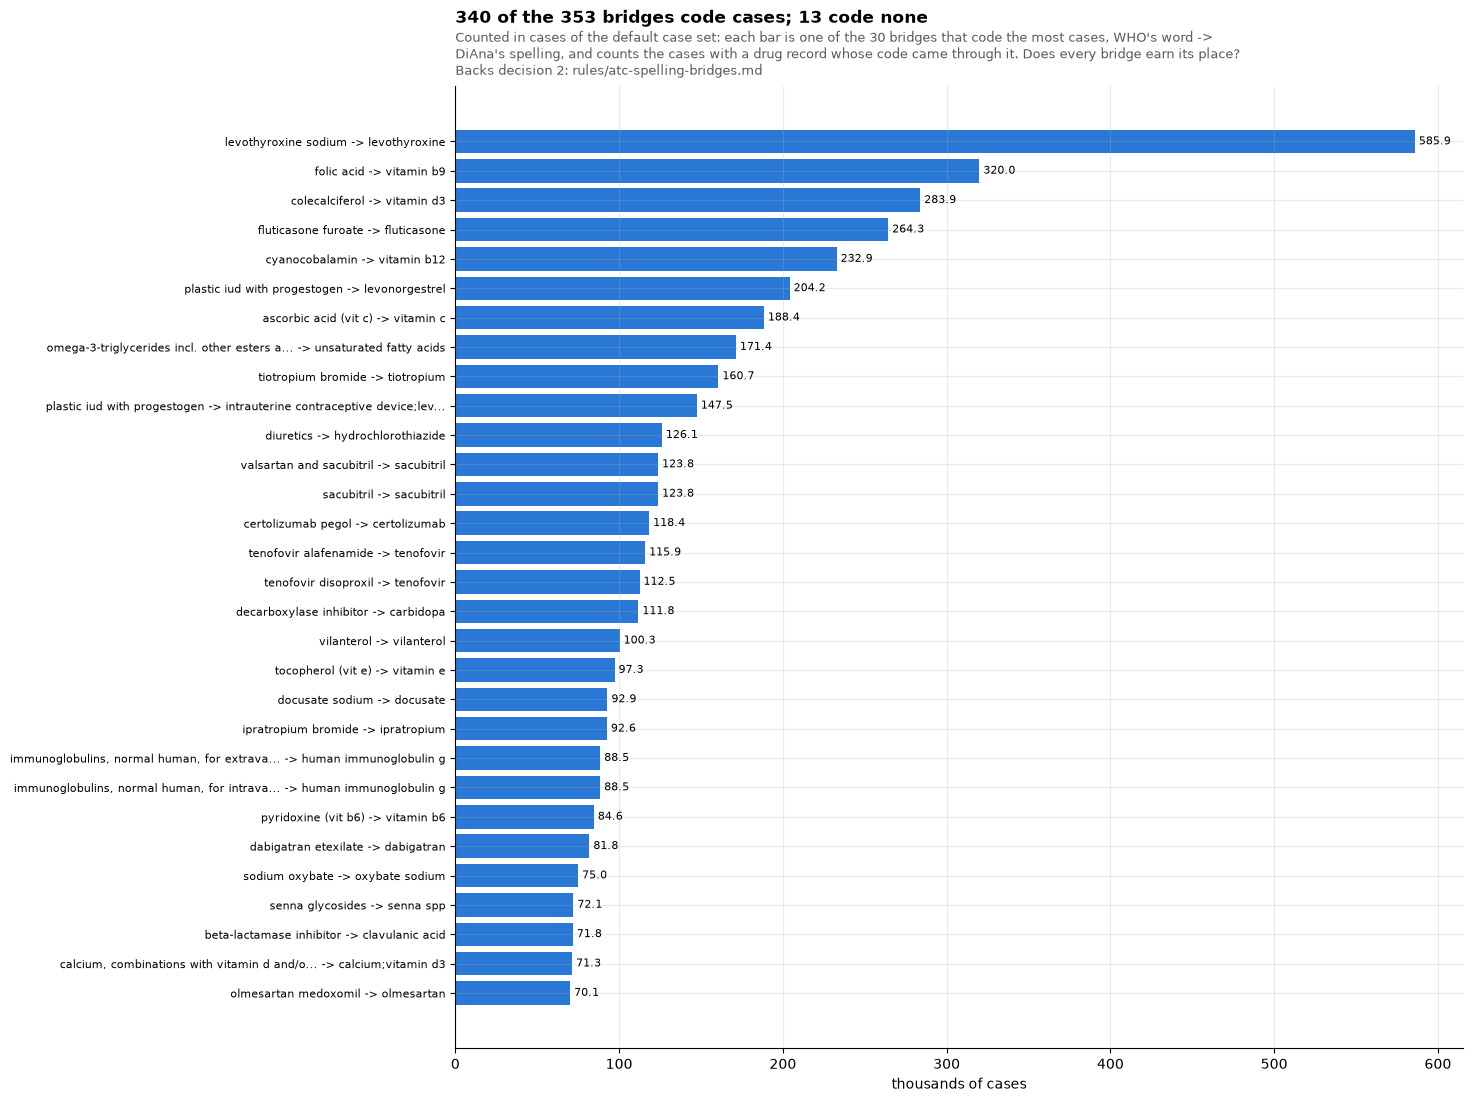

bridges that code no case:


,who_name,substance,evidence,cases
340,"covid-19, rna-based vaccine",imelasomeran,FDA's active ingredient names the vaccine,0
341,"covid-19, rna-based vaccine",zapomeran,FDA's spellings of an RNA Covid-19 vaccine,0
342,piflufolastat (18f),piflufolastat F18,WHO writes the isotope another way,0
343,calcitonin (salmon synthetic),calcitonin salmon,FDA's active ingredient names salmon calcitonin,0
344,"multienzymes (lipase, protease etc.)",pancrelipase lipase\pancrelipase protease\pancrelipase amylase,FDA's active ingredient pancrelipase is WHO's multienzymes,0
345,"covid-19, rna-based vaccine",bnt162b2,FDA's active ingredient names the vaccine,0
346,"covid-19, rna-based vaccine",tozinameran\riltozinameran,FDA's active ingredient names the vaccine,0
347,"covid-19, rna-based vaccine","covid-19 vaccine, mrna",FDA's spellings of an RNA Covid-19 vaccine,0
348,"covid-19, rna-based vaccine",elasomeran\davesomeran,FDA's active ingredient names the vaccine,0
349,"covid-19, rna-based vaccine",tozinameran\famtozinameran,FDA's active ingredient names the vaccine,0


,who_name,substance,evidence,cases
0,levothyroxine sodium,levothyroxine,WHO names the salt; the dictionary names the active part,585925
1,folic acid,vitamin b9,the dictionary names vitamins by letter,320022
2,colecalciferol,vitamin d3,the dictionary names vitamins by letter,283892
3,fluticasone furoate,fluticasone,WHO names the ester; the dictionary names the active part,264316
4,cyanocobalamin,vitamin b12,the dictionary names vitamins by letter,232862
...,...,...,...,...
348,"covid-19, rna-based vaccine",elasomeran\davesomeran,FDA's active ingredient names the vaccine,0
349,"covid-19, rna-based vaccine",tozinameran\famtozinameran,FDA's active ingredient names the vaccine,0
350,ciclosporin,cyclosporine,US name (USAN) in the dictionary for WHO's INN,0
351,"covid-19, rna-based vaccine",mrna-1273,FDA's active ingredient names the vaccine,0


In [16]:
bridges = pd.read_csv(repo_path("atc-spelling-bridges", "mapping"))
con.register("bridge_rows_df", bridges)
# a code came through a bridge when the record's substance (or one of its ingredients) is the
# bridge's substance, or set of substances, and WHO's name of the code holds the bridge's word
per = q("""WITH pairs AS (
  SELECT DISTINCT b.who_name, b.substance, t.ingredient, t.atc_code FROM bridge_rows_df b
  JOIN table_df t ON t.ingredient <> ''
                 AND (t.ingredient = b.substance OR list_contains(string_split(t.ingredient, ';'), b.substance))
                 AND contains(lower(t.who_name), b.who_name)),
c AS (SELECT DISTINCT p.who_name, p.substance, r.case_key_T FROM pairs p
      JOIN atc_drug_codes_T k ON k.atc_ingredient_T = p.ingredient AND k.atc_code_T = p.atc_code
      JOIN rec_T r USING (era_T, primaryid, quarter_T, drug_seq))
SELECT b.who_name, b.substance, b.evidence, count(c.case_key_T) AS cases
FROM bridge_rows_df b LEFT JOIN c USING (who_name, substance) GROUP BY ALL ORDER BY cases DESC""")
top = per.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(13, 0.35 * len(top) + 2))
y = np.arange(len(top))
b = ax.barh(y, top.cases / 1e3, color=SERIES[0])
label_bars(ax, b, "{:,.1f}", horizontal=True)
ax.set_yticks(y)
ax.set_yticklabels(
    [f"{short(w, 45)} -> {short(s, 40)}" for w, s in zip(top.who_name, top.substance, strict=True)],
    fontsize=8,
)
ax.set_xlabel("thousands of cases")
title(
    ax,
    f"{int((per.cases > 0).sum())} of the {len(per)} bridges code cases; {int((per.cases == 0).sum())} code none",
    "Counted in cases of the default case set: each bar is one of the 30 bridges that code the most cases, WHO's word -> "
    "DiAna's spelling, and counts the cases with a drug record whose code came through it.",
    "Does every bridge earn its place?",
    backs(2, "atc-spelling-bridges"),
    width=120,
)
plt.show()
print("bridges that code no case:")
display(per[per.cases == 0])
per

**What section 7 shows**, one item per chart:

- **What each bridge codes.** *Shows:* in cases: 340 of the 353 bridges code cases. Salts (levothyroxine sodium, 585,844 cases), vitamins by letter (folic acid as vitamin B9, 320,021; colecalciferol as vitamin D3, 283,891), esters (fluticasone furoate, 264,313) and the hormonal IUD (about 204,000 cases through levonorgestrel, 147,489 through the IUD with levonorgestrel) lead. The 13 that code none are FDA spellings this release's records do not write (`bnt162b2`, `mrna-1273`, `piflufolastat F18`, salmon calcitonin, pancrelipase's three parts and other Covid-19 vaccine spellings), and cyclosporine, which the drug-name step already spells ciclosporin. *Point:* nearly every bridge earns its place. *So what:* the cyclosporine row can go; an FDA spelling that codes nothing here costs nothing and may code a later quarter's records.

The reviewed bridges that join WHO's words to DiAna's spellings carry millions of cases, led by salts, vitamins and the hormonal IUD. Thirteen code nothing in this release: twelve FDA spellings its records do not use, and one the drug-name step already spells WHO's way.

## Rules-page cards from this notebook

The two cards of this notebook, computed by the same functions the release build calls (`src/open_altio/faers/insights/cards/drug_classes.py`) on the release this notebook reads, each the evidence for rule `atc-class-choice`: most aspirin reports that state a dose give the low dose of a blood thinner, and FAERS ever more often does not say which use a two-use drug had, by its dose, its route or the indication it gives. The drug classes are a layer of their own, not a step of the funnel, so both cards are tagged "Documented, not transformed"; should the classes become a funnel step, the cards link to it. Each is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT/cards/`).

A finding became a card only if it is about FDA's data, not our code; if it would move a count someone using FAERS gets, or mislead them, by enough to matter; and if it is measured on the release. Two candidates were left out. FAERS routes are sometimes wrong (diclofenac reported as an eye drop for arthritis, ibuprofen as a gel for fever), but section 3 finds a few hundred such records against 99% agreement, too few to move a count, and the indication never overrules a route (section 8). Our table's reading of WHO's eye-and-ear and mix classes (section 4) is about our code, not FDA's data.

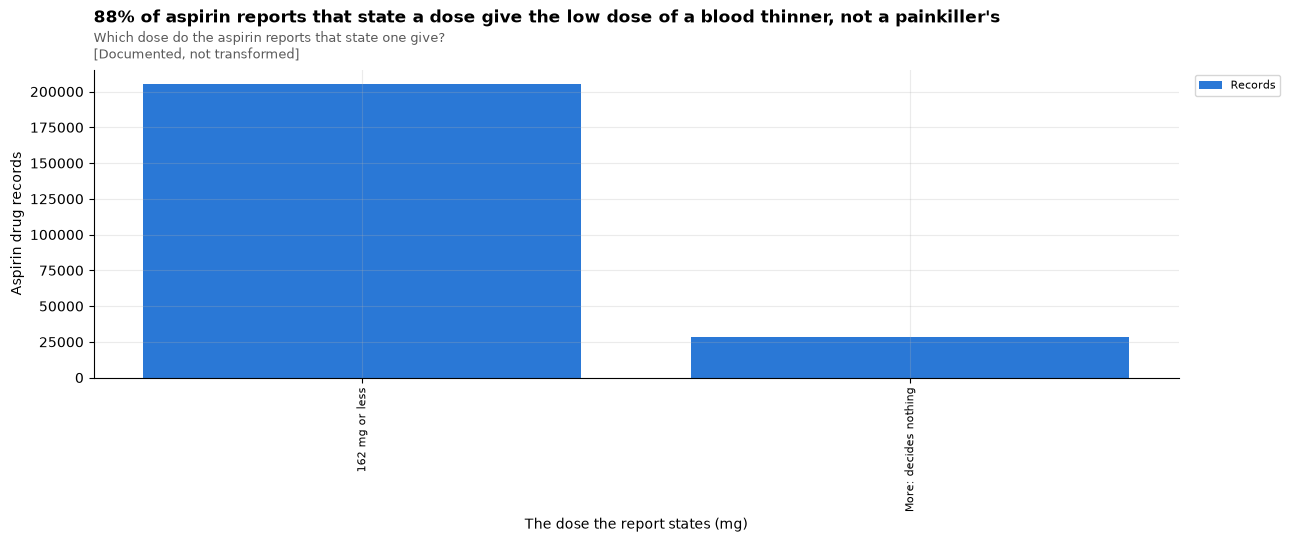

WHO classes aspirin by its use: 162 mg or less is an antithrombotic (B01AC06) and a full dose a painkiller, and of the 233,751 aspirin records that state their dose in mg, 88% give the low dose. One fixed class per substance would put one use under the other's class, so Open Altio classes aspirin by the dose its report states, and a filter on antithrombotics finds the low-dose reports.


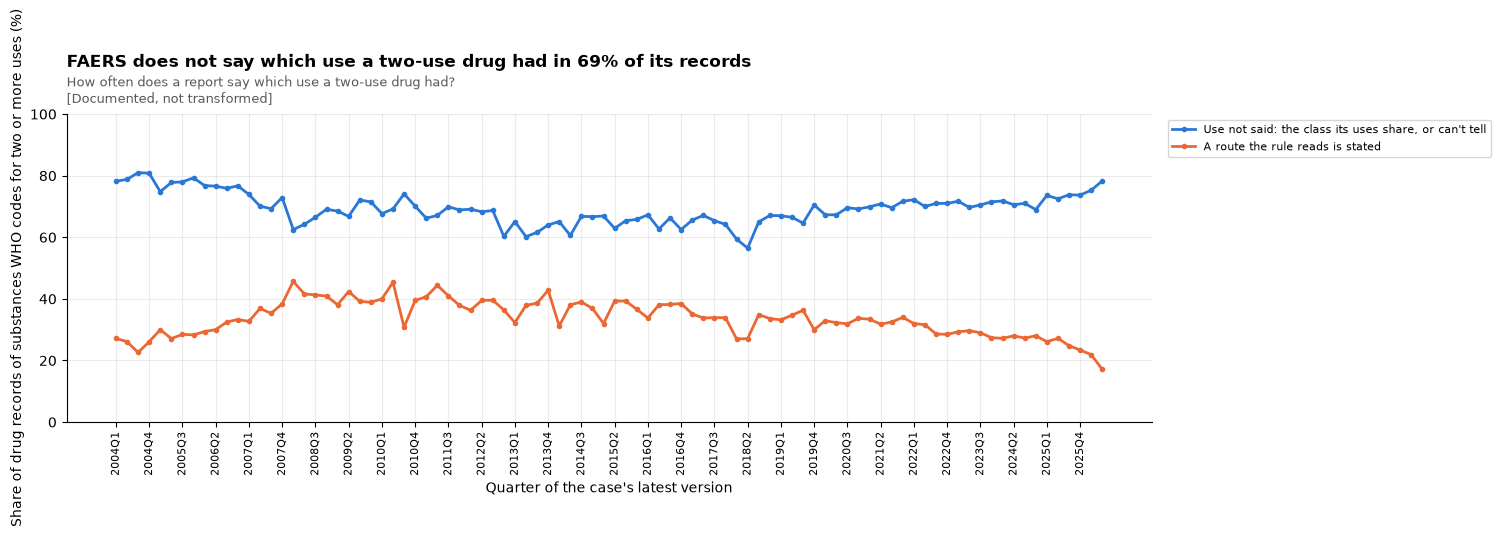

WHO gives a substance like methotrexate or prednisone one code per use, and a report says which only through its dose, its route or the indication it gives: of the 12,527,498 drug records of such substances, 69% say none of them, up from 62% in 2018 to 78% in 2026Q2 as fewer reports state a route. A filter that counts only records whose exact class is known would miss them, so Open Altio gives each the class its uses share, or says it cannot tell, and keeps every class it could be.
notebooks/out/cards/09_drug_classes.json


In [17]:
cards = compute_cards(con, ["aspirin_dose_tells_the_use", "two_use_drug_use_not_said"])
for card in cards:
    plot_card(card)
print(write_cards(cards, "09_drug_classes"))

## Decisions

The decisions this notebook's questions back, as recorded, with what this release carries of each. Counts are of the default case set.

1. **One WHO index for all quarters.** Each release uses the newest WHO index available at build time for every quarter, its year recorded; a new index is adopted just before the next build. Built: this release reads the 2026 index (`rules/atc-index.md`), and section 5 shows our copy of it matching DiAna's where both code a one-class drug.
2. **Drugs the table misses.** Add the missing spelling bridges, each checked on cases: glycopyrronium bromide first, multienzymes, insulin (human), and the salt bridges proposed from the data. For DiAna's group names, FDA's own words on the record (`drugname`, then `prod_ai`) first, matched to WHO's names; else WHO's class one level up, marked as a coarser class. Built (section 9): the approved spelling and salt bridges (part A), the bridges FDA's own words find (part C, with thyroid as WHO's thyroid gland preparations, H03AA05) and 134 group classes (part D, insulin A10A, iron B03A, vitamins, vaccines and the rest, bare calcium, potassium and magnesium as WHO's class for the element, and selenium as WHO's selenium class, A12CE), `rules/atc-spelling-bridges.md` and `rules/atc-group-classes.md`. They code 2.67 million records that had none; cases with a coded suspect drug go from 19,817,147 to 20,152,189.
3. **Combinations WHO codes in words our matching misses:** a hand-checked list for the largest, each row giving the ingredients, WHO's code, the reason and the cases it codes; a general "X, combinations" rule comes after launch. Built (part B of section 9): Mirena G02BA03, calcium with vitamin D A12AX, Suboxone N07BC51, NuvaRing G02BB01 and the other approved rows, 122,709 records coded and 318,306 re-coded. Darvocet (N02AC54), the bowel preparation (A06AD65) and peritoneal dialysis solutions (B05D) have no row yet and stay split (section 2).
4. **Combinations WHO has no code for stay "can't tell",** each ingredient's classes kept. Built (`rules/atc-class-choice.md`): a split combination never takes one ingredient's class or the class its ingredients share.
5. **Route groups are settled with the route step;** the classes step will read the shared route step. Now: a report saying eye takes the S01 code and ear the S02 code, S03 only when nothing else fits; a single-ingredient record never takes a code WHO reserves for mixes. The rule file says this is our table's reading, not a WHO error. Built: section 4 measures it.
6. **Dose rules where the dose tells the use, each agreeing with the reported indication at least 95% of the time, one unit and one bound.** Built: 32 rules (section 3), among them methotrexate at 25 mg or less weekly, the tablet doses of ibuprofen, diclofenac, indometacin and naproxen, everolimus, ofatumumab, esketamine, buprenorphine and levonorgestrel's emergency pill at 1.5 mg or less; finasteride at 5 mg or more kept at 88.7%, since every other bound is worse. Left out: aspirin at 500 mg or more (58.5%); levonorgestrel's contraceptive forms, which no dose tells apart (13.5 mg or more is mostly the implant, and the IUD Kyleena is reported at 17.5 µg a day, inside a pill's bound); methotrexate by dose alone without its weekly frequency; and rules that would only be a default. Free-text doses of legacy reports are not read at launch.
7. **"Can't tell" gets the broadest class all its possible codes share** (level 4, else 3, else 2, never level 1), marked with its level: certain, not a guess. Built, with the codes a record's one route group fits compared first (section 4). **The indication is a fourth way to choose, after dose and route,** by the agreed rules over the reviewed indication list. Built (section 8): 33 rows for 22 substances in `indication_rules`, chosen only among the codes dose and route leave open and read as whole terms; 1,151,136 records classed, 99.4% agreement with dose and route where both speak.
8. **The class filter counts suspect drugs (PS and SS) by default,** with tick boxes for the other roles, as for drug names (`rules/explorer-drug-counts.md`). On screen: one class per record (the most exact one known), the other possible classes only in the case window, and one "could be" tick on the class filter, as for routes.

**Left out, and why.**

- **The 34 bridge and group rows the review turned down**, each for the reason on its row of the review sheet: vitamin B3 (D11, most are Niaspan, a cholesterol drug), gold (A23, arthritis injections, not radioactive gold), drip feeds (B12, which would take the oral nutrition class), antilymphocyte globulin (A63, most do not say horse or rabbit), and A46, A49, A58, A73, A75, A76, A77, A81, A88, A92, A94, A97, A117, A121, A127, A138, A141, A143, A155, A163, B21, B45, B52, B55, D53, D85, D100 and D115. Calcium with magnesium (B9) and minerals (D36) stay turned down after a second look with the shares section 9 found: Rolaids are 55.6% of the records B9 would code or re-code (every record of its substance, since a bridge is read before FDA's own words), and drips with eye ointment 36% of the mineral records with no code that D36 would class. Selenium (D26) was approved on that second look and is built (decision 2): Selsun shampoo is 25 of the 5,167 records it codes.
- **Three approved rows, held:** Paragard's copper (C3), since a bridge from FDA's word `copper` would also turn copper supplements into the IUD (Paragard gets the IUD class through D13); heart medication (D44) and antimicrobials (D94), which would be level 1 classes, a whole body system, which no group class is.
- **Fluticasone's indication rows:** its inhaled and nasal uses each have two codes, one per ester, and a row takes one code.
- **Levonorgestrel's contraceptive dose rules** and **aspirin at 500 mg or more,** as decision 6 says.

## 8 · The reason it was taken picks the class

FAERS writes why each drug was taken (`indi_pt` in `indi_latest_T`, tied to its drug record by `indi_drug_seq`). The class step's fourth way to choose (`rules/atc-class-choice.md`, step 4) reads it: only when neither dose nor route chose, and only among the codes they leave open, so when a record's route is in a group, only the codes that group fits. A row of `indication_rules` names a substance, one of its codes and the indications that mean that use, each a whole MedDRA term; an indication matches a row when it is one of the row's terms, whatever its capitals ("Chest pain" is not the term `pain`); when every indication that matches points to one code, the record takes it. The rule holds 33 rows for 22 substances with two uses, written from these rules (a 23rd, fluticasone, is left out):

- **Methotrexate:** a cancer or chemotherapy gives the cancer class (L01BA01); any other reason the immune class (L04AX03).
- **Fentanyl:** anaesthesia gives the anaesthetic (N01AH01); any other reason the painkiller (N02AB03).
- **Aspirin:** any pain, fever or headache gives the painkiller (N02BA01); any other reason the blood thinner (B01AC06).
- **Eye:** an eye disease or eye operation gives the eye code of dexamethasone (S01BA01), prednisolone (S01BA04), bevacizumab (S01LA08), ciclosporin (S01XA18) and timolol (S01ED01); any other reason the code the rest of their reasons give (H02AB02, H02AB06, L01FG01, L04AD01; none for timolol). An eye cancer counts as a cancer.
- **Tacrolimus:** eczema (atopic dermatitis) gives the skin code (D11AH01); any other reason the transplant class (L04AD02).
- **Hair:** hair loss gives minoxidil and finasteride their hair codes (D11AX01, D11AX10); any other reason their other use (C02DC01, G04CB01).
- **Ibuprofen:** an open heart duct in a newborn (patent ductus arteriosus) gives the heart code (C01EB16); any other reason M01AE01.
- **Inhalers:** salbutamol for inhalation is R03AC02. Fluticasone for asthma or COPD would be an inhaled corticosteroid (R03BA05 or R03BA09), for a nose problem a nasal one (R01AD08 or R01AD12): two codes each, one per ester, and a row takes one code, so **fluticasone is left out**; its records keep the class their route gives, or the class their codes share.
- **One code:** prednisone, methylprednisolone, oxybate, celecoxib, folic acid (DiAna's `vitamin b9`), diphenhydramine, naproxen, diclofenac and cetirizine get the one code all their reasons give.

**Where the rows come from.** The rules were applied to a reviewed list of reasons, named by `OPEN_ALTIO_INDICATION_LIST` (a CSV with `substance_T`, `indication_pt`, `implied_codes` and `records_with_pt`; without it the first two cells are skipped and the rest measure the rows as built): one row per substance and reported reason, with the code a reviewer gave it. Its largest 491 rows hold 90% of its records (the listed rows), 6,284 smaller rows the rest; a reason that says nothing about the use (unknown indication, off-label use, prophylaxis alone, exposure) is not on it. Each reason the rules give one code becomes a term of the row for that substance and code, so "any other reason" means any other reason on the list.

The first cell applies the rules to the list and checks that the rows it gives are exactly the rule file's `indication_rules`, then counts them by substance and code (`list_records`: the list's records for those reasons).

In [18]:
import re

CANCER = (
    r"cancer|carcinoma|malignan|tumou?r\b|sarcoma|glioblastoma|glioma|metasta|mesothelioma|lymphoma|leuka?emia|myeloma"
    r"|blastoma|melanoma|hodgkin|plasmacytoma|macroglobulinaemia|myelodysplastic|chemotherapy"
)
WORDS = {
    "cancer or chemotherapy": CANCER,
    "anaesthesia": r"anaesth|anesth",
    "pain, fever or headache": r"pain|algia\b|ache\b|headache|migraine|pyrexia|fever|febrile|analges|dysmenorrhoea",
    "an eye disease or operation": (
        r"\beye|ocular|uveitis|iritis|iridocyclitis|keratitis|conjunctivitis|scleritis|endophthalmitis|cataract"
        r"|macul|retin|choroid|vitre|glaucoma|intraocular|blephar|meibomian|cornea|lacrima|photophobia"
    ),
    "eczema": r"eczema|dermatitis",
    "hair loss": r"alopecia|hair|baldness|hypotrichosis|madarosis",
    "an open heart duct": r"ductus arteriosus",
    "asthma or COPD": r"asthma|chronic obstructive|emphysema",
    "the nose": r"nasal|\bnose|rhinit|rhinorrh|sinus|sneez|nasopharyngitis",
    "inhalation": r"inhalation|nebuli",
}
NO_REASON = (
    r"unknown indication|ill-defined|off label|^prophylaxis$|exposure|condition aggravated|adverse (drug )?(reaction|event)"
    r"|drug abuse|overdose|suicid|intentional|accidental|medication error|product use|unevaluable|^therapy$|^drug therapy$"
)
RULES = pd.DataFrame(
    [  # rule, substance, the reason's words ("" for any other reason), the codes it allows
        ("methotrexate", "methotrexate", "cancer or chemotherapy", "L01BA01"),
        ("methotrexate", "methotrexate", "", "L04AX03"),
        ("fentanyl", "fentanyl", "anaesthesia", "N01AH01"),
        ("fentanyl", "fentanyl", "", "N02AB03"),
        ("aspirin", "acetylsalicylic acid", "pain, fever or headache", "N02BA01"),
        ("aspirin", "acetylsalicylic acid", "", "B01AC06"),
        *[
            ("eye", s, "an eye disease or operation", c)
            for s, c in [
                ("dexamethasone", "S01BA01"),
                ("prednisolone", "S01BA04"),
                ("bevacizumab", "S01LA08"),
                ("ciclosporin", "S01XA18"),
                ("timolol", "S01ED01"),
            ]
        ],
        *[
            ("eye", s, "", c)
            for s, c in [
                ("dexamethasone", "H02AB02"),
                ("prednisolone", "H02AB06"),
                ("bevacizumab", "L01FG01"),
                ("ciclosporin", "L04AD01"),
            ]
        ],
        ("tacrolimus", "tacrolimus", "eczema", "D11AH01"),
        ("tacrolimus", "tacrolimus", "", "L04AD02"),
        ("hair", "minoxidil", "hair loss", "D11AX01"),
        ("hair", "minoxidil", "", "C02DC01"),
        ("hair", "finasteride", "hair loss", "D11AX10"),
        ("hair", "finasteride", "", "G04CB01"),
        ("ibuprofen", "ibuprofen", "an open heart duct", "C01EB16"),
        ("ibuprofen", "ibuprofen", "", "M01AE01"),
        ("inhalers", "fluticasone", "asthma or COPD", "R03BA05 R03BA09"),
        ("inhalers", "fluticasone", "the nose", "R01AD08 R01AD12"),
        ("inhalers", "salbutamol", "inhalation", "R03AC02"),
        *[
            ("one code", s, "", c)
            for s, c in [
                ("prednisone", "H02AB07"),
                ("methylprednisolone", "H02AB04"),
                ("oxybate sodium", "N07XX04"),
                ("celecoxib", "M01AH01"),
                ("vitamin b9", "B03BB01"),
                ("diphenhydramine", "R06AA02"),
                ("naproxen", "M01AE02"),
                ("diclofenac", "M01AB05"),
                ("cetirizine", "R06AE07"),
            ]
        ],
    ],
    columns=["rule", "substance", "words", "codes"],
)
ORDER = list(RULES.rule.unique())


def reason(substance, pt):
    """The row of RULES a reported reason meets for a substance, or None when it decides nothing."""
    if re.search(NO_REASON, pt):
        return None
    mine = RULES[RULES.substance == substance]
    for r in mine.itertuples():  # an eye cancer is a cancer
        if (
            r.words
            and re.search(WORDS[r.words], pt)
            and not (r.words == "an eye disease or operation" and re.search(CANCER, pt))
        ):
            return r
    return next((r for r in mine.itertuples() if not r.words), None)


# The reviewed list of reasons: one row per substance and reported reason (lower case), with the
# code a reviewer gave it; its largest rows, which hold 90% of its records, are the listed rows.
LIST = os.environ.get("OPEN_ALTIO_INDICATION_LIST")
LIST = Path(LIST).expanduser() if LIST else None
if LIST is None:
    print("OPEN_ALTIO_INDICATION_LIST is not set: section 8 is skipped")
else:
    lst = pd.read_csv(LIST).sort_values(
        ["records_with_pt", "substance_T", "indication_pt"], ascending=[False, True, True]
    )
    held = lst.records_with_pt.cumsum().shift(fill_value=0)
    lst["on_list_T"] = np.where(held < 0.9 * lst.records_with_pt.sum(), "listed", "smaller")
    met = [reason(s, p) for s, p in zip(lst.substance_T, lst.indication_pt, strict=True)]
    lst["rule_T"] = [m.rule if m else None for m in met]
    lst["codes_T"] = [m.codes if m else None for m in met]
    # The indication step takes one code per row of indication_rules: a reason the rules give two
    # codes (fluticasone's two inhaled esters) cannot be written as a row, so it is left out.
    one = lst[lst.codes_T.notna() & ~lst.codes_T.fillna("").str.contains(" ")]
    INDICATION_RULES = [
        {"substance": s, "code": c, "indications": sorted(g.indication_pt)}
        for (s, c), g in one.groupby(["substance_T", "codes_T"])
    ]
    codes_of = (
        TABLE[TABLE.ingredient.isin(one.substance_T.unique())]
        .groupby("ingredient")
        .atc_code.agg(set)
    )
    assert all(r["code"] in codes_of[r["substance"]] for r in INDICATION_RULES), (
        "a code the table does not give"
    )

    # the rows the rules give, against the rows the rule file holds
    BUILT = CHOICE["indication_rules"]
    print(
        f"the rules give {len(INDICATION_RULES)} rows of indication_rules from {len(one):,} reasons; "
        f"rules/atc-class-choice.md holds {len(BUILT)}, "
        + ("the same rows" if INDICATION_RULES == BUILT else "OTHER rows")
    )
    assert INDICATION_RULES == BUILT, (
        "the rule file's indication_rules are not the rows the rules give"
    )
    display(
        one.groupby(["rule_T", "substance_T", "codes_T"])
        .agg(reasons=("indication_pt", "size"), list_records=("records_with_pt", "sum"))
        .rename_axis(["rule", "substance", "code"])
    )

the rules give 33 rows of indication_rules from 6,655 reasons; rules/atc-class-choice.md holds 33, the same rows


reasons  list_records
rule         substance            code                          
aspirin      acetylsalicylic acid B01AC06      236         96556
                                  N02BA01       30          8536
eye          bevacizumab          L01FG01      760        104562
                                  S01LA08      123          9240
             ciclosporin          L04AD01      225         67108
                                  S01XA18       70         15944
             dexamethasone        H02AB02      899        157939
                                  S01BA01       49          2859
             prednisolone         H02AB06      803        101920
                                  S01BA04       46          2553
             timolol              S01ED01       19          5026
fentanyl     fentanyl             N01AH01       16          8291
                                  N02AB03      177        138309
hair         finasteride          D11AX10       12          8494
                                  G04CB01       48          8618
             minoxidil            C02DC01       15           939
                                  D11AX01       18         30796
ibuprofen    ibuprofen            C01EB16        2          1117
                                  M01AE01       52         28631
inhalers     salbutamol           R03AC02        1           781
methotrexate methotrexate         L01BA01      530         50985
                                  L04AX03      212        219695
one code     celecoxib            M01AH01      181         52545
             cetirizine           R06AE07       62         16007
             diclofenac           M01AB05       52         15380
             diphenhydramine      R06AA02       59         36646
             methylprednisolone   H02AB04      725         82115
             naproxen             M01AE02       35         20004
             oxybate sodium       N07XX04       24        114651
             prednisone           H02AB07      839        184532
             vitamin b9           B03BB01      103         46474
tacrolimus   tacrolimus           D11AH01       10          2185
                                  L04AD02      222        131790

Each row of the reviewed list, classed by the rules and compared with the code the list gives. The first table counts rows, and this release's records giving each reason, by outcome, for the listed and the smaller rows; the next two list the rows the rules class otherwise. "One of the list's codes" is a row where the list left two codes open and the rules pick one: prednisolone for uveitis and after a cataract operation, which the eye rule gives S01BA04 (the list also allowed S03BA02, the class for products made for both eye and ear). Among the smaller rows the rules give another code where they name one use and the list another: tacrolimus for vitiligo and lichen (the list: the skin code), dexamethasone for mouth ulcers (A01AC02), diclofenac for actinic keratosis (D11AX18) and in the eye (S01BC03), diphenhydramine for bites (D04AA32), celecoxib for polyposis (L01XX33), fentanyl for intubation (N01AH01) and steroids for the ear (S02); and a corneal transplant, an eye operation, takes the eye code where the list gave the systemic one. The rules leave open fluticasone for bronchitis, wheezing and skin, salbutamol to stop early labour (R03CC02) and timolol tablets (C07AA06).

In [19]:
# every reason the release gives for a record of the rules' substances matched on its substance,
# as the step reads it: the whole term in lower case
con.register(
    "rule_subs_df",
    pd.DataFrame({"substance_T": sorted({r["substance"] for r in CHOICE["indication_rules"]})}),
)
con.execute("""CREATE TABLE ind_rec_T AS
    SELECT DISTINCT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, r.substance_T, lower(trim(i.indi_pt)) AS pt_T
    FROM rec_T r SEMI JOIN rule_subs_df USING (substance_T)
    JOIN indi_latest_T i ON i.era_T = r.era_T AND i.primaryid = r.primaryid AND i.quarter_T = r.quarter_T
                        AND i.indi_drug_seq = r.drug_seq
    WHERE r.atc_matched_on_T = 'substance' AND i.indi_pt IS NOT NULL""")
if LIST:
    seen = q("SELECT substance_T, pt_T, count(*) AS records FROM ind_rec_T GROUP BY ALL")

    def outcome(rule, listed):
        if not isinstance(rule, str):
            return "the rules leave it open"
        a, b = set(rule.split()), set(listed.split())
        return "same" if a == b else "one of the list's codes" if a < b else "another code"

    rows = lst.rename(columns={"indication_pt": "pt_T"}).merge(seen, how="left")
    rows["records"] = rows.records.fillna(0).astype(int)  # this release's records giving the reason
    rows["outcome"] = [outcome(r, g) for r, g in zip(rows.codes_T, rows.implied_codes, strict=True)]
    summary = rows.pivot_table(
        index="on_list_T",
        columns="outcome",
        values="records",
        aggfunc=["count", "sum"],
        fill_value=0,
    )
    summary.columns = [f"{'rows' if a == 'count' else 'records'}: {o}" for a, o in summary.columns]

    def show(d):
        return (
            d[["substance_T", "pt_T", "implied_codes", "codes_T", "records"]]
            .rename(
                columns={"pt_T": "reason", "implied_codes": "list gives", "codes_T": "rules give"}
            )
            .sort_values("records", ascending=False)
        )

    display(summary)
    print("Listed rows the rules class otherwise:")
    display(show(rows[(rows.on_list_T == "listed") & (rows.outcome != "same")]))
    print("Smaller rows the rules class otherwise, largest first:")
    display(
        show(
            rows[
                (rows.on_list_T == "smaller")
                & ~rows.outcome.isin(["same", "one of the list's codes"])
            ]
        ).head(25)
    )

,rows: another code,rows: one of the list's codes,rows: same,rows: the rules leave it open,records: another code,records: one of the list's codes,records: same,records: the rules leave it open
on_list_T,,,,,,,,
listed,0,2,489,0,0,1043,1564967,0
smaller,74,80,6087,43,2098,2524,167277,187


Listed rows the rules class otherwise:


,substance_T,reason,list gives,rules give,records
357,prednisolone,uveitis,S01BA04 S03BA02,S01BA04,633
475,prednisolone,cataract operation,S01BA04 S03BA02,S01BA04,410


Smaller rows the rules class otherwise, largest first:


,substance_T,reason,list gives,rules give,records
590,dexamethasone,stomatitis,A01AC02,H02AB02,283
614,tacrolimus,vitiligo,D11AH01,L04AD02,268
708,celecoxib,adenomatous polyposis coli,L01XX33,M01AH01,213
834,diclofenac,actinic keratosis,D11AX18,M01AB05,147
887,fentanyl,endotracheal intubation,N01AH01,N02AB03,137
970,tacrolimus,lichen planus,D11AH01,L04AD02,113
999,prednisolone,corneal transplant,H02AB06,S01BA04,105
1183,tacrolimus,lichen sclerosus,D11AH01,L04AD02,70
1222,diphenhydramine,arthropod bite,D04AA32,R06AA02,66
1236,diphenhydramine,dermatitis contact,D04AA32,R06AA02,65


The step itself is built: the class step ran on every record of the release in the first code cell, with the rows in the rule file, within the notebook's 6 GB of memory and 20 GB of scratch disk. It looks each reason up among the rows' terms by equality, for only the records dose and route leave open, where before it joined every reason with every term of its substance and outgrew both. The next cell reads the reasons apart from the step, as the rule says (a whole term; among the codes dose and route leave open, those the record's route group fits), and its first line compares that reading with the step, record by record.

In [20]:
KEY = "era_T, primaryid, quarter_T, drug_seq"  # a drug record
# the release's substances and routes, written once for the run of section 9 to read
SUBSTANCE_FILE = WORK / "drug_substance.parquet"
con.execute(f"COPY {layer.SUBSTANCES} TO {quoted(SUBSTANCE_FILE.as_posix())} (FORMAT parquet)")
ROUTE_FILE = WORK / "drug_route.parquet"
con.execute(f"COPY {route.TABLE} TO {quoted(ROUTE_FILE.as_posix())} (FORMAT parquet)")


def build_run(name, table=None, groups=None, only=None):
    """Run the pipeline's class step on the release in a database of its own, attached here as
    `name` (name.atc_drug_T and the rest), on our table or `table` and `groups`, for every record
    or `only` those of these substances; the classes measured above stay as they are."""
    db = WORK / f"classes_{name}.duckdb"
    con.execute(f"DETACH DATABASE IF EXISTS {name}")
    db.unlink(missing_ok=True)
    run = duckdb.connect(str(db))
    # a scratch folder of its own: two databases in one folder write spill files of the same names
    run.execute(
        "SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; "
        f"SET preserve_insertion_order = false; SET temp_directory = '{WORK / f'tmp_{name}'}'"
    )
    release = {
        t: e for t, e in tables.items() if t not in (*layer.TABLES, layer.SUBSTANCES, route.TABLE)
    }
    register_release(run, SOURCE, tables=release, temporary=True)
    where = f"WHERE substance_T IN ({', '.join(quoted(s) for s in only)})" if only else ""
    run.execute(
        f"CREATE TABLE {layer.SUBSTANCES} AS SELECT * FROM read_parquet({quoted(SUBSTANCE_FILE.as_posix())}) {where}"
    )
    run.execute(
        f"CREATE TABLE {route.TABLE} AS SELECT * FROM read_parquet({quoted(ROUTE_FILE.as_posix())})"
    )
    entry = layer.build(run, table=table, groups=groups)
    run.close()
    con.execute(f"ATTACH {quoted(db.as_posix())} AS {name} (READ_ONLY)")
    return entry


# the rows as (substance, term, code), each route code's group, and the codes each group fits
# (step 3 of the rule)
INDICATION_RULES_BUILT = CHOICE["indication_rules"]
con.register(
    "ind_terms_df",
    pd.DataFrame(
        [(r["substance"], t, r["code"]) for r in INDICATION_RULES_BUILT for t in r["indications"]],
        columns=["substance_T", "pt_T", "code_T"],
    ),
)
con.register("ind_groups_df", ROUTE_GROUPS.rename(columns={"route_T": "route", "group_T": "grp"}))


def fits(grp, code):  # step 3 of the rule: the codes a route group fits
    spec = CHOICE["route_groups"][grp]
    if "codes" in spec:
        return any(code.startswith(p) for p in spec["codes"])
    return not any(code.startswith(p) for p in CHOICE["local_codes"] + spec.get("not_codes", []))


rule_codes = sorted(
    set(TABLE[TABLE.ingredient.isin([r["substance"] for r in INDICATION_RULES_BUILT])].atc_code)
)
con.register(
    "ind_fits_df",
    pd.DataFrame(
        [(g, c, fits(g, c)) for g in CHOICE["route_groups"] for c in rule_codes],
        columns=["grp", "code", "fits_T"],
    ),
)
print(
    f"{len(INDICATION_RULES_BUILT)} rows of indication_rules, "
    f"{sum(len(r['indications']) for r in INDICATION_RULES_BUILT):,} terms, for "
    f"{len({r['substance'] for r in INDICATION_RULES_BUILT})} substances"
)

33 rows of indication_rules, 6,655 terms, for 22 substances


One row of the table, and one bar of each chart, per rule. `open_records` are its substances' records that dose and route leave open (classed by indication, a shared class or "can't tell"); `classed` those the step classes by indication, and `classed_cases` their cases. `decided_with_reason` are the records dose or route decide whose reasons match a row; `agree` those whose reasons point to the code dose or route chose, `reasons_two_ways` those whose reasons point to two codes. Methotrexate is checked by its weekly-dose rule. The first line compares the step with this reading of the reasons, record by record.

the step and this reading of the reasons agree on 5,020,159 of 5,020,159 records dose and route leave open


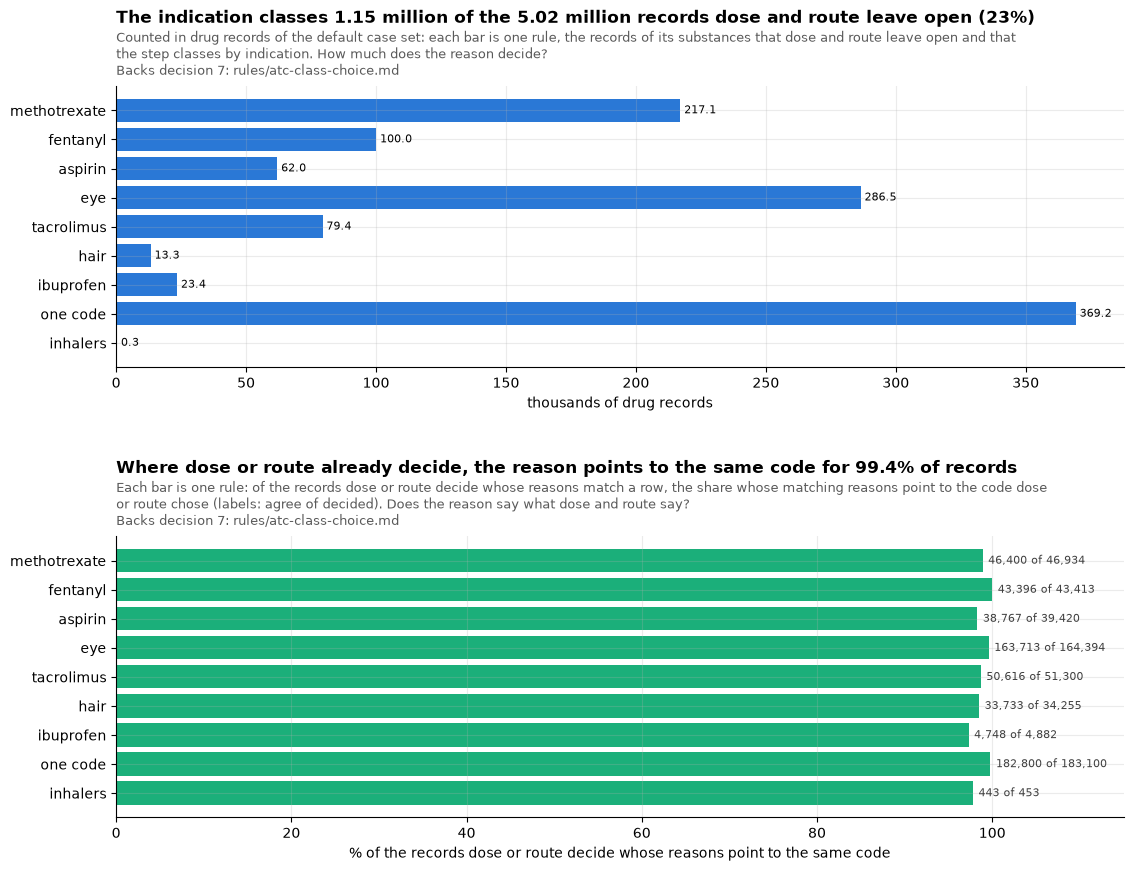

,rule,open_records,classed,classed_cases,decided_with_reason,agree,reasons_two_ways,% agree
0,methotrexate,593504,217061,193120,46934,46400,5,98.9
1,fentanyl,216845,100038,46668,43413,43396,0,100.0
2,aspirin,637787,61961,58032,39420,38767,1,98.3
3,eye,807891,286453,246602,164394,163713,4,99.6
4,tacrolimus,129925,79402,69707,51300,50616,1,98.7
5,hair,66677,13261,12667,34255,33733,1,98.5
6,ibuprofen,264655,23409,21840,4882,4748,1,97.3
7,one code,1895301,369228,292756,183100,182800,0,99.8
8,inhalers,407574,324,314,453,443,0,97.8


In [21]:
# per record: the codes its reasons point to, a reason matching a row's term as a whole, among the
# record's own codes, and among them those its route group fits
con.execute(f"""CREATE TABLE ind_out_T AS
    WITH grp AS (SELECT d.era_T, d.primaryid, d.quarter_T, d.drug_seq, x.grp AS grp_T
                 FROM drug_route_T d SEMI JOIN ind_rec_T USING ({KEY})
                 JOIN ind_groups_df x ON x.route = d.route_T),
    said AS (SELECT DISTINCT i.era_T, i.primaryid, i.quarter_T, i.drug_seq, t.code_T AS atc_code_T
             FROM ind_rec_T i JOIN ind_terms_df t USING (substance_T, pt_T)
             SEMI JOIN atc_drug_codes_T k ON k.era_T = i.era_T AND k.primaryid = i.primaryid
               AND k.quarter_T = i.quarter_T AND k.drug_seq = i.drug_seq AND k.atc_code_T = t.code_T),
    open AS (SELECT s.* FROM said s LEFT JOIN grp g USING ({KEY})
             LEFT JOIN ind_fits_df f ON f.grp = g.grp_T AND f.code = s.atc_code_T
             WHERE g.grp_T IS NULL OR f.fits_T),
    says AS (SELECT {KEY}, string_agg(atc_code_T, ' ' ORDER BY atc_code_T) AS reason_codes_T FROM said GROUP BY ALL),
    says_open AS (SELECT {KEY}, string_agg(atc_code_T, ' ' ORDER BY atc_code_T) AS open_codes_T FROM open GROUP BY ALL)
    SELECT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, r.substance_T, r.case_key_T,
           r.atc_code_T, r.atc_chosen_by_T, s.reason_codes_T, o.open_codes_T
    FROM rec_T r SEMI JOIN rule_subs_df USING (substance_T)
    LEFT JOIN says s USING ({KEY}) LEFT JOIN says_open o USING ({KEY})
    WHERE r.atc_matched_on_T = 'substance'""")
con.register(
    "rules_df",
    RULES.drop_duplicates("substance")[["substance", "rule"]].rename(
        columns={"substance": "substance_T", "rule": "rule_T"}
    ),
)
# the step against this reading: a record the dose and route leave open takes the one code its
# reasons point to among the open codes, and only then
check = q("""SELECT count(*) AS records,
        count(*) FILTER (WHERE (atc_chosen_by_T = 'indication')
                               = (open_codes_T IS NOT NULL AND NOT contains(open_codes_T, ' '))
                           AND (atc_chosen_by_T <> 'indication' OR atc_code_T = open_codes_T)) AS read_alike
    FROM ind_out_T WHERE atc_chosen_by_T IN ('indication', 'shared_class', 'cannot_tell')""").iloc[
    0
]
print(
    "the step and this reading of the reasons agree on",
    f"{check.read_alike:,} of {check.records:,}",
    "records dose and route leave open",
)
per = (
    q("""SELECT o.rule_T AS rule,
        count(*) FILTER (WHERE atc_chosen_by_T IN ('indication', 'cannot_tell', 'shared_class')) AS open_records,
        count(*) FILTER (WHERE atc_chosen_by_T = 'indication') AS classed,
        count(DISTINCT case_key_T) FILTER (WHERE atc_chosen_by_T = 'indication') AS classed_cases,
        count(*) FILTER (WHERE atc_chosen_by_T IN ('dose', 'route') AND reason_codes_T IS NOT NULL) AS decided_with_reason,
        count(*) FILTER (WHERE atc_chosen_by_T IN ('dose', 'route') AND reason_codes_T = atc_code_T) AS agree,
        count(*) FILTER (WHERE atc_chosen_by_T IN ('dose', 'route') AND contains(reason_codes_T, ' ')) AS reasons_two_ways
    FROM ind_out_T JOIN rules_df o USING (substance_T) GROUP BY 1""")
    .set_index("rule")
    .reindex([r for r in ORDER if r != "inhalers"] + ["inhalers"])
    .dropna(how="all")
    .astype(int)
    .reset_index()
)
per["% agree"] = (100 * per.agree / per.decided_with_reason).round(1)
total = per.drop(columns=["rule", "% agree"]).sum()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 9.5), gridspec_kw={"hspace": 0.6})
y = np.arange(len(per))
b = a1.barh(y, per.classed / 1e3, color=SERIES[0])
label_bars(a1, b, "{:,.1f}", horizontal=True)
a1.set_yticks(y)
a1.set_yticklabels(per.rule)
a1.invert_yaxis()
a1.set_xlabel("thousands of drug records")
title(
    a1,
    f"The indication classes {total.classed / 1e6:.2f} million of the {total.open_records / 1e6:.2f} million records "
    f"dose and route leave open ({100 * total.classed / total.open_records:.0f}%)",
    "Counted in drug records of the default case set: each bar is one rule, the records of its substances that dose "
    "and route leave open and that the step classes by indication.",
    "How much does the reason decide?",
    backs(7, "atc-class-choice"),
)
b = a2.barh(y, per["% agree"].fillna(0), color=SERIES[2])
for i, r in per.iterrows():
    a2.annotate(
        f"{r.agree:,} of {r.decided_with_reason:,}",
        (r["% agree"] if r.decided_with_reason else 0, i),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
        color="0.25",
    )
a2.set_yticks(y)
a2.set_yticklabels(per.rule)
a2.invert_yaxis()
a2.set_xlim(0, 115)
a2.set_xticks(range(0, 101, 20))
a2.set_xlabel("% of the records dose or route decide whose reasons point to the same code")
title(
    a2,
    f"Where dose or route already decide, the reason points to the same code for {100 * total.agree / total.decided_with_reason:.1f}% of records",
    "Each bar is one rule: of the records dose or route decide whose reasons match a row, the share whose matching "
    "reasons point to the code dose or route chose (labels: agree of decided).",
    "Does the reason say what dose and route say?",
    backs(7, "atc-class-choice"),
)
plt.show()
display(per)

Examples, up to three per rule: the drug name, route and a matching reason most often seen among the records the rows class, today's choice and the class the rows give.

In [22]:
NAMES_OF = "(SELECT atc_code_T, any_value(atc_name_T) AS atc_name_T FROM atc_index_T GROUP BY 1)"
sample = q(f"""WITH c AS (SELECT o.*, x.rule_T FROM ind_out_T o JOIN rules_df x USING (substance_T)
                     WHERE o.atc_chosen_by_T = 'indication'),
    d AS (SELECT {KEY}, any_value(upper(trim(drugname))) AS drug_name,
                 string_agg(DISTINCT coalesce(upper(trim(route)), '-'), ', ') AS route
          FROM drug_latest_T SEMI JOIN c USING ({KEY}) GROUP BY ALL),
    p AS (SELECT i.era_T, i.primaryid, i.quarter_T, i.drug_seq, min(i.pt_T) AS reason
          FROM ind_rec_T i JOIN ind_terms_df t USING (substance_T, pt_T) JOIN c USING ({KEY})
          WHERE t.code_T = c.atc_code_T GROUP BY ALL),
    g AS (SELECT c.rule_T AS rule, c.substance_T AS substance, d.drug_name, d.route, p.reason,
                 c.atc_code_T AS code, count(*) AS records
          FROM c JOIN d USING ({KEY}) JOIN p USING ({KEY}) GROUP BY ALL)
    SELECT g.* EXCLUDE (code, records), g.code || ' ' || coalesce(n.atc_name_T, '') AS given, g.records
    FROM g LEFT JOIN {NAMES_OF} n ON n.atc_code_T = g.code
    QUALIFY row_number() OVER (PARTITION BY g.rule, g.code ORDER BY g.records DESC) = 1""")
display(
    sample.assign(o=sample.rule.map(ORDER.index))
    .sort_values(["o", "records"], ascending=[True, False])
    .drop(columns="o")
    .groupby("rule", sort=False)
    .head(3)
    .set_index(["rule", "substance"])
)

drug_name                                  route                                         reason                         given  records
rule         substance                                                                                                                                                                  
methotrexate methotrexate                      METHOTREXATE                                      -                           rheumatoid arthritis          L04AX03 methotrexate    17688
             methotrexate                     METHOTREXATE.                            INTRATHECAL                    acute lymphocytic leukaemia          L01BA01 methotrexate     3041
fentanyl     fentanyl                             DURAGESIC                                UNKNOWN                                           pain              N02AB03 fentanyl    21412
             fentanyl                              FENTANYL                                UNKNOWN                       induction of anaesthesia              N01AH01 fentanyl      485
aspirin      acetylsalicylic acid                   ASPIRIN                                      -                          anticoagulant therapy  B01AC06 acetylsalicylic acid     1162
             acetylsalicylic acid                  ASPIRIN.                                      -                                           pain  N02BA01 acetylsalicylic acid      724
eye          dexamethasone                   DEXAMETHASONE.                                UNKNOWN                            plasma cell myeloma         H02AB02 dexamethasone    18108
             prednisolone                      PREDNISOLONE                                   ORAL                           rheumatoid arthritis          H02AB06 prednisolone     4222
             ciclosporin                       CYCLOSPORINE                                UNKNOWN  prophylaxis against graft versus host disease           L04AD01 ciclosporin     3595
tacrolimus   tacrolimus                          TACROLIMUS                                UNKNOWN                 immunosuppressant drug therapy            L04AD02 tacrolimus     9273
             tacrolimus                          TACROLIMUS                                      -                              dermatitis atopic            D11AH01 tacrolimus      130
hair         finasteride                           PROPECIA                                   ORAL                                       alopecia           D11AX10 finasteride      788
             minoxidil             WOMENS ROGAINE UNSCENTED                                UNKNOWN                                       alopecia             D11AX01 minoxidil      730
             finasteride                            PROSCAR                                   ORAL                   benign prostatic hyperplasia           G04CB01 finasteride      365
ibuprofen    ibuprofen                                ADVIL                                      -                                       headache             M01AE01 ibuprofen     1672
             ibuprofen                            NEOPROFEN  INTRAVENOUS (NOT OTHERWISE SPECIFIED)                       patent ductus arteriosus             C01EB16 ibuprofen      150
inhalers     salbutamol                          PROAIR HFA                                      -                             inhalation therapy            R03AC02 salbutamol       61
one code     prednisone                          PREDNISONE                                   ORAL                           rheumatoid arthritis            H02AB07 prednisone     8445
             celecoxib                             CELEBREX                                      -                                      arthritis             M01AH01 celecoxib     5808
             vitamin b9                          FOLIC ACID                                UNKNOWN                           rheumatoid arthritis            B03BB01 

Four checks on the step. The first line counts the diclofenac records the step gives the tablet's code (M01AB05) whose drug name says gel, patch or cream; the second the records it classes by indication against the route group of their route, which it no longer does (diclofenac gel is not the tablet, and prednisolone taken by mouth for an eye disease is not the eye drop). The first table counts the records whose reasons hold a row's term inside a longer term, which reading words inside a term would have classed and the step now leaves alone ("chest pain" is not "pain"). The second lists, largest first, the records dose or route decide whose reasons point elsewhere: aspirin at 162 mg or less taken for pain, finasteride 5 mg for hair loss (a split tablet), and methotrexate at a weekly low dose for acute lymphocytic leukaemia, whose maintenance is given that way too.

In [23]:
worst = q(f"""WITH c AS (SELECT * FROM ind_out_T
                     WHERE atc_chosen_by_T IN ('dose', 'route') AND reason_codes_T IS NOT NULL
                       AND NOT contains(reason_codes_T, ' ') AND reason_codes_T <> atc_code_T),
    p AS (SELECT i.era_T, i.primaryid, i.quarter_T, i.drug_seq, string_agg(DISTINCT i.pt_T, '; ') AS reasons
          FROM ind_rec_T i JOIN ind_terms_df t USING (substance_T, pt_T) SEMI JOIN c USING ({KEY}) GROUP BY ALL)
    SELECT c.substance_T AS substance, c.atc_chosen_by_T AS decided_by, c.atc_code_T AS decided, p.reasons,
           c.reason_codes_T AS reasons_point_to, count(*) AS records
    FROM c JOIN p USING ({KEY}) GROUP BY ALL ORDER BY records DESC LIMIT 12""")
# a record the step classes by indication although its route is in a group that does not fit the code
against = q(f"""WITH c AS (SELECT * FROM ind_out_T WHERE atc_chosen_by_T = 'indication'),
    g AS (SELECT {KEY}, x.grp FROM drug_route_T d SEMI JOIN c USING ({KEY})
          JOIN ind_groups_df x ON x.route = d.route_T)
    SELECT c.substance_T AS substance, g.grp AS route_group, c.atc_code_T AS indication_gives, count(*) AS records
    FROM c JOIN g USING ({KEY}) JOIN ind_fits_df f ON f.grp = g.grp AND f.code = c.atc_code_T
    WHERE NOT f.fits_T GROUP BY ALL ORDER BY records DESC""")
gel = con.execute(f"""SELECT count(*), count(*) FILTER (WHERE regexp_matches(n, 'GEL|PATCH|CREAM|TOPICAL|SOLARAZE|FLECTOR|PENNSAID|EMULGEL|ARTHRITIS PAIN')
                                                  AND NOT regexp_matches(n, 'LIQUI'))
    FROM (SELECT any_value(upper(d.drugname)) AS n FROM ind_out_T o JOIN drug_latest_T d USING ({KEY})
          WHERE o.substance_T = 'diclofenac' AND o.atc_chosen_by_T = 'indication' GROUP BY o.era_T, o.primaryid, o.quarter_T, o.drug_seq)""").fetchone()
print(
    f"diclofenac records the step classes as the tablet (M01AB05): {gel[0]:,}; of them named a gel, patch or cream: {gel[1]:,}"
)
print(
    f"records the step classes by indication against the route group of their route: {against.records.sum():,}"
)


def words(text):  # a term's words: lower case, other characters as spaces
    return " ".join(re.sub("[^a-z0-9]+", " ", text.lower()).split())


# reasons that hold a row's term only inside a longer term, which the step does not read as that term
terms = {}
for r in INDICATION_RULES_BUILT:
    terms.setdefault(r["substance"], set()).update((words(t), r["code"]) for t in r["indications"])
exact = {(r["substance"], t) for r in INDICATION_RULES_BUILT for t in r["indications"]}
pairs = q("SELECT substance_T, pt_T, count(*) AS records FROM ind_rec_T GROUP BY ALL")
inside = [
    (s, p, n, ", ".join(sorted({c for w, c in terms.get(s, ()) if f" {w} " in f" {words(p)} "})))
    for s, p, n in zip(pairs.substance_T, pairs.pt_T, pairs.records, strict=True)
    if (s, p) not in exact and any(f" {w} " in f" {words(p)} " for w, _ in terms.get(s, ()))
]
inside = pd.DataFrame(
    inside, columns=["substance", "reason", "records", "a term inside it points to"]
)
print(
    f"records whose reasons hold a row's term only inside a longer term, read as no term: {inside.records.sum():,}"
)
display(inside.sort_values("records", ascending=False).head(10).set_index(["substance", "reason"]))
display(against.head(10))
display(worst)

diclofenac records the step classes as the tablet (M01AB05): 9,982; of them named a gel, patch or cream: 520
records the step classes by indication against the route group of their route: 0


records whose reasons hold a row's term only inside a longer term, read as no term: 6,352


records a term inside it points to
substance            reason                                                                     
vitamin b9           foetal exposure during pregnancy             704                    B03BB01
cetirizine           eye pruritus                                 570                    R06AE07
fentanyl             procedural pain                              555                    N02AB03
acetylsalicylic acid chest pain                                   445                    N02BA01
prednisone           graft versus host disease in skin            250                    H02AB07
tacrolimus           graft versus host disease in skin            219                    L04AD02
prednisolone         graft versus host disease in skin            188                    H02AB06
                     juvenile arthritis                           178                    H02AB06
methylprednisolone   graft versus host disease in skin            176                    H02AB04
                     acute graft versus host disease in skin      151                    H02AB04

,substance,route_group,indication_gives,records


,substance,decided_by,decided,reasons,reasons_point_to,records
0,acetylsalicylic acid,dose,B01AC06,pain,N02BA01,306
1,finasteride,dose,G04CB01,alopecia,D11AX10,300
2,tacrolimus,route,D11AH01,vitiligo,L04AD02,173
3,methotrexate,dose,L04AX03,acute lymphocytic leukaemia,L01BA01,157
4,finasteride,dose,G04CB01,androgenetic alopecia,D11AX10,128
5,acetylsalicylic acid,dose,B01AC06,headache,N02BA01,87
6,diclofenac,route,S01BC03,rheumatoid arthritis,M01AB05,77
7,acetylsalicylic acid,dose,B01AC06,migraine,N02BA01,75
8,tacrolimus,route,D11AH01,immunosuppressant drug therapy,L04AD02,65
9,ibuprofen,route,M02AA13,pyrexia,M01AE01,65


**What section 8 shows**, one item per chart and table:

- **Records the reason classes.** *Shows:* in drug records of the default case set, the indication classes 1,151,136 of the 5,020,295 records dose and route leave open (23%): 369,226 of the one-code drugs, 286,452 of the eye rule, 217,061 of methotrexate, 100,038 of fentanyl, 79,402 of tacrolimus, 61,963 of aspirin; inhalers only 324, all salbutamol, since fluticasone has no row. A reading of the reasons written apart from the step agrees with it on all 5,020,295 records. *Point:* a reviewed reason settles almost a quarter of what dose and route cannot. *So what:* decision 7's fourth way to choose is built, with the 33 rows; fluticasone needs a row that takes two codes, or stays with the class its route gives.
- **Agreement with dose and route.** *Shows:* where dose or route decide, the reasons point to the same code for 564,614 of 568,149 records (99.4%), from 97.3% (ibuprofen) to 100.0% (fentanyl). *Point:* where both speak, the reason says what dose and route say. *So what:* the rows hold; the disagreements left are a dose or route that names one use beside a reason that names the other.
- **The list under the rules.** *Shows:* 489 of the 491 listed rows get the list's code; the other two (prednisolone for uveitis and after a cataract operation, 1,043 records) get S01BA04 where the list allowed S01BA04 or S03BA02. Of the 6,284 smaller rows, 6,087 get the list's code and 80 one of its codes; 74 (2,099 records) get another code and the rules leave 43 open (187 records). *Point:* the rules reproduce the listed rows, and the rows in the rule file are exactly what the rules give. *So what:* the 74 smaller rows that differ, named above, are where a narrow rule (eczema only, eye only) meets a third use.
- **Checks.** *Shows:* no record is classed by indication against the route group of its route. 520 of the 9,982 diclofenac records the step gives the tablet's code are named gel, patch or cream: they state no route, so nothing on the report rules the tablet out. 6,354 records whose reasons hold a row's term only inside a longer term are read as no term (folic acid for "foetal exposure during pregnancy", 704; fentanyl for "procedural pain", 555; aspirin for "chest pain", 445). Where dose or route decide, the largest disagreements are aspirin at 162 mg or less taken for pain (306 records), finasteride 5 mg for hair loss (300), tacrolimus on the skin for vitiligo (173) and methotrexate at a weekly low dose for acute lymphocytic leukaemia (157). *Point:* the step never overrules a dose or a route and reads a term only whole. *So what:* the step fits the build's memory and holds the agreed rules; a gel reported with no route is the only way a reason still meets a form it does not fit.

Read on the reasons of the reviewed list, the agreed rows class almost a quarter of the records dose and route leave open, and agree with dose and route 99.4% of the time where both speak. The step chooses only among the codes dose and route leave open, reads whole terms and runs on every record of the release within the build's memory.

## 9 · New bridges and group classes

Many records had no class because the substance DiAna gives is not the name WHO uses, or the reporter named only a group. The rows reviewed for that are in the mapping files: `mappings/faers/atc/bridges.csv` (rules `atc-spelling-bridges`) and `groups.csv` (rule `atc-group-classes`), and the class table is built with them. They were staged with the review sheet's number and a status, in the folder `OPEN_ALTIO_STAGED_ROWS` names (`A-spelling-bridges.csv`, `B-combinations.csv`, `C-fda-field-bridges.csv`, `D-group-classes.csv`); this section reads that folder for the sheet numbers and builds a table without the rows from WHO's index in `OPEN_ALTIO_WHO_DIR`. Without either, it is skipped. Four parts:

- **A, a spelling or salt:** fish oil is `unsaturated fatty acids` to DiAna and omega-3-triglycerides to WHO. A2 (human insulin) is a spelling of FDA's active ingredient, `insulin human`.
- **B, a mix WHO codes as one product:** Mirena, Suboxone, NuvaRing, calcium with vitamin D. Some had a code from the mix's parts, and are re-coded.
- **C, FDA's own words:** FDA's drug name or active ingredient names the exact product where DiAna gives only a group (which Covid-19 vaccine, which immunoglobulin), read by the step that reads FDA's own words. C12 takes the pig-thyroid code H03AA05, since FDA writes "levothyroxine with liothyronine" for NP Thyroid and THYROID.
- **D, a group word:** the reporter named only a group (`insulin`, `calcium`); a record nothing else codes gets WHO's class for the group, marked as a group class.

Each row is approved and built, turned down by the review, or held: approved but not built, because the mapping files cannot take it as it stands. `09_drug_classes_reviewed_rows.csv`, beside this notebook, gives each sheet number its words, the codes the sheet showed and the records it counted. The first cell counts the rows by part and status, checks that every approved row is in the mapping files and no other is, and lists the held ones.

In [24]:
from open_altio.faers.atc.table import build_table
from open_altio.faers.rxnorm.match import substance_key

# The staged rows, in the mapping files' own columns with the review sheet's number and a status;
# WHO's index, to build the class table with them (rule atc-index)
STAGED = os.environ.get("OPEN_ALTIO_STAGED_ROWS")
STAGED = Path(STAGED).expanduser() if STAGED else None
WHO_DIR = os.environ.get("OPEN_ALTIO_WHO_DIR")
WHO_DIR = Path(WHO_DIR).expanduser() if WHO_DIR else None
if STAGED is None or WHO_DIR is None:
    print("OPEN_ALTIO_STAGED_ROWS or OPEN_ALTIO_WHO_DIR is not set: section 9 is skipped")
else:
    FILES = {
        "A": "A-spelling-bridges.csv",
        "B": "B-combinations.csv",
        "C": "C-fda-field-bridges.csv",
        "D": "D-group-classes.csv",
    }
    staged = pd.concat(
        [
            pd.read_csv(STAGED / f, dtype=str, keep_default_na=False).assign(file=p)
            for p, f in FILES.items()
        ],
        ignore_index=True,
    )
    staged["part"] = staged.sheet.str[0]
    staged["state"] = staged.status.str.split(":").str[0]  # approved, excluded by the review, held
    staged["key"] = staged.substance.map(substance_key)  # as the table keys it
    con.register("staged_rows_df", staged)
    # the sheet's own words and counts, beside the notebook
    SHEET = pd.read_csv(
        rulebook.data_root() / "notebooks" / "faers" / "09_drug_classes_reviewed_rows.csv",
        dtype=str,
        keep_default_na=False,
    ).astype({"sheet_records": int, "sheet_cases": int})
    sheets = staged.groupby("sheet").agg(
        part=("part", "first"), state=("state", "first"), staged_rows=("sheet", "size")
    )
    assert set(sheets.index) == set(SHEET.sheet), (
        "the staged rows and the sheet number the same rows"
    )
    display(
        sheets.reset_index().pivot_table(
            index="part", columns="state", values="sheet", aggfunc="count", fill_value=0
        )
    )
    # every approved row is in the mapping files, and no row turned down or held is
    mapped = {
        "bridges": pd.read_csv(
            repo_path("atc-spelling-bridges", "mapping"), dtype=str, keep_default_na=False
        ),
        "groups": pd.read_csv(
            repo_path("atc-group-classes", "mapping"), dtype=str, keep_default_na=False
        ),
    }
    in_files = pd.concat(
        [
            staged[staged.part != "D"].merge(mapped["bridges"], how="left", indicator=True),
            staged[staged.part == "D"].merge(mapped["groups"], how="left", indicator=True),
        ]
    )
    in_files["in_mappings"] = in_files.pop("_merge") == "both"
    built_check = in_files.pivot_table(
        index="state", columns="in_mappings", values="sheet", aggfunc="count", fill_value=0
    )
    display(built_check)
    assert in_files[in_files.state == "approved"].in_mappings.all(), "an approved row is not built"
    assert not in_files[in_files.state != "approved"].in_mappings.any(), (
        "a row not approved is built"
    )
    print("Rows held back although approved:")
    display(
        staged[staged.state == "held"][
            ["sheet", "substance", "who_name", "atc_code", "status"]
        ].merge(SHEET[["sheet", "what"]])
    )

state,approved,excluded by the review,held
part,,,
A,168,22,0
B,55,6,0
C,14,0,1
D,134,6,2


in_mappings,False,True
state,,
approved,0,398
excluded by the review,40,0
held,3,0


Rows held back although approved:


,sheet,substance,who_name,atc_code,status,what
0,C3,copper,plastic iud with copper,NaN,"held: a bridge from copper would also code the 1,319 records the d...",Paragard
1,D44,"cardiovascular drugs, unspecified",NaN,C,held: a level 1 class names only a body system; group classes are ...,Heart medication (unnamed)
2,D94,"antimicrobials, unspecified",NaN,J,held: a level 1 class names only a body system; group classes are ...,Antimicrobials (unnamed)


Our bridges and group classes with every approved row taken out, the class table built from WHO's index without them, and the class step run with that table: the classes as they were before the rows, beside the classes above, which have them; nothing in `mappings/` changes. The table then lists the approved rows whose word our table codes differently from the sheet: glycopyrronium keeps the skin code WHO gives its plain name (D11AA01) beside the bromide's; nitrofural also takes WHO's ear code (S02AA02); C12 takes the pig-thyroid code H03AA05, as the review set, where the sheet showed the synthetic pair's H03AA03.

In [25]:
if STAGED and WHO_DIR:
    # our bridges and group classes with every approved staged row taken out, then the class table
    # built from WHO's index without them, as the build would; the repository's files are unchanged
    ok = staged[staged.state == "approved"]
    bridge_rows = mapped["bridges"].merge(
        ok[ok.part != "D"][mapped["bridges"].columns], how="left", indicator=True
    )
    group_rows = mapped["groups"].merge(
        ok[ok.part == "D"][mapped["groups"].columns], how="left", indicator=True
    )
    bridge_rows[bridge_rows._merge == "left_only"].drop(columns="_merge").to_csv(
        WORK / "bridges_without.csv", index=False
    )
    group_rows[group_rows._merge == "left_only"].drop(columns="_merge").to_csv(
        WORK / "groups_without.csv", index=False
    )
    built = build_table(
        WHO_DIR,
        WORK / "classes_without.csv",
        bridges=WORK / "bridges_without.csv",
        groups=WORK / "groups_without.csv",
    )
    run_without = build_run(
        "without_rows", table=WORK / "classes_without.csv", groups=WORK / "groups_without.csv"
    )
    print(f"class table without the approved rows: {built['rows']:,} rows (ours: {len(TABLE):,})")
    print("class step run without them:", run_without["cases"])
    # each record of the default case set with the classes it had without the rows
    con.execute(f"""CREATE TABLE rec_without_T AS
        SELECT r.* EXCLUDE (atc_code_T, atc_level_T, atc_chosen_by_T, atc_possible_codes_T, atc_matched_on_T),
               w.atc_code_T, w.atc_level_T, w.atc_chosen_by_T, w.atc_possible_codes_T, w.atc_matched_on_T
        FROM rec_T r LEFT JOIN without_rows.atc_drug_T w USING ({KEY})""")
    # the codes our table gives each approved row's word, beside the codes the sheet showed
    gives = (
        TABLE[TABLE.ingredient != ""]
        .groupby("ingredient")
        .atc_code.agg(lambda c: " ".join(sorted(set(c))))
    )
    words_of = ok.assign(codes=ok.key.map(gives))
    words_of.loc[words_of.part == "D", "codes"] = words_of.atc_code
    per_sheet = words_of.groupby("sheet").codes.agg(
        lambda c: " ".join(sorted({x for s in c.dropna() for x in s.split()}))
    )
    other = SHEET.set_index("sheet").join(per_sheet, how="inner")
    other = other[
        [
            set(a.split()) != set(b.split())
            for a, b in zip(other.sheet_codes, other.codes, strict=True)
        ]
    ]
    print("Approved rows whose built codes differ from the sheet's:")
    display(other[["what", "sheet_codes", "codes"]].rename(columns={"codes": "table_gives"}))

class table without the approved rows: 6,339 rows (ours: 6,655)
class step run without them: {'with_a_coded_drug': 19966198, 'with_a_class': 18755092, 'with_a_shared_class': 867107, 'with_cannot_tell': 4636291}


Approved rows whose built codes differ from the sheet's:


,what,sheet_codes,table_gives
sheet,,,
A4,"Robinul, Lonhala, Seebri; and inside Breztri, Bevespi, Trimbow, Ul...",A03AB02 R03BB06,A03AB02 D11AA01 R03BB06
A66,Nitrofurazone (Furacin),B05CA03 D08AF01 D09AA03 P01CC02 S01AX04,B05CA03 D08AF01 D09AA03 P01CC02 S01AX04 S02AA02
C12,Records named THYROID,H03AA03,H03AA05


One row of the table, and one bar of the chart, per part. `records_gained` are records of the default case set with no code today that the run codes through the part's approved rows (`through_a_combination`: through a WHO combination named with the row's word); `cases_with_one` the cases with such a record; `records_recoded` records with a code today whose class, or how it was chosen, changes; `as_a_group_class` and `through_fda_words` say how the gained records were matched. `sheet_records` is what the review sheet counted for the same rows, before FDA's own words were read. The first table counts cases with a coded drug, and with a coded suspect drug, today and in the run.

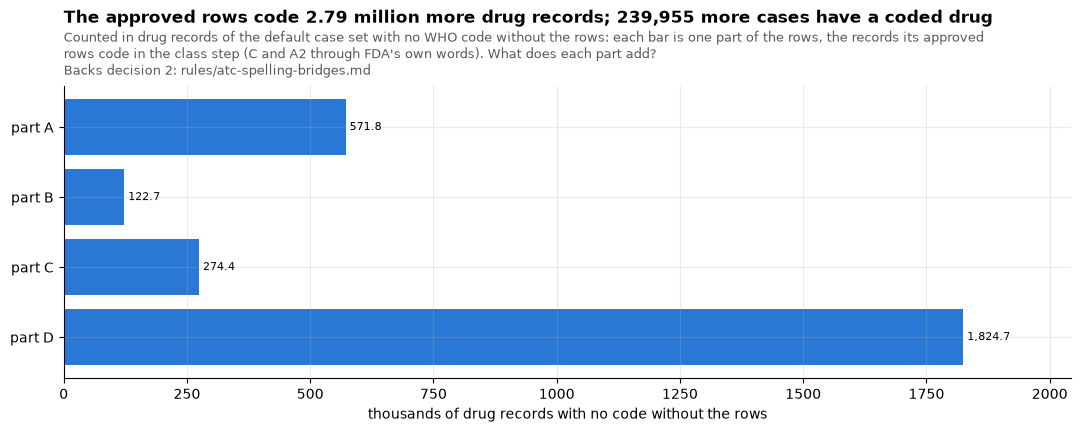

,without the rows,with them
cases with a coded drug,19966198,20206153
cases with a coded suspect drug,19817145,20152187


,part,records_gained,through_a_combination,cases_with_one,records_recoded,as_a_group_class,through_fda_words,rows_approved,sheet_records
0,A,571809,4,447276,47282,0,73295,168,650114
1,B,122709,0,109385,318306,0,13,55,447020
2,C,274411,0,167666,2313,0,274366,14,283130
3,D,1824696,0,1284671,0,1824696,0,134,3222942


In [26]:
if STAGED and WHO_DIR:
    # every record of the default case set whose class the staged rows give or change
    con.execute(f"""CREATE TABLE bridge_rec_T AS
        SELECT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, r.case_key_T, r.substance_T,
               r.atc_code_T AS now_code_T, r.atc_chosen_by_T AS now_by_T,
               x.atc_code_T AS run_code_T, x.atc_chosen_by_T AS run_by_T, x.atc_matched_on_T AS run_on_T
        FROM rec_without_T r JOIN atc_drug_T x USING ({KEY})
        WHERE r.atc_chosen_by_T IS NULL OR (x.atc_chosen_by_T, x.atc_code_T) IS DISTINCT FROM (r.atc_chosen_by_T, r.atc_code_T)""")
    # the staged row each comes through: the word of the code it matched in the run is the row's,
    # or (a WHO combination named with a bridged word) one of its parts; its own word first
    con.register(
        "staged_keys_df",
        staged[staged.state == "approved"][["sheet", "part", "key"]].drop_duplicates(),
    )
    con.execute(f"""CREATE TABLE bridge_owner_T AS
        WITH m AS (SELECT DISTINCT {KEY}, c.atc_ingredient_T AS ingredient FROM bridge_rec_T b JOIN atc_drug_codes_T c USING ({KEY})),
        hit AS (SELECT m.era_T, m.primaryid, m.quarter_T, m.drug_seq, k.sheet, k.part, true AS own_T FROM m JOIN staged_keys_df k ON k.key = m.ingredient
                UNION ALL
                SELECT m.era_T, m.primaryid, m.quarter_T, m.drug_seq, k.sheet, k.part, false
                FROM m, unnest(string_split(m.ingredient, ';')) AS u(piece) JOIN staged_keys_df k ON k.key = u.piece
                WHERE contains(m.ingredient, ';'))
        SELECT DISTINCT * FROM hit QUALIFY own_T = bool_or(own_T) OVER (PARTITION BY era_T, primaryid, quarter_T, drug_seq)""")
    gain = q(f"""WITH o AS (SELECT {KEY}, part, bool_or(own_T) AS own_T FROM bridge_owner_T GROUP BY ALL),
        r AS (SELECT b.*, coalesce(o.part, 'none of the rows') AS part, o.own_T FROM bridge_rec_T b LEFT JOIN o USING ({KEY}))
        SELECT part, count(*) FILTER (WHERE now_by_T IS NULL) AS records_gained,
               count(*) FILTER (WHERE now_by_T IS NULL AND NOT own_T) AS through_a_combination,
               count(DISTINCT case_key_T) FILTER (WHERE now_by_T IS NULL) AS cases_with_one,
               count(*) FILTER (WHERE now_by_T IS NOT NULL) AS records_recoded,
               count(*) FILTER (WHERE now_by_T IS NULL AND run_by_T = 'group_class') AS as_a_group_class,
               count(*) FILTER (WHERE now_by_T IS NULL AND run_on_T IN ('drug_name', 'active_ingredient', 'active_ingredient_set', 'each_active_ingredient')) AS through_fda_words
        FROM r GROUP BY 1 ORDER BY 1""")
    approved_sheets = sheets[sheets.state == "approved"].index
    sheet_totals = (
        SHEET[SHEET.sheet.isin(approved_sheets)]
        .groupby("part")
        .agg(rows_approved=("sheet", "size"), sheet_records=("sheet_records", "sum"))
    )
    gain = gain.merge(sheet_totals, left_on="part", right_index=True, how="left")
    cover = {}
    for v, db in (("without the rows", "without_rows."), ("with them", "")):
        cover[v] = (
            con.execute(f"""SELECT count(DISTINCT r.case_key_T) FILTER (WHERE a.atc_chosen_by_T IS NOT NULL),
            count(DISTINCT r.case_key_T) FILTER (WHERE a.atc_chosen_by_T IS NOT NULL AND r.suspect_T)
            FROM rec_T r LEFT JOIN {db}atc_drug_T a USING ({KEY})""").fetchone()
        )
    COVER = pd.DataFrame(
        cover, index=["cases with a coded drug", "cases with a coded suspect drug"]
    )
    shown = gain[gain.part != "none of the rows"]
    fig, ax = plt.subplots(figsize=(13, 3.8))
    y = np.arange(len(shown))
    b = ax.barh(y, shown.records_gained / 1e3, color=SERIES[0])
    label_bars(ax, b, "{:,.1f}", horizontal=True)
    ax.set_xlim(0, shown.records_gained.max() / 1e3 * 1.12)
    ax.set_yticks(y)
    ax.set_yticklabels([f"part {p}" for p in shown.part])
    ax.invert_yaxis()
    ax.set_xlabel("thousands of drug records with no code without the rows")
    more = COVER.loc["cases with a coded drug"]
    title(
        ax,
        f"The approved rows code {shown.records_gained.sum() / 1e6:.2f} million more drug records; "
        f"{more.iloc[1] - more.iloc[0]:,} more cases have a coded drug",
        "Counted in drug records of the default case set with no WHO code without the rows: each bar is one part of the "
        "rows, the records its approved rows code in the class step (C and A2 through FDA's own words).",
        "What does each part add?",
        backs(2, "atc-spelling-bridges"),
    )
    plt.show()
    display(COVER)
    display(gain)

The records with a code today whose class changes, with the four commonest changes for each sheet row (`sheet_total` is the row's total). Mirena (B1) is a levonorgestrel pill or the morning-after pill today, "can't tell"; with its row it is the hormonal IUD, G02BA03. Calcium with vitamin D (B2), Suboxone (B3) and NuvaRing (B6) likewise get WHO's code for the product. THYROID records (C6) get the pig-thyroid code through their drug name. Glycopyrronium (A4) goes three ways: the inhaler mixes (Breztri, Bevespi and the like) get their own codes, a route picks among its three codes, and records with no route lose the one class they have today, the skin code, and become "can't tell".

In [27]:
if STAGED and WHO_DIR:
    moved = q(f"""WITH r AS (SELECT o.sheet, b.case_key_T,
                         b.now_by_T || ' ' || coalesce(b.now_code_T, '') AS without_the_rows, b.run_by_T || ' ' || coalesce(b.run_code_T, '') AS with_the_rows
                  FROM bridge_rec_T b JOIN bridge_owner_T o USING ({KEY}) WHERE b.now_by_T IS NOT NULL),
        g AS (SELECT sheet, without_the_rows, with_the_rows, count(*) AS records, count(DISTINCT case_key_T) AS cases FROM r GROUP BY 1, 2, 3)
        SELECT g.*, (sum(records) OVER (PARTITION BY sheet))::BIGINT AS sheet_total FROM g
        QUALIFY row_number() OVER (PARTITION BY sheet ORDER BY records DESC) <= 4""")
    display(
        moved.merge(SHEET[["sheet", "what"]])
        .sort_values(["sheet_total", "records"], ascending=False)
        .set_index(["sheet", "what", "sheet_total"])
        .head(30)
    )

without_the_rows      with_the_rows  records   cases
sheet what                                                                   sheet_total                                                       
B1    Mirena, Liletta, Kyleena, Skyla                                        172435            cannot_tell   only_code G02BA03   172435  147489
B2    Caltrate D, Calcichew D3, Adcal-D3                                     75120             cannot_tell     only_code A12AX    75120   71299
B3    Suboxone, Zubsolv                                                      44127             cannot_tell   only_code N07BC51    44127   33104
A4    Robinul, Lonhala, Seebri; and inside Breztri, Bevespi, Trimbow, Ult... 42110             cannot_tell   only_code R03AL11    16713   16101
                                                                             42110        only_code D11AA01       cannot_tell     10084    9202
                                                                             42110             cannot_tell   only_code R03AL04     6944    6144
                                                                             42110        only_code D11AA01      route R03BB06     2923    2754
B6    NuvaRing, EluRyng                                                      25001             cannot_tell   only_code G02BB01    25001   22470
A1    Fish oil, Lovaza, Vascepa                                              3886              cannot_tell   only_code C10AX06     3373    3313
                                                                             3886             route N01BX04  only_code C10AX06      449     413
                                                                             3886         only_code A02BC01  only_code C10AX06       40      38
                                                                             3886             route M02AB01  only_code C10AX06       16      16
C6    Armour Thyroid, Nature-Throid                                          2312              cannot_tell   only_code H03AA05     2312    2272
B4    Os-Cal, calcium with vitamin D                                         1492              cannot_tell     only_code A12AX     1492    1466
A24   Kanrenol, Luvion                                                       523          only_code C03DA03  only_code C03DA02      523     511
A8    Gas-X, simethicone                                                     309          only_code P03AX05  only_code A03AX13      296     284
                                                                             309               cannot_tell   only_code A03AX13       11      10
                                                                             309          only_code A03BB06  only_code A03AX13        2       2
A13   Aldomet                                                                195               cannot_tell   only_code C02LB01      195     192
A5    Refresh, Systane, Miebo                                                120               cannot_tell   only_code S01XA20      108     108
                                                                             120              route S01GA04  only_code S01XA20       10      10
                                                                             120          only_code L01FB01  only_code S01XA20        1       1
                                                                             120              route D11AX27  only_code S01XA20        1       1
B11   Mylanta, Maalox Advanced                                               66                cannot_tell   only_code A02AF02       66      64
B7    Gaviscon, Maalox                                                       63                cannot_tell   only_code A02AD01       45      43
                                                                             63           only_code A02BX13  only_code A02AD01       18      18
A91   Head and Shoulders, DermaZinc                        

What the rows that read FDA's own words give the records they code, by what was matched: the drug name or the active ingredient. The Covid-19 vaccines take their maker's code; human immunoglobulin (C1) and human insulin (A2) take only the class their codes share (J06BA, A10A), the one the group row would give, until the route or the drug name picks one; niacin (C5) is "can't tell" between its cholesterol (C10AD02) and blood-vessel (C04AC01) codes.

In [28]:
if STAGED and WHO_DIR:
    field = q(f"""SELECT o.sheet, b.run_on_T AS matched_on, coalesce(b.run_code_T, b.run_by_T) AS class_given, count(*) AS records,
                         count(DISTINCT b.case_key_T) AS cases
        FROM bridge_rec_T b JOIN bridge_owner_T o USING ({KEY})
        WHERE (o.part = 'C' OR o.sheet = 'A2') AND b.now_by_T IS NULL GROUP BY ALL""")
    display(
        field.merge(SHEET[["sheet", "what", "sheet_codes", "sheet_records"]])
        .sort_values(["sheet", "records"], ascending=[True, False])
        .set_index(["sheet", "what", "sheet_codes", "sheet_records"])
    )

matched_on  class_given  records  cases
sheet what                                         sheet_codes                             sheet_records                                                     
A2    Humulin N, Humulin R, Humulin 70/30, Novolin A10AB01 A10AC01 A10AD01 A10AE01 A10AF01 72142               active_ingredient         A10A    64672  42184
                                                                                           72142                       drug_name         A10A     7929   6298
C1    Hizentra, Privigen, Gammagard, Gamunex       J06BA01 J06BA02                         147940              active_ingredient        J06BA   116000  70388
                                                                                           147940                      drug_name        J06BA    31464  20550
                                                                                           147940         each_active_ingredient  cannot_tell        4      3
C10   Nicotinamide, Nicobion                       A11HA01                                 3228                        drug_name      A11HA01      941    916
                                                                                           3228                active_ingredient      A11HA01      128    120
                                                                                           3228                  each_ingredient  cannot_tell       45     28
C11   Janssen                                      J07BN02                                 2498                active_ingredient      J07BN02     2414   1960
                                                                                           2498                        drug_name      J07BN02       63     58
C14   Novavax                                      J07BN04                                 21                  active_ingredient      J07BN04       20     18
                                                                                           21                          drug_name      J07BN04        1      1
C2    Pfizer-BioNTech, Comirnaty                   J07BN01                                 48289               active_ingredient      J07BN01    43653  24705
                                                                                           48289                       drug_name      J07BN01     3775   2526
C4    Moderna, Spikevax                            J07BN01                                 34208               active_ingredient      J07BN01    32819  18367
                                                                                           34208                       drug_name      J07BN01     1265    593
                                                                                           34208          each_active_ingredient  cannot_tell       43     35
C5    Niaspan, niacin                              C10AD02 C04AC01                         12743                       drug_name  cannot_tell    11758  11486
                                                                                           12743               active_ingredient  cannot_tell     4797   4486
C6    Armour Thyroid, Nature-Throid                H03AA05                                 11728               active_ingredient      H03AA05    11686  10848
                                                                                           11728                       drug_name      H03AA05      547    538
C7    AstraZeneca, Vaxzevria, Covishield           J07BN02                                 7957                active_ingredient      J07BN02     6560   2541
                                                                                           7957                        drug_name      J07BN02      850    170
C8    HyQvia                                       J06BA01                                 5490                active_ingredient      J06BA01     5471   3975
C9    Panc

The three rows held back although approved. C3 would join FDA's word `copper` to the copper IUD (G02BA02); our table keys a word, not a record, so every record whose substance is copper would take the IUD's code too. The first table counts both: the IUD records whose active ingredient FDA writes as copper, and the records whose substance is copper, with the class they have today and with the approved rows (Paragard gets the IUD class G02BA through D13; copper itself the mineral class through D59). D44 and D94 would give a whole body system, C or J, a level the class rules never give; the second table counts the records each would class.

In [29]:
if STAGED and WHO_DIR:
    # C3 would bridge FDA's "copper" to the copper IUD (G02BA02): the table keys it by the word, so
    # every record whose substance is copper would take the IUD's code too, before its group class
    copper = q(f"""SELECT CASE WHEN r.substance_T = 'copper' THEN 'substance copper'
                               ELSE 'an IUD whose active ingredient FDA writes as copper' END AS records_named,
                          coalesce(r.atc_code_T, r.atc_chosen_by_T, 'no code') AS without_the_rows,
                          coalesce(x.atc_code_T, x.atc_chosen_by_T, 'no code') AS with_the_approved_rows, count(*) AS records
        FROM rec_without_T r LEFT JOIN atc_drug_T x USING ({KEY})
        LEFT JOIN (SELECT {KEY}, any_value(lower(prod_ai_norm_T)) AS active FROM drug_latest_T GROUP BY ALL) d USING ({KEY})
        WHERE r.substance_T = 'copper' OR (r.substance_T = 'intrauterine contraceptive device' AND d.active = 'copper')
        GROUP BY ALL ORDER BY records DESC""")
    display(copper)
    # D44 and D94 would give a level-1 class, a whole body system, which no group class is
    level1 = q("""WITH k AS (SELECT sheet, key, atc_code FROM staged_rows_df WHERE sheet IN ('D44', 'D94'))
        SELECT k.sheet, k.key AS group_word, k.atc_code AS would_give, count(*) AS records, count(DISTINCT r.case_key_T) AS cases,
               count(*) FILTER (WHERE r.atc_chosen_by_T IS NULL) AS with_no_code
        FROM rec_without_T r JOIN k ON r.substance_T = k.key GROUP BY ALL ORDER BY k.sheet""")
    display(level1)

,records_named,without_the_rows,with_the_approved_rows,records
0,an IUD whose active ingredient FDA writes as copper,no code,G02BA,45662
1,substance copper,no code,A12CX,1286
2,substance copper,V03AB20,V03AB20,26


,sheet,group_word,would_give,records,cases,with_no_code
0,D44,"cardiovascular drugs, unspecified",C,2182,2152,2182
1,D94,"antimicrobials, unspecified",J,315,312,315


The rows the review turned down: the records each would code (`records`: its word is their substance and they have no code without the approved rows; the check after the next table counts a bridge row's records whether coded or not), the drug names they carry most, the records of mixes naming it, and those the approved rows code anyway (`coded_anyway`, `mixes_coded_anyway`). Part of what the sheet counted has a code today: the sheet was counted before FDA's own words were read.

In [30]:
if STAGED and WHO_DIR:
    # the rows the review turned down: the records each would code, its word being their substance or
    # one of its ingredients, with no code without the rows, and whether the approved rows code them anyway
    no = q(f"""WITH k AS (SELECT DISTINCT sheet, key FROM staged_rows_df WHERE state = 'excluded by the review'),
        t AS (SELECT r.era_T, r.primaryid, r.quarter_T, r.drug_seq, r.case_key_T, k.sheet, r.substance_T = k.key AS whole_T
              FROM rec_without_T r, unnest(list_distinct(string_split(r.substance_T, ';') || [r.substance_T])) AS u(piece)
              JOIN k ON k.key = u.piece WHERE r.atc_chosen_by_T IS NULL),
        r AS (SELECT t.*, x.atc_chosen_by_T IS NOT NULL AS coded_T, any_value(upper(trim(d.drugname))) AS drug_name
              FROM t LEFT JOIN atc_drug_T x USING ({KEY}) JOIN drug_latest_T d USING ({KEY}) GROUP BY ALL),
        names AS (SELECT sheet, drug_name, count(*) AS n, row_number() OVER (PARTITION BY sheet ORDER BY count(*) DESC, drug_name) AS rank
                  FROM r WHERE whole_T GROUP BY sheet, drug_name),
        top AS (SELECT sheet, string_agg(drug_name || ' ' || n, ', ' ORDER BY n DESC) AS top_names FROM names WHERE rank <= 3 GROUP BY 1)
        SELECT sheet, count(*) FILTER (WHERE whole_T) AS records, count(DISTINCT case_key_T) FILTER (WHERE whole_T) AS cases,
               count(*) FILTER (WHERE whole_T AND coded_T) AS coded_anyway, count(*) FILTER (WHERE NOT whole_T) AS in_mixes,
               count(*) FILTER (WHERE NOT whole_T AND coded_T) AS mixes_coded_anyway, any_value(top_names) AS top_names
        FROM r LEFT JOIN top USING (sheet) GROUP BY sheet""")
    no = (
        SHEET[SHEET.sheet.isin(sheets[sheets.state == "excluded by the review"].index)][
            ["sheet", "what", "sheet_codes", "sheet_records"]
        ]
        .merge(no, how="left")
        .sort_values("records", ascending=False)
    )
    display(no.set_index(["sheet", "what"]))

,,sheet_codes,sheet_records,records,cases,coded_anyway,in_mixes,mixes_coded_anyway,top_names
sheet,what,,,,,,,,
D11,"Niaspan, niacin, nicotinamide",A11,68493,65290.0,52862.0,17624.0,186.0,92.0,"NIASPAN 44267, NIACIN 6128, NIACIN. 5629"
A23,Records that say only GOLD,V10AX06,5464,5429.0,4983.0,0.0,23.0,17.0,"GOLD 5278, GOLD (198 AU) COLLOIDAL 25, GOLD AU-198 25"
B9,Rolaids; calcium-magnesium tablets,A12AX,6843,4251.0,4100.0,503.0,0.0,0.0,"ROLAIDS 642, ROLAIDS /00069401/ 471, CA..."
B12,TPN drip feeds,V06DB,2624,2619.0,2328.0,0.0,0.0,0.0,"TPN 2283, AMINO ACIDS\CARBOHYDRATES\MINERALS\VITAMINS 131, TPN [AM..."
D36,"Minerals, Ringer's solution, Lacri-Lube, Pedialyte",A12,3058,2488.0,2407.0,0.0,34528.0,26617.0,"MINERALS 540, LACRI-LUBE 397, MINERALS NOS 357"
D53,"""Allergy medication""",A07EB R01AC R03BC,1574,1572.0,1551.0,0.0,0.0,0.0,"ALLERGY MEDICATION 1129, ALLERGY RELIEF 441, ALLERGY MEDICATION 1"
A46,"Calcium pantothenate, pantothenic acid, panthenol",A11HA30 D03AX03 S01XA12,1561,920.0,887.0,0.0,89.0,3.0,"PANTOTHENIC ACID 421, PANTHENOL 306, VITAMIN B5 47"
A49,"Interferon beta, 1a or 1b not named",L03AB02,1232,893.0,812.0,0.0,0.0,0.0,"INTERFERON BETA 353, INTERFERON BETA NOS 329, INTERFERON BETA - 1B 61"
A58,"Hepa-Merz, Cetornan",A05BA06,884,848.0,749.0,0.0,4.0,2.0,"ORNITHINE ASPARTATE 314, CETORNAN 111, ORNITHINE 109"


What the records of the largest rows turned down are, and of D26 (selenium), approved since on a second look, read from their drug names, routes and reasons; each record counts once, under the first line that fits it. Which records a row counts depends on its part (`counted_over`), on top of the classes this notebook reads. A bridge row (parts A and B) is read on DiAna's substance, which the class step reads before FDA's own words, so it would code or re-code every record of its substance, coded today or not: B9 would also re-code the Rolaids FDA's active ingredient codes today. A group class (part D) is given only where nothing else codes, so a part-D row counts only its records with no code; D26's are the records its own group class now codes. Then C12's words: FDA writes `LEVOTHYROXINE\LIOTHYRONINE` as the active ingredient of pig thyroid as well as of the synthetic pair; the table counts those records by drug name, how many have no code today, and the class the approved rows give them, with what was matched.

In [31]:
if STAGED and WHO_DIR:

    def has(col, words):
        return f"regexp_matches({col}, '{words}')"

    # The records a row would class, today's classes being those this notebook reads (rec_T): a
    # bridge row (parts A and B) is read on DiAna's substance, before FDA's own words, so it would
    # code or re-code every record of its substance, coded today or not; a group class (part D) is
    # given only where nothing else codes, so a part-D row counts its records with no code (or, once
    # built, the records its own group class codes)
    OVER = {
        "A": "every record of its substance",
        "B": "every record of its substance",
        "D": "its records with no code",
    }
    CHECKS = [  # row, then what its records are, read from the record's drug name (n), route (r) or reason (i); the first that fits counts
        (
            "D11",
            [
                (
                    "named Niaspan or another prescription niacin",
                    has("n", "NIASPAN|NIACOR|SLO-NIACIN|NIACIN ER|ENDUR-ACIN|ADVICOR|SIMCOR"),
                ),
                ("named niacin or nicotinic acid", has("n", "NIACIN|NICOTINIC")),
                ("named nicotinamide or vitamin B3", "true"),
            ],
        ),
        ("B9", [("named Rolaids, an antacid", has("n", "ROLAIDS")), ("another name", "true")]),
        (
            "D26",
            [
                (
                    "named Selsun or selenium sulfide, a shampoo",
                    has("n", "SELSUN|SULFIDE|SULPHIDE"),
                ),
                ("another name", "true"),
            ],
        ),
        (
            "A23",
            [
                ("named radioactive gold (198Au)", has("n", "198|AU-|COLLOID")),
                (
                    "for rheumatoid arthritis, or into a muscle",
                    f"{has('i', 'rheumatoid')} OR {has('r', 'INTRAMUSCULAR')}",
                ),
                ("no reason or route that says", "true"),
            ],
        ),
        (
            "D36",
            [
                ("an eye ointment (Lacri-Lube)", has("n", "LACRI")),
                (
                    "a drip, dialysis fluid or trace-element additive",
                    f"{has('n', 'RINGER|ELECTROLYTE|EXTRANEAL|TRACE|SODIUM CHLORIDE|OLIGO')} OR {has('r', 'INTRAVENOUS|INTRAPERITONEAL|PARENTERAL')}",
                ),
                ("an oral rehydration salt", has("n", "PEDIALYTE|DIORALYTE|REHYDRAT")),
                ("named only as minerals", "true"),
            ],
        ),
        (
            "B12",
            [
                (
                    "named TPN, or given by vein",
                    f"{has('n', 'TPN|PARENTERAL')} OR {has('r', 'INTRAVENOUS|PARENTERAL')}",
                ),
                ("another name", "true"),
            ],
        ),
        (
            "A63",
            [
                ("says horse", has("n", "HORSE|EQUINE|ATGAM|LYMPHOGLOBULIN")),
                ("says rabbit", has("n", "RABBIT|THYMOGLOBULIN|GRAFALON|FRESENIUS")),
                ("says neither", "true"),
            ],
        ),
    ]
    found = []
    for row, kinds in CHECKS:
        case = " ".join(f"WHEN {cond} THEN '{label}'" for label, cond in kinds)
        found.append(
            q(f"""WITH o AS (SELECT DISTINCT r.era_T, r.primaryid, r.quarter_T, r.drug_seq FROM rec_T r JOIN staged_rows_df k ON r.substance_T = k.key
                      WHERE k.sheet = '{row}' AND (k.part IN ('A', 'B') OR r.atc_chosen_by_T IS NULL OR r.atc_chosen_by_T = 'group_class')),
            d AS (SELECT {KEY}, upper(string_agg(DISTINCT drugname, ' ')) AS n, upper(coalesce(string_agg(DISTINCT route, ' '), '')) AS r
                  FROM drug_latest_T SEMI JOIN o USING ({KEY}) GROUP BY ALL),
            i AS (SELECT o.era_T, o.primaryid, o.quarter_T, o.drug_seq, lower(string_agg(DISTINCT x.indi_pt, ' ')) AS i FROM o JOIN indi_latest_T x
                  ON x.era_T = o.era_T AND x.primaryid = o.primaryid AND x.quarter_T = o.quarter_T AND x.indi_drug_seq = o.drug_seq GROUP BY ALL)
            SELECT '{row}' AS row, '{OVER[row[0]]}' AS counted_over, CASE {case} END AS the_records_are, count(*) AS records
            FROM d LEFT JOIN i USING ({KEY}) GROUP BY ALL""")
        )
    checks = pd.concat(found)
    checks["%"] = (100 * checks.records / checks.groupby("row").records.transform("sum")).round(1)
    checks = checks.assign(o=checks.row.map({r: k for k, (r, _) in enumerate(CHECKS)})).sort_values(
        ["o", "records"], ascending=[True, False]
    )
    display(
        checks.drop(columns="o")
        .rename(columns={"row": "sheet"})
        .merge(SHEET[["sheet", "what", "sheet_codes"]])
        .set_index(["sheet", "what", "sheet_codes", "counted_over", "the_records_are"])
    )

records     %
sheet what                                               sheet_codes counted_over                  the_records_are                                                
D11   Niaspan, niacin, nicotinamide                      A11         its records with no code      named Niaspan or another prescription niacin        46903  98.4
                                                                                                   named nicotinamide or vitamin B3                      472   1.0
                                                                                                   named niacin or nicotinic acid                        291   0.6
B9    Rolaids; calcium-magnesium tablets                 A12AX       every record of its substance named Rolaids, an antacid                            3789  55.6
                                                                                                   another name                                         3029  44.4
D26   Selenium supplements                               A12CE       its records with no code      another name                                         5142  99.5
                                                                                                   named Selsun or selenium sulfide, a shampoo            25   0.5
A23   Records that say only GOLD                         V10AX06     every record of its substance no reason or route that says                         3767  69.3
                                                                                                   for rheumatoid arthritis, or into a muscle           1582  29.1
                                                                                                   named radioactive gold (198Au)                         83   1.5
D36   Minerals, Ringer's solution, Lacri-Lube, Pedialyte A12         its records with no code      named only as minerals                               1219  49.0
                                                                                                   a drip, dialysis fluid or trace-element additive      493  19.8
                                                                                                   an eye ointment (Lacri-Lube)                          397  16.0
                                                                                                   an oral rehydration salt                              379  15.2
B12   TPN drip feeds                                     V06DB       every record of its substance named TPN, or given by vein                          2540  97.0
                                                                                                   another name                                           79   3.0
A63   ATG (horse)                                        L04AA03     every record of its substance says neither                                          609  83.4
                                                                                                   says horse                                             64   8.8
                                                                                                   says rabbit                                            57   7.8

In [32]:
if STAGED and WHO_DIR:
    thyroid = q(rf"""WITH r AS (SELECT {KEY}, any_value(upper(trim(drugname))) AS n FROM drug_latest_T
                             WHERE lower(regexp_replace(trim(prod_ai), '\s+', ' ', 'g')) = 'levothyroxine\liothyronine' GROUP BY ALL)
        SELECT CASE WHEN n LIKE 'NP THYROID%' THEN 'NP Thyroid, a pig thyroid' WHEN n LIKE 'THYROID%' THEN 'THYROID'
                    WHEN regexp_matches(n, 'ARMOUR|NATURE|WP THYROID|WESTHROID|PORCINE|DESICCATED') THEN 'another pig thyroid'
                    ELSE 'named as levothyroxine with liothyronine (T4 and T3)' END AS drug_name,
               count(*) AS records, count(*) FILTER (WHERE x.atc_chosen_by_T IS NULL) AS with_no_code_without_the_rows,
               coalesce(s.atc_code_T, s.atc_chosen_by_T) AS with_the_rows, s.atc_matched_on_T AS matched_on
        FROM r JOIN rec_without_T x USING ({KEY}) LEFT JOIN atc_drug_T s USING ({KEY})
        GROUP BY 1, 4, 5 ORDER BY 2 DESC""")
    display(thyroid)

,drug_name,records,with_no_code_without_the_rows,with_the_rows,matched_on
0,"NP Thyroid, a pig thyroid",2649,0,cannot_tell,each_ingredient
1,THYROID,2312,0,H03AA05,drug_name
2,named as levothyroxine with liothyronine (T4 and T3),110,0,cannot_tell,each_ingredient
3,THYROID,3,0,cannot_tell,each_ingredient
4,THYROID,1,0,H03AA05,active_ingredient


**What section 9 shows**, one item per chart and table:

- **What each part adds.** *Shows:* in the default case set, the approved rows code 2,793,625 records that have no code without them, A 571,809, B 122,709, C 274,411 and D 1,824,696, and re-code 367,901 (B 318,306, A 47,282, C 2,313); cases with a coded drug go from 19,966,200 to 20,206,155, and with a coded suspect drug from 19,817,147 to 20,152,189. Every approved row is in the mapping files, and no row turned down or held is. D codes 1.4 million records fewer than the sheet counted: FDA's own words, read since the sheet was made, now code many of those records, and a group class is given only where nothing else codes. *Point:* every part adds; the group classes the most. *So what:* decision 2 and decision 3 as built.
- **Re-coded records.** *Shows:* Mirena 172,435, calcium with vitamin D 75,120, Suboxone 44,127, glycopyrronium 42,110 (10,084 of them from the skin code to "can't tell") and NuvaRing 25,001. *Point:* the mixes get WHO's code for the product. *So what:* glycopyrronium with no route loses a wrong class rather than gaining a right one.
- **FDA's own words.** *Shows:* C and A2 code their records through the active ingredient or the drug name: the Pfizer-BioNTech and Moderna vaccines J07BN01, Janssen and AstraZeneca J07BN02; human immunoglobulin (C1, 147,464 records) and human insulin (A2, 72,601) take only the class their codes share (J06BA, A10A), until the route or the drug name picks one; niacin (C5, 16,555) is "can't tell" between its cholesterol and blood-vessel codes. C12 codes almost nothing itself: THYROID's 2,312 records take H03AA05 through C6's drug name, and NP Thyroid's 2,649 stay "can't tell", split into levothyroxine and liothyronine by DiAna's substance, which is read before FDA's words. *Point:* the step that reads FDA's words does what part C waited for. *So what:* NP Thyroid needs a row on DiAna's own substance to take the pig-thyroid code.
- **Held rows.** *Shows:* C3's word would turn the 1,312 records whose substance is copper into the copper IUD, while the 45,662 Paragard records get the IUD class G02BA through D13 anyway; D44 would class 2,182 records as C, D94 315 as J. *Point:* the reasons for holding them stand. *So what:* C3 needs a bridge limited to IUD records; D44 and D94 stay out, since no group class is of level 1.
- **Rows turned down.** *Shows:* each row counted over the records it would class: a bridge row (parts A and B) every record of its substance, coded today or not, and a group row (part D) only its records with no code. 98.4% of the 47,666 vitamin B3 records with no code are named Niaspan or another prescription niacin, 97.0% of the drip feeds are given by vein, 83.4% of the antilymphocyte globulin records name neither horse nor rabbit, and 1.5% of gold's name radioactive gold (29.1% are for rheumatoid arthritis or into a muscle). Rolaids are 55.6% of the 6,818 calcium-with-magnesium records B9 would code or re-code (3,789), more than half: the 32.8% counted before was of the 4,251 records with no code only, but B9 is read on DiAna's substance before FDA's own words, so it would also re-code the 2,896 Rolaids records FDA's active ingredient codes today. Drips, dialysis fluids and trace elements (19.8%) with Lacri-Lube eye ointment (16.0%) are 36% of the 2,488 mineral records with no code (D36), not most. Selenium (D26), approved on a second look, is built: Selsun shampoo is 25 (0.5%) of the 5,167 records it codes. *Point:* the reasons for a no hold for vitamin B3, the drip feeds, antilymphocyte globulin, gold and calcium with magnesium; D36's has faded but the row stays out, and D26's had gone. *So what:* B9 and D36 stay turned down; D26 is built with part D.

The approved rows add a class to 2.8 million drug records and 240,000 cases, with FDA's own words now doing what part C waited for. The held rows and the rows turned down are right to wait; selenium, approved on a second look, is now built, and calcium with magnesium and minerals stay out.

## 10 · Skin care: the classes FDA's active ingredient gives it

DiAna writes `skin care` for cosmetics and skin products and names no substance, and our list gives the word no group class. The class step then reads FDA's own words on the record (rule `atc-index`), and for acne washes such as Proactiv FDA's active ingredient names what they hold: salicylic acid, sulfur, benzoyl peroxide. Each takes WHO's own code for that ingredient. WHO's only skin code for salicylic acid is D01AE12, under "Other antifungals for topical use" (its other code, S01BC08, is for the eye), so an acne wash counts among the antifungals for the skin (D01). The cell counts, in drug records of the default case set whose substance is skin care, those FDA's active ingredient gives a class: by the ingredient matched and the code chosen, by FDA's role, and the share skin care's salicylic acid makes of every D01 record, with suspect drugs only (PS and SS, the class filter's default, decision 8) and with every role (concomitant drugs ticked).

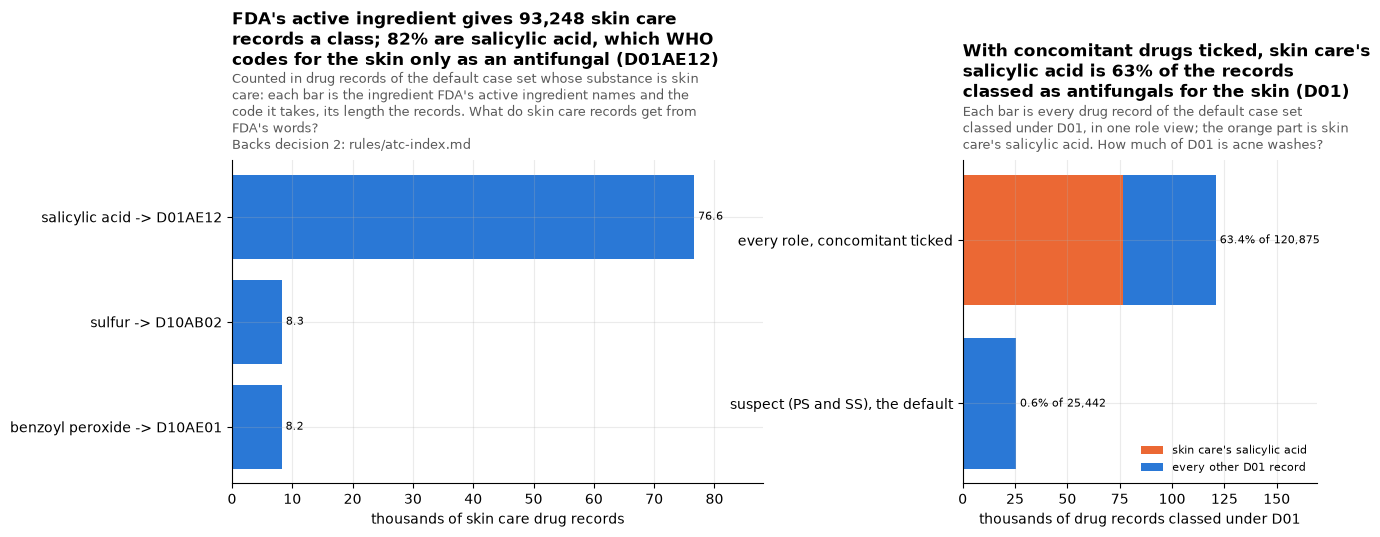

skin care classed by FDA's active ingredient: 93,248 records, 93,119 named Proactiv; 2,598 more stay can't tell


,ingredient,code,who_class,records,proactiv
0,salicylic acid,D01AE12,Other antifungals for topical use,76620,76620
1,sulfur,D10AB02,Preparations containing sulfur,8268,8268
2,benzoyl peroxide,D10AE01,Peroxides,8231,8231
3,dexpanthenol,A11HA30,Other plain vitamin preparations,48,0
4,trolamine,D03AX12,Other cicatrizants,38,0
5,dexpanthenol,D03AX03,Other cicatrizants,34,0
6,dexpanthenol,S01XA12,Other ophthalmologicals,9,0


,fda_role,records,proactiv
0,C,92449,92359
1,SS,544,505
2,PS,255,255


,drugs_counted,d01_records,skin_care_salicylic_acid,%
0,"suspect (PS and SS), the default",25442,152,0.6
1,"every role, concomitant ticked",120875,76620,63.4


In [33]:
# Every record whose substance is DiAna's "skin care" and which FDA's active ingredient gives a class
# (rule atc-index: FDA's own words are read where the substance has no code), Proactiv named or not
FDA_ACTIVE = "('active_ingredient', 'active_ingredient_set', 'each_active_ingredient')"
con.execute(f"""CREATE OR REPLACE TABLE skin_T AS
    SELECT r.*, bool_or(upper(d.drugname) LIKE '%PROACTIV%') AS proactiv_T
    FROM rec_T r JOIN drug_latest_T d USING ({KEY})
    WHERE r.substance_T = 'skin care' AND r.atc_matched_on_T IN {FDA_ACTIVE} GROUP BY ALL""")
SKIN = con.execute("""SELECT count(*) FILTER (WHERE atc_chosen_by_T <> 'cannot_tell'),
    count(*) FILTER (WHERE atc_chosen_by_T <> 'cannot_tell' AND proactiv_T),
    count(*) FILTER (WHERE atc_chosen_by_T = 'cannot_tell') FROM skin_T""").fetchone()
# the ingredient matched and the code chosen, with WHO's name for the code's class one level up
skin_codes = q(f"""SELECT c.atc_ingredient_T AS ingredient, c.atc_code_T AS code, k.atc_name_T AS who_class,
        count(*) AS records, count(*) FILTER (WHERE s.proactiv_T) AS proactiv
    FROM skin_T s JOIN atc_drug_codes_T c USING ({KEY}) JOIN {NAMES_OF} k ON k.atc_code_T = left(c.atc_code_T, 5)
    WHERE c.atc_chosen_T GROUP BY ALL ORDER BY records DESC""")
assert skin_codes.records.sum() == SKIN[0], "one chosen code per classed record"
skin_roles = q("""SELECT role_cod AS fda_role, count(*) AS records, count(*) FILTER (WHERE proactiv_T) AS proactiv
    FROM skin_T WHERE atc_chosen_by_T <> 'cannot_tell' GROUP BY 1 ORDER BY 2 DESC""")
# every record classed under D01, suspect drugs only and every role, and skin care's salicylic acid among them
skin_d01 = q("""SELECT v.view_T AS drugs_counted, count(*) AS d01_records,
        count(*) FILTER (WHERE r.substance_T = 'skin care' AND r.atc_code_T = 'D01AE12') AS skin_care_salicylic_acid
    FROM rec_T r JOIN (VALUES ('suspect (PS and SS), the default', true), ('every role, concomitant ticked', false)) v(view_T, suspect_only_T)
      ON r.suspect_T OR NOT v.suspect_only_T
    WHERE r.atc_code_T LIKE 'D01%' GROUP BY 1 ORDER BY 2""")
skin_d01["%"] = (100 * skin_d01.skin_care_salicylic_acid / skin_d01.d01_records).round(1)

fig, (ax, bx) = plt.subplots(
    1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.45}
)
shown = skin_codes.head(3)  # the rest are under a hundred records each, in the table below
y = np.arange(len(shown))
b = ax.barh(y, shown.records / 1e3, color=SERIES[0])
label_bars(ax, b, "{:,.1f}", horizontal=True)
ax.set_xlim(0, shown.records.max() / 1e3 * 1.15)
ax.set_yticks(y)
ax.set_yticklabels([f"{r.ingredient} -> {r.code}" for r in shown.itertuples()])
ax.invert_yaxis()
ax.set_xlabel("thousands of skin care drug records")
top = skin_codes.iloc[0]
title(
    ax,
    f"FDA's active ingredient gives {SKIN[0]:,} skin care records a class; "
    f"{top.records / SKIN[0]:.0%} are salicylic acid, which WHO codes for the skin only as an antifungal ({top.code})",
    "Counted in drug records of the default case set whose substance is skin care: each bar is the ingredient "
    "FDA's active ingredient names and the code it takes, its length the records.",
    "What do skin care records get from FDA's words?",
    backs(2, "atc-index"),
)
y = np.arange(len(skin_d01))
other = skin_d01.d01_records - skin_d01.skin_care_salicylic_acid
b1 = bx.barh(
    y, skin_d01.skin_care_salicylic_acid / 1e3, color=SERIES[1], label="skin care's salicylic acid"
)
b2 = bx.barh(
    y,
    other / 1e3,
    left=skin_d01.skin_care_salicylic_acid / 1e3,
    color=SERIES[0],
    label="every other D01 record",
)
for i, (n, pct) in enumerate(zip(skin_d01.d01_records, skin_d01["%"], strict=True)):
    bx.text(n / 1e3, i, f" {pct:.1f}% of {n:,}", va="center", fontsize=8)
bx.set_xlim(0, skin_d01.d01_records.max() / 1e3 * 1.4)
bx.set_yticks(y)
bx.set_yticklabels(skin_d01.drugs_counted)
bx.set_xlabel("thousands of drug records classed under D01")
bx.legend(loc="lower right", fontsize=8, frameon=False)
title(
    bx,
    f"With concomitant drugs ticked, skin care's salicylic acid is {skin_d01['%'].iloc[-1]:.0f}% of the "
    "records classed as antifungals for the skin (D01)",
    "Each bar is every drug record of the default case set classed under D01, in one role view; the orange part is skin care's salicylic acid.",
    "How much of D01 is acne washes?",
)
plt.show()
print(
    f"skin care classed by FDA's active ingredient: {SKIN[0]:,} records, {SKIN[1]:,} named Proactiv; "
    f"{SKIN[2]:,} more stay can't tell"
)
display(skin_codes, skin_roles, skin_d01)

**What section 10 shows**, one item per chart:

- **What skin care gets from FDA's words.** *Shows:* in the default case set, FDA's active ingredient gives 93,248 records whose substance is skin care a class, 93,119 of them named Proactiv: salicylic acid 76,620 records, D01AE12 (WHO's only skin code for it, under "Other antifungals for topical use"); sulfur 8,268, D10AB02; benzoyl peroxide 8,231, D10AE01, both anti-acne classes; 2,598 more stay "can't tell". By FDA's role, 92,449 are concomitant (C), 544 secondary suspect (SS) and 255 primary suspect (PS). *Point:* each is WHO's own code for an ingredient FDA names, so the classes are right as built; Proactiv is nearly all of them. *So what:* decision 2 as built, FDA's own words first; nothing changes.
- **How much of D01 is acne washes.** *Shows:* with suspect drugs only, the class filter's default, skin care's salicylic acid is 152 of the 25,442 D01 records (0.6%); with concomitant drugs ticked, 76,620 of 120,875 (63.4%), about two thirds. *Point:* WHO files skin salicylic acid under antifungals, so acne washes fill D01 once concomitant drugs are counted, though they barely touch the default view. *So what:* the methods page should say so (the proposal below).

**PROPOSAL, not built, for the review to decide.** One line for the methods page: "WHO files salicylic acid for the skin under antifungals (D01AE12), so acne washes such as Proactiv count there: with concomitant drugs ticked, they are about two thirds of the D01 records." No class changes.

FDA's active ingredient gives 93,248 skin care records, nearly all Proactiv, WHO's own codes for salicylic acid, sulfur and benzoyl peroxide, so they stay as built. Because WHO's only skin code for salicylic acid is an antifungal one, those acne washes are about two thirds of the D01 records when concomitant drugs are counted, and almost none in the default suspect view.